<a href="https://colab.research.google.com/github/hssitja/Escritos/blob/main/simulador_FOF_RPPS_v10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulador FOF da previdência municipal
**Segregação de massas e dessegregação · TCE/RS (CEPREV/SIP) · palestra de 14/10/2026**

Notebook único, para rodar no Colab de cima para baixo:

1. **Hipóteses** — todos os parâmetros num só lugar, com fonte e status.
2. **Dados fiscais** — RCL, despesa com pessoal e dívida dos municípios gaúchos (base TCE/RS, 2016–2025).
3. **Motor** — demografia, avaliação atuarial (método agregado), caixa dos fundos e apuração fiscal.
4. **Município A** — calibração e teste contra o passado (2023–2025).
5. **Cenários** — sem segregação, segregação, segregação com dessegregação (exibição até 2050).

**As projeções são condicionais:** mostram o que acontece *se* as hipóteses se verificarem. Não são previsões.
Os municípios da apresentação são modelos anônimos, com ordens de grandeza tiradas de dados reais.

**Versão 10 (12/10):** Município A incluído na seção 9 e no painel síntese; D com o motor explícito — custo de
um novo servidor por regime (a suplementar incide sobre a folha nova no plano vigente, não no FC segregado), troca de
outras despesas e reinvestimento da economia previdenciária mantendo o comprometimento do plano vigente.

**Versão 9 (11/10):** troca de metade das "outras despesas com pessoal" por servidores efetivos G3, com
orçamento neutro (custo = salário + patronal normal + suplementar), foco no Município D; E sem o cenário de 2032;
gráficos do Município A no mesmo padrão dos demais (comparativo, composição por cenário e servidores).

**Versão 8 (11/10):** segregação com o FC em equilíbrio (fim do degrau); dessegregação só com superávit gerado
depois; aporte limitado à capacidade de pagamento (o não pago fica registrado e não entra no fundo); RCL e
vencimentos crescem à mesma taxa (cenário neutro de 1% a.a.), com paridade da G1 pelo aumento geral; migração para
aporte só da parcela fora de educação e saúde (50%); C sem o "plano reequacionado"; E sem plano até a segregação;
números de apoio por município; robustez com os novos cenários de RCL e salários.

**Versão 7 (11/10):** regra do TCE — benefícios pagos só com contribuições e rendimentos; o estoque do fundo só pode ser usado após o equilíbrio atuarial (o que faltar é insuficiência, dentro da DTP); calibração fiscal desconta a insuficiência do ano-base; gráficos e tabela de "quem paga a conta" (servidores a menos e custo em servidores equivalentes); fontes maiores, legendas abaixo e limites da LRF na legenda (sem sobreposição); projeções do A sem a expansão de 1,5% a.a.

**Versão 6 (11/10):** gráficos na paleta da apresentação (fundo branco, azul-marinho #002060, laranja #D65D2A; FC verde, FR vermelho); função `salvar()` exporta PNG para os slides; Município C atualizado para o DRAA 2026; histórico de E (2022 × 2026).

**Versão 5 (11/10):** seção 9 — os cinco municípios da palestra a partir dos DRAA em PDF; planos por aporte
crescente, plano vigente fixo e ausência de plano; calibração do passivo ao DRAA; CADPREV desligado.

**Versão 4 (12/10):** seção 8 — municípios a partir do pipeline do CADPREV, validação contra os DRAA em PDF,
exclusão dos parcelamentos dos ativos garantidores e alerta de variação atípica dos ativos; início já segregado.

**Versão 3 (12/10):** RCL observada no teste contra o passado; métrica de comprometimento total
(DTP + aporte); crescimento dos benefícios separado entre avaliação (hipótese do DRAA) e fluxo (paridade
observada); painel de servidores; gráficos até 2050; tabela de teste contra o passado com a insuficiência do FR.

## 0. Bibliotecas e paleta

In [1]:
import glob, json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paleta da apresentação (IV Seminário de RPPS do TCE-RS): fundo branco, azul-marinho, laranja de destaque.
AZUL, LARANJA, AMARELO = "#002060", "#D65D2A", "#FFC000"
VERDE_FC, VERMELHO_FR = "#375623", "#CC3300"          # convenção dos slides: FC verde, FR vermelho
MARROM, CINZA, GRADE, FUNDO = "#C55A11", "#7F7F7F", "#D9D9D9", "#FFFFFF"
TEXTO = AZUL
LIMITE = "#C00000"
SERIES = [AZUL, LARANJA, VERDE_FC, "#BF9000", CINZA, VERMELHO_FR]
CORES = {"folha": AZUL, "patronal": "#8497B0", "outras": "#BFBFBF",
         "suplementar": MARROM, "insuficiencia": VERMELHO_FR, "aporte": AMARELO}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 15, "font.family": "sans-serif",
    "axes.labelsize": 15, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13,
    "figure.constrained_layout.use": True,
    "text.color": AZUL, "axes.labelcolor": AZUL, "axes.titlecolor": AZUL,
    "xtick.color": AZUL, "ytick.color": AZUL, "axes.edgecolor": GRADE,
    "axes.facecolor": FUNDO, "figure.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .8, "grid.linestyle": "-", "grid.color": "#EDEDED",
    "legend.labelcolor": AZUL, "patch.linewidth": 0, "hatch.linewidth": 1.2})

PASTA_GRAFICOS = "/content/drive/MyDrive/TCE/rpps_rs/graficos"


def salvar(nome, fig=None):
    """Salva a figura atual em PNG (alta resolução, 16:9) para colar nos slides."""
    import re, unicodedata
    nome = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode()
    nome = re.sub(r"[^A-Za-z0-9]+", "_", nome).strip("_")
    os.makedirs(PASTA_GRAFICOS, exist_ok=True)
    (fig or plt.gcf()).savefig(f"{PASTA_GRAFICOS}/{nome}.png", dpi=220, bbox_inches="tight")


def titulo(ax, principal, sub=None):
    """Título no padrão dos slides: principal em azul-marinho, subtítulo em laranja itálico."""
    ax.set_title(principal, loc="left", color=AZUL, weight="bold", fontsize=20, pad=34 if sub else 12)
    for t_ in [t_ for t_ in ax.texts if t_.get_gid() == "subtitulo"]:   # evita sobrepor subtítulos
        t_.remove()
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, color=LARANJA, style="italic", fontsize=15,
                gid="subtitulo")


FIG = (14, 7.2)          # 16:9 aproximado, para ocupar um slide inteiro


def limites_lrf(ax, p, alerta=False):
    """Linhas dos limites da LRF, identificadas na legenda (sem rótulos sobre o gráfico)."""
    if alerta:
        ax.axhline(p["lim_alerta"] * 100, color=LIMITE, lw=1.4, ls=":",
                   label=f"Alerta ({p['lim_alerta']*100:.1f}%)".replace(".", ","))
    ax.axhline(p["lim_prud"] * 100, color=LIMITE, lw=1.6, ls="--",
               label=f"Prudencial ({p['lim_prud']*100:.1f}%)".replace(".", ","))
    ax.axhline(p["lim_legal"] * 100, color=LIMITE, lw=1.8, ls="-",
               label=f"Legal ({p['lim_legal']*100:.0f}%)")


def legenda_abaixo(ax, ncol=3):
    h, l = ax.get_legend_handles_labels()
    ax.legend(h, l, frameon=False, ncol=ncol, loc="upper center", bbox_to_anchor=(.5, -.10),
              handlelength=2.2, columnspacing=1.6)


def sombrear_bloqueio(ax, df, cor="#F4CCCC", rotulo="Reposição restrita (DTP acima do prudencial)"):
    """Sombreia os anos em que a reposição de servidores está restrita."""
    primeiro = True
    for a in df.loc[df.bloqueio, "ano"]:
        ax.axvspan(a - .5, a + .5, color=cor, alpha=.55, lw=0, zorder=0,
                   label=rotulo if primeiro else None)
        primeiro = False

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Hipóteses

Todos os números do simulador estão em `BASE`. Para criar um cenário, copie e altere só o que muda:
`p = cenario(BASE, segregar=True)`.

Status: **CONFIRMADO** (norma ou dado verificado) · **A_VALIDAR** (confirmar com o CEPREV) ·
**MODELAGEM** (escolha nossa) · **CALIBRAR** (vem do DRAA ou da base do TCE) · **PROPOSIÇÃO** (regra que propomos).

In [2]:
BASE = dict(
    # ---------------- ente (âncora fiscal) ----------------
    ano_base=2026,
    rcl0=None,              # RCL do ano-base, em R$ do ano-base (base TCE); se None, deduzida de dtp_rcl0
    rcl_obs=None,           # {ano: RCL real} observada após o ano-base (teste contra o passado)
    dtp_rcl0=0.47,          # DTP / RCL no ano-base, usada para deduzir a RCL quando rcl0 = None
    outras_pessoal=0.0,     # despesa com pessoal fora do RPPS, em fração da RCL
    g_rcl=0.01,             # crescimento real da RCL nas projeções
    g_rcl_cenario=0.01,     # se não None, substitui o histórico nas projeções (ver nota em calibrar_fiscal)
    g_geral=None,           # aumento real geral dos vencimentos; None = igual ao crescimento da RCL
    teto_comprometimento=0.60,  # capacidade de pagamento: DTP + aporte não ultrapassa esta fração da RCL
    teto_g_rcl=0.02,        # teto de sustentabilidade (Anexo VI, art. 50, § 3º)
    dcl_rcl=0.0,            # dívida consolidada líquida / RCL, sem o déficit atuarial
    lim_alerta=0.486, lim_prud=0.513, lim_legal=0.54,   # Executivo municipal (LRF)
    lim_endiv=1.2,          # Res. SF 40/2001, art. 3º, II
    incluir_FR_endiv=True,  # soma o déficit do fundo em repartição no teste de endividamento

    # ---------------- massa inicial (DRAA) ----------------
    n_ativos=1000, n_apos=350, n_pens=100,
    idade_ativos=44.0, dp_ativos=9.0,     # média e desvio da distribuição etária
    idade_benef=68.0, dp_benef=10.0,
    idade_entrada=28,
    sal_mensal=5000.0, ben_mensal=4500.0, parcelas=13,
    sal_entrada_rel=0.80,                 # salário de ingresso / salário médio do ano-base
    g_sal_entrada=None,                   # crescimento real do salário de ingresso; None = acompanha a RCL

    # ---------------- regras por geração: G1 (antes de 2004), G2, G3 (após 13/11/2019) ----------------
    corte_G1=2004, corte_G3=2019,
    idade_apos=(57, 60, 63),
    repos=(1.00, 0.80, 0.70),             # integralidade; média 80%; média 70%
    teto_rgps=106_000.0,                  # anual

    # ---------------- atuarial ----------------
    juros=0.045, retorno=0.045,
    g_sal=0.01,                           # crescimento real dos salários do DRAA (carreira + aumento geral)
    g_carreira=None,                      # progressão de carreira; None = g_sal − 1% (aumento geral implícito no DRAA)
    g_ben_G1=None,                        # crescimento real dos benefícios da G1 (paridade); None = aumento geral
    g_ben_aval=0.0,                       # crescimento real dos benefícios na AVALIAÇÃO (hipótese do DRAA)
    comprev=0.0,                          # compensação a receber, fração dos benefícios
    contrib_inat=0.0,                     # contribuição efetiva de inativos, fração dos benefícios

    # ---------------- custeio ----------------
    aliq_serv=0.14,
    piso_pat=0.14, teto_pat=0.28,         # Lei 9.717/1998, art. 2º
    pat0=None,                            # patronal normal em lei no ano-base (DRAA); None = calculada
    aliq_sup0=None,                       # suplementar em lei no ano-base; None = calculada pelo déficit
    pat_FR=None,                          # patronal do fundo em repartição; None = a vigente na segregação
    pat_FC_seg=None,                      # patronal do FC fixada na segregação (DRAA); None = calculada
    reduz_pat=False,                      # superávit NÃO reduz a alíquota (posição técnica)
    prazo=35,                             # Anexo VI, art. 43, I
    carencia=5,                           # aporte de t disponível em t+5
    repos_bloqueio=0.5,                   # fração das saídas reposta acima do prudencial
    frac_aporte=0.5,                      # fração do custeio suplementar que pode migrar para aporte
                                          # (o resto — educação e saúde — fica em alíquota, pelos mínimos)
    saque_so_com_equilibrio=True,         # TCE: ativos só pagam benefícios após o equilíbrio atuarial
    quadro_referencia=None,               # servidores necessários; None = quadro do ano-base (constante)
    reposicao_extra=0.0,                  # ingressos adicionais por ano, fração do quadro (expansão)
    forma0="aliquota",                    # forma do plano vigente no ano-base: 'aliquota' ou 'aporte'
    aporte0=None,                         # aporte anual vigente no ano-base (R$), se forma0 = 'aporte'
    prazo0=None,                          # anos restantes do plano vigente; None = prazo integral
    plano_fixo=False,                     # True: mantém o pagamento da lei vigente (não reequaciona)
    cresc_pagamento=0.0,                  # crescimento real anual do aporte do plano vigente (escalonado)
    sem_plano=False,                      # True: não há plano de amortização em lei
    ano_plano=None,                       # h em que um plano é instituído (cenário); None = nunca
    troca_outras=0.0,                     # fração de "outras despesas com pessoal" trocada por servidores efetivos
    troca_rampa=5,                        # anos para concluir a troca (só avança sem reposição restrita)
    ano_troca=1,                          # h em que a troca começa
    reinvestir=False,                     # reinveste em nomeações a economia frente a um orçamento-alvo
    alvo_comprometimento=None,            # {ano: (DTP + aporte)/RCL} do cenário de referência (orçamento constante)
    folga_prudencial=0.01,                # o reinvestimento para 1 p.p. abaixo do limite prudencial

    # ---------------- estado inicial do RPPS ----------------
    ativos0=None,                         # ativos garantidores (R$); se None, ic0 × PMBC
    ic0=0.30,

    # ---------------- segregação ----------------
    segregar=False, ano_seg=1,
    seg_equilibrada=True,                 # na segregação, o FC nasce em equilíbrio: recebe os beneficiários
                                          # mais idosos do FR até consumir o superávit inicial
    corte_idade_ativos=46,                # ativos com idade >= corte vão ao FR
    benef_FR_idade_max=200,               # beneficiários abaixo desta idade vão ao FR (200 = todos)
    ja_segregado=False,                   # True: o ente já é segregado no ano-base (massa do FR em massa_FR)
    massa_FR=None,                        # dict com n_ativos, n_apos, n_pens, idade_ativos, idade_benef,
                                          # sal_mensal, ben_mensal do FR (DRAA/CADPREV)

    # ---------------- dessegregação ----------------
    desseg=False,
    n_superavits=1,                       # norma vigente: 3 · proposta: 1
    D_max=25,

    # ---------------- reforma (anos somados às idades de aposentadoria) ----------------
    reforma_anos=(0, 0, 0), reforma_ano=0, reforma_rampa=0,
    ajuste_idade=0.0,                     # anos somados a todas as idades de aposentadoria
    fator_passivo=1.0,                    # multiplica os VABF na avaliação (calibração ao DRAA)

    horizonte=48,                         # simulação completa (art. 50, § 2º)
    ano_max_grafico=2050,                 # exibição nos gráficos
)

STATUS = {
    "rcl0": ("Base fiscal TCE/RS (RCL do RREO)", "CALIBRAR"),
    "rcl_obs": ("Base fiscal TCE/RS — só no teste contra o passado", "CALIBRAR"),
    "dtp_rcl0": ("Média aproximada no RS; substituído pela base TCE", "CALIBRAR"),
    "g_rcl": ("Variação real média da RCL (Anexo VI, art. 50, § 1º)", "CALIBRAR"),
    "teto_g_rcl": ("Anexo VI, art. 50, § 3º (valor: escolha nossa)", "A_VALIDAR"),
    "g_rcl_cenario": ("Cenário neutro: RCL e vencimentos crescem juntos (o histórico só mede a RCL)", "MODELAGEM"),
    "g_geral": ("Vencimentos acompanham a receita no longo prazo", "MODELAGEM"),
    "teto_comprometimento": ("Capacidade de pagamento: aporte acima disso não é pago", "MODELAGEM"),
    "g_carreira": ("DRAA: crescimento salarial menos o aumento geral", "MODELAGEM"),
    "frac_aporte": ("Folha de educação e saúde fica em alíquota (mínimos de MDE e ASPS)", "MODELAGEM"),
    "seg_equilibrada": ("Estudo de segregação dimensiona o corte para o FC nascer em equilíbrio", "MODELAGEM"),
    "outras_pessoal": ("DTP observada − folha e encargos do RPPS", "CALIBRAR"),
    "dcl_rcl": ("Base fiscal TCE/RS (RGF)", "CALIBRAR"),
    "lim_alerta": ("LRF, art. 59, § 1º, II", "A_VALIDAR"),
    "lim_prud": ("LRF, art. 22, parágrafo único", "A_VALIDAR"),
    "lim_legal": ("LRF, art. 20, III, b", "A_VALIDAR"),
    "lim_endiv": ("Res. SF 40/2001, art. 3º, II; Anexo VI, art. 51", "CONFIRMADO"),
    "incluir_FR_endiv": ("Leitura do Anexo VI, art. 50, VI", "A_VALIDAR"),
    "idade_apos": ("DRAA: idade média projetada para aposentadoria", "CALIBRAR"),
    "repos": ("Lei 10.887/2004; EC 103/2019 (aproximações)", "A_VALIDAR"),
    "juros": ("DRAA", "CALIBRAR"), "retorno": ("= juros no cenário-base", "MODELAGEM"),
    "g_sal": ("DRAA", "CALIBRAR"),
    "g_ben_G1": ("Paridade: benefícios da G1 acompanham o aumento geral", "MODELAGEM"),
    "g_ben_aval": ("DRAA: crescimento real dos benefícios (em geral 0%)", "CALIBRAR"),
    "sal_entrada_rel": ("DRAA / hipótese", "CALIBRAR"),
    "g_sal_entrada": ("Nível salarial acompanha a receita", "MODELAGEM"),
    "piso_pat": ("Lei 9.717/1998, art. 2º", "A_VALIDAR"),
    "teto_pat": ("Lei 9.717/1998, art. 2º", "A_VALIDAR"),
    "pat0": ("DRAA do ano-base", "CALIBRAR"),
    "aliq_sup0": ("Receitas estimadas do DRAA do ano-base", "CALIBRAR"),
    "pat_FR": ("DRAA após a segregação", "CALIBRAR"),
    "pat_FC_seg": ("DRAA após a segregação", "CALIBRAR"),
    "reduz_pat": ("Posição técnica Aline/Henrique", "MODELAGEM"),
    "prazo": ("Anexo VI, art. 43, I", "CONFIRMADO"),
    "carencia": ("Portaria MPS 746/2011; Portaria 1.467, art. 55, § 8º, III", "CONFIRMADO"),
    "repos_bloqueio": ("LRF, art. 22, par. único, IV (educação, saúde, segurança)", "MODELAGEM"),
    "saque_so_com_equilibrio": ("Entendimento TCE/RS: equilíbrio financeiro e atuarial (CF, art. 40)", "CONFIRMADO"),
    "quadro_referencia": ("Hipótese: serviço exige ao menos o quadro do ano-base", "MODELAGEM"),
    "reposicao_extra": ("Expansão do quadro observada (DRAA)", "CALIBRAR"),
    "ic0": ("Parâmetro de partida", "CALIBRAR"),
    "ano_seg": ("Segregação no 2º exercício", "MODELAGEM"),
    "n_superavits": ("Norma: 3 (art. 62, § 3º, I) · proposta: 1", "PROPOSIÇÃO"),
    "D_max": ("Art. 62, § 3º", "CONFIRMADO"),
    "troca_outras": ("Cenário: contratos e afins substituídos por servidores efetivos (G3), orçamento neutro", "MODELAGEM"),
    "troca_rampa": ("Hipótese de implantação gradual", "MODELAGEM"),
    "reinvestir": ("Cenário: economia previdenciária vira nomeação, com o mesmo comprometimento da RCL", "MODELAGEM"),
    "folga_prudencial": ("Prudência: nomeações não levam a DTP ao limite prudencial", "MODELAGEM"),
}

REGRAS_FIXAS = pd.DataFrame([
    ("Aporte não integra a despesa com pessoal", "LRF; LC 178/2021; NT SEI nº 18.162/2021/ME", "CONFIRMADO"),
    ("Insuficiência integra a despesa com pessoal", "LRF, art. 19, § 1º, VI, c, e § 3º", "CONFIRMADO"),
    ("Todos os recursos ao fundo em capitalização na segregação", "Portaria 1.467, art. 59, VI", "CONFIRMADO"),
    ("Margem: maior de AG×0,87−PM e AG×(0,75+0,01×D)−PM", "Portaria 1.467, art. 62, § 3º", "CONFIRMADO"),
    ("Efeitos dos limites da LRF em t+1", "Decisão de modelagem", "MODELAGEM"),
    ("Migração para aporte quando a DTP passa do prudencial: só a parcela fora de educação e saúde; irreversível",
     "Decisão de modelagem", "A_VALIDAR"),
    ("Aporte limitado à capacidade de pagamento; o que não é pago não entra no fundo", "Decisão de modelagem", "MODELAGEM"),
    ("Método de financiamento agregado", "Predominante nos DRAA do RS", "CONFIRMADO"),
    ("Patronal fixada na segregação; depois não cai com superávit", "Decisão de modelagem", "MODELAGEM"),
    ("Benefícios pagos só com contribuições + rendimentos; estoque intocável até o equilíbrio atuarial",
     "Entendimento TCE/RS (CF, art. 40)", "CONFIRMADO"),
    ("Tábua Gompertz simplificada, fechada aos 100 anos", "Simplificação didática (DRAA: AT-2000)", "MODELAGEM"),
], columns=["regra", "fonte", "status"])


def cenario(base, nome=None, **alteracoes):
    p = dict(base)
    for k in alteracoes:
        if k not in p:
            raise KeyError(f"parâmetro inexistente: {k}")
    p.update(alteracoes)
    p["nome"] = nome or base.get("nome", "cenario")
    return p


def ver_hipoteses(p):
    linhas = [(k, v, *STATUS.get(k, ("", ""))) for k, v in p.items() if k not in ("nome", "rcl_obs")]
    return pd.DataFrame(linhas, columns=["parametro", "valor", "fonte", "status"])


def diferencas(p, ref):
    return pd.DataFrame([(k, ref.get(k), v) for k, v in p.items()
                         if k not in ("nome", "rcl_obs") and str(ref.get(k)) != str(v)],
                        columns=["parametro", "referencia", "este cenario"])

### Município A
Grande porte, segregação recente. Ordens de grandeza de DRAA reais, arredondadas. Não replica o município.

| Parâmetro | Valor | De onde vem |
|---|---|---|
| Massa | 7.000 ativos · 4.700 beneficiários | DRAA 2022 (6.972 · 3.995 + 720) |
| Benefício médio | R$ 6.300 | Despesas estimadas 2022 (R$ 397 mi) ÷ 4.715 ÷ 13 |
| Suplementar no ano-base | 32% | Receitas estimadas 2022 (R$ 386 mi), descontadas normal, inativos e COMPREV |
| Idades de aposentadoria | 58 / 61,5 / 61,5 | DRAA: idade média projetada ≈ 61,5 |
| Patronal após segregação | 26% nos dois fundos | DRAA 2023–2026 |
| Crescimento dos benefícios na avaliação | 0% | DRAA |

In [3]:
MUN_A = cenario(BASE, nome="Município A",
    ano_base=2022,
    n_ativos=7000, n_apos=4000, n_pens=700,
    idade_ativos=44.0, idade_benef=66.0,
    sal_mensal=6000.0, ben_mensal=6300.0,
    idade_apos=(58, 61.5, 61.5),
    g_sal=0.0188, g_ben_aval=0.0,
    comprev=0.05, contrib_inat=0.09,
    ativos0=420e6,
    pat0=0.15, aliq_sup0=0.32,
    pat_FR=0.26, pat_FC_seg=0.26,
    corte_idade_ativos=47, benef_FR_idade_max=72,
    reposicao_extra=0.015,
)
ver_hipoteses(MUN_A).head(20)

,parametro,valor,fonte,status
0,ano_base,2022,,
1,rcl0,None,Base fiscal TCE/RS (RCL do RREO),CALIBRAR
2,dtp_rcl0,0.470,Média aproximada no RS; substituído pela base TCE,CALIBRAR
3,outras_pessoal,0.000,DTP observada − folha e encargos do RPPS,CALIBRAR
4,g_rcl,0.010,"Variação real média da RCL (Anexo VI, art. 50,...",CALIBRAR
5,g_rcl_cenario,0.010,Cenário neutro: RCL e vencimentos crescem junt...,MODELAGEM
6,g_geral,None,Vencimentos acompanham a receita no longo prazo,MODELAGEM
7,teto_comprometimento,0.600,Capacidade de pagamento: aporte acima disso nã...,MODELAGEM
8,teto_g_rcl,0.020,"Anexo VI, art. 50, § 3º (valor: escolha nossa)",A_VALIDAR
9,dcl_rcl,0.000,Base fiscal TCE/RS (RGF),CALIBRAR


## 2. Dados fiscais (base TCE/RS, 2016–2025)

A célula abaixo monta o Google Drive e procura o consolidado em `MyDrive/TCE/rpps_rs/fiscal_RS_2016_2025.csv`.
Se ele não estiver ali, tenta baixá-lo pelo ID do link de compartilhamento.

In [4]:
EM_COLAB = False
try:
    import google.colab  # noqa: F401
    EM_COLAB = True
except ImportError:
    pass
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

ARQ_CONSOLIDADO = "/content/drive/MyDrive/TCE/rpps_rs/fiscal_RS_2016_2025.csv"
PASTA_ANUAIS = "/content/fiscal_anual"                      # alternativa: 2016.csv ... 2025.csv
ID_DRIVE_FISCAL = "1hKRbBmgDcC2biILFZ4BsT6J_0uJn4Vea"


def garantir_arquivo_fiscal():
    global ARQ_CONSOLIDADO
    if os.path.exists(ARQ_CONSOLIDADO):
        print("Arquivo encontrado no Drive:", ARQ_CONSOLIDADO)
        return
    destino = "/content/fiscal_RS_2016_2025.csv"
    try:
        import gdown
        gdown.download(id=ID_DRIVE_FISCAL, output=destino, quiet=True)
        ARQ_CONSOLIDADO = destino
        print("Arquivo baixado pelo ID do Drive:", destino)
    except Exception as e:
        print("Não encontrei o arquivo no Drive nem consegui baixá-lo pelo ID:", e)

if EM_COLAB:
    garantir_arquivo_fiscal()

COLS_NUM = ["VL_RECEITA_CORRENTE_LIQUIDA", "VL_RCL_ENDIVIDAMENTO", "VL_RCL_PESSOAL", "VL_DESPESA_PESSOAL",
            "VL_DIVIDA_CONSOLIDADA_LIQUIDA", "VL_GARANTIAS_CONTRAGARANTIAS", "VL_OPERACOES_CREDITO_INT_EXT",
            "VL_RESTOS_PAGAR", "VL_RECEITA_MDE", "VL_DESPESA_MDE", "VL_RECEITA_ASPS", "VL_DESPESA_ASPS"]


def carregar_fiscal():
    try:
        df = pd.read_csv(ARQ_CONSOLIDADO, encoding="utf-8-sig")
        print(f"Lido o consolidado: {len(df)} linhas")
    except FileNotFoundError:
        arqs = sorted(glob.glob(f"{PASTA_ANUAIS}/*.csv"))
        if not arqs:
            raise FileNotFoundError("Nenhum arquivo fiscal encontrado: ajuste ARQ_CONSOLIDADO ou PASTA_ANUAIS")
        df = pd.concat([pd.read_csv(a, encoding="utf-8-sig") for a in arqs], ignore_index=True)
        print(f"Lidos {len(arqs)} arquivos anuais: {len(df)} linhas")
    for c in COLS_NUM:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["MUNICIPIO"] = df.NOME_ORGAO.str.replace(r"^PM DE ", "", regex=True).str.strip()
    df["RCL_PESSOAL_ADOTADA"] = df.VL_RCL_PESSOAL.fillna(df.VL_RECEITA_CORRENTE_LIQUIDA)
    df["DTP_RCL"] = df.VL_DESPESA_PESSOAL / df.RCL_PESSOAL_ADOTADA
    df["DCL_RCL"] = df.VL_DIVIDA_CONSOLIDADA_LIQUIDA / df.VL_RCL_ENDIVIDAMENTO.fillna(df.VL_RECEITA_CORRENTE_LIQUIDA)
    return df

Mounted at /content/drive
Arquivo encontrado no Drive: /content/drive/MyDrive/TCE/rpps_rs/fiscal_RS_2016_2025.csv


### Índice de preços
A variação **real** da RCL (art. 50, § 1º) exige deflacionar. A função tenta, nesta ordem:
1. Banco Central (SGS, série 433), com até 3 tentativas;
2. IBGE (SIDRA, tabela 1737, número-índice do IPCA);
3. tabela embutida com o IPCA anual (dez/dez) — usada se as duas APIs falharem.

A fonte efetivamente usada é informada na saída. `IPCA_MANUAL` tem prioridade sobre tudo.

Lido o consolidado: 4968 linhas
IPCA: Banco Central (SGS 433), média anual do índice


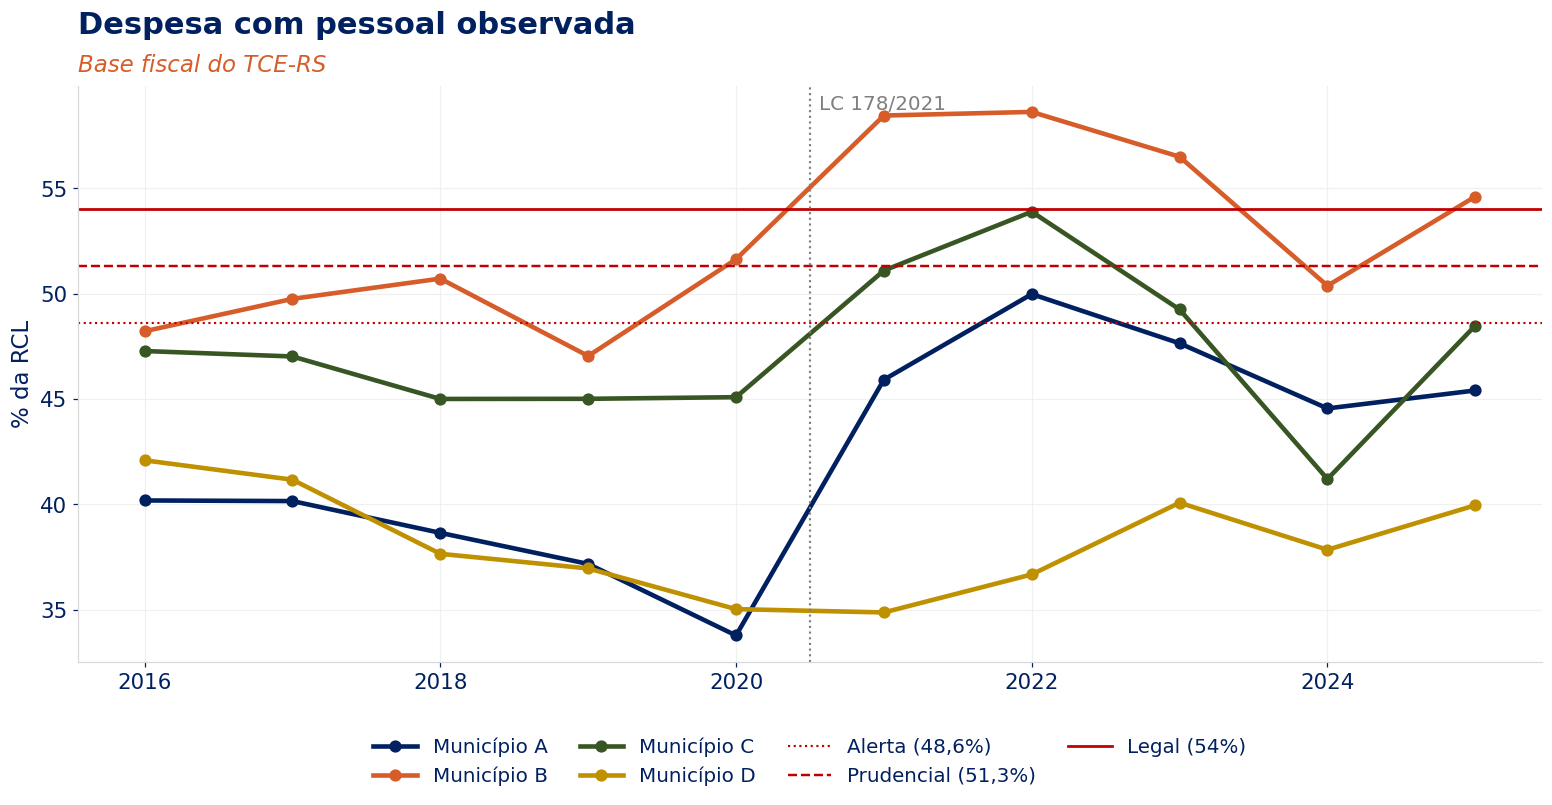

In [5]:
IPCA_MANUAL = {}   # ex.: {2016: 100.0, 2017: 103.4, ...} — índice médio anual, qualquer base

# IPCA acumulado no ano (dez/dez, %), IBGE. Último ano: conferir antes de usar em público.
IPCA_ANUAL_PCT = {2015: 10.67, 2016: 6.29, 2017: 2.95, 2018: 3.75, 2019: 4.31, 2020: 4.52,
                  2021: 10.06, 2022: 5.79, 2023: 4.62, 2024: 4.83, 2025: 4.26}


def _get_json(url, tentativas=3, espera=3):
    import time
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0", "Accept": "application/json"})
    erro = None
    for k in range(tentativas):
        try:
            with urllib.request.urlopen(req, timeout=30) as r:
                return json.load(r)
        except Exception as e:
            erro = e
            time.sleep(espera * (k + 1))
    raise erro


def ipca_anual(ano_ini=2015, ano_fim=2026):
    if IPCA_MANUAL:
        print("IPCA: valores manuais")
        return pd.Series(IPCA_MANUAL, name="ipca")
    try:
        d = pd.DataFrame(_get_json("https://api.bcb.gov.br/dados/serie/bcdata.sgs.433/dados?formato=json"
                                   f"&dataInicial=01/01/{ano_ini}&dataFinal=31/12/{ano_fim}"))
        d["data"] = pd.to_datetime(d.data, dayfirst=True)
        d["indice"] = (1 + d.valor.astype(float) / 100).cumprod()
        print("IPCA: Banco Central (SGS 433), média anual do índice")
        return d.groupby(d.data.dt.year).indice.mean().rename("ipca")
    except Exception as e:
        print("Banco Central indisponível:", e)
    try:
        j = _get_json("https://apisidra.ibge.gov.br/values/t/1737/n1/all/v/2266/p/all")
        d = pd.DataFrame(j[1:])
        d["ano"] = d.D3C.str[:4].astype(int)
        d["indice"] = pd.to_numeric(d.V, errors="coerce")
        d = d[(d.ano >= ano_ini) & (d.ano <= ano_fim)]
        print("IPCA: IBGE (SIDRA 1737), média anual do número-índice")
        return d.groupby("ano").indice.mean().rename("ipca")
    except Exception as e:
        print("IBGE indisponível:", e)
    print("IPCA: tabela embutida (variação dez/dez) — aproximação; conferir o último ano")
    idx, s = 100.0, {}
    for a in sorted(IPCA_ANUAL_PCT):
        idx *= 1 + IPCA_ANUAL_PCT[a] / 100
        s[a] = idx
    ult = max(s)
    for a in range(ult + 1, ano_fim + 1):      # anos sem dado: índice constante
        s[a] = s[ult]
    return pd.Series(s, name="ipca")


def serie_municipio(fiscal, ipca, nome, ano_ref=None):
    """Série de um município, com valores em R$ do ano de referência."""
    x = fiscal[fiscal.MUNICIPIO.str.upper() == nome.upper()].sort_values("ANO").copy()
    if x.empty:
        raise KeyError(f"município não encontrado: {nome}")
    ano_ref = ano_ref or int(x.ANO.max())
    fator = ipca.loc[ano_ref] / x.ANO.map(ipca)
    for c in ("VL_RECEITA_CORRENTE_LIQUIDA", "RCL_PESSOAL_ADOTADA", "VL_DESPESA_PESSOAL",
              "VL_DIVIDA_CONSOLIDADA_LIQUIDA"):
        x[c + "_REAL"] = x[c] * fator
    return x


def calibrar_fiscal(p, fiscal, ipca, municipio):
    """Ajusta rcl0, g_rcl, dcl_rcl, outras_pessoal e rcl_obs (Anexo VI, art. 50, I, II e § 1º),
    em R$ do ano-base. A RCL usada é a ajustada para fins de pessoal (desde 2020)."""
    ab = p["ano_base"]
    s = serie_municipio(fiscal, ipca, municipio, ano_ref=ab)
    hist = s[(s.ANO >= ab - 5) & (s.ANO <= ab - 1)]
    pend = s[s.ANALISE_LRF_CONCLUIDA != "S"]
    if len(pend):
        print("ATENÇÃO: análise LRF não concluída em", pend.ANO.tolist())
    rcl = hist.VL_RECEITA_CORRENTE_LIQUIDA_REAL.to_numpy()
    g_hist = (rcl[-1] / rcl[0]) ** (1 / (len(rcl) - 1)) - 1
    g = min(g_hist, p["teto_g_rcl"])
    # O histórico mede só a RCL; a folha não é medida no mesmo período. Projetar a RCL pelo histórico e a folha
    # por hipótese cria um "ganho" do Tesouro pouco crível. Por isso o cenário neutro usa a mesma taxa para
    # RCL e vencimentos (g_rcl_cenario e g_geral).
    if p.get("g_rcl_cenario") is not None:
        g = p["g_rcl_cenario"]
    atual = s[s.ANO == ab]
    ref = atual if len(atual) else hist.tail(1)
    rcl0 = float(ref.RCL_PESSOAL_ADOTADA_REAL.iloc[0])
    dtp_rcl = float(ref.DTP_RCL.iloc[0])
    obs = s[s.ANO > ab].set_index("ANO").RCL_PESSOAL_ADOTADA_REAL.to_dict()
    q = cenario(p, rcl0=rcl0, g_rcl=float(g), dcl_rcl=float(max(0.0, ref.DCL_RCL.iloc[0])), rcl_obs=obs)
    m = massa_inicial(q)
    sup = (q["aliq_sup0"] or 0.0) * base_contrib(m, q)
    pat = q["pat0"] if q["pat0"] is not None else q["piso_pat"]
    rpps = folha(m) + pat * base_contrib(m, q) + sup
    if q["ja_segregado"]:
        mfr = massa_inicial(cenario(q, **q["massa_FR"]))
        pfr = q["pat_FR"] if q["pat_FR"] is not None else pat
        bFR = base_contrib(mfr, q)
        insuf = max(0.0, folha_benef(mfr) * (1 - q["comprev"] - q["contrib_inat"]) - (q["aliq_serv"] + pfr) * bFR)
        rpps += folha(mfr) + pfr * bFR + insuf
    ins0 = 0.0
    if q["saque_so_com_equilibrio"] and not q["ja_segregado"]:
        a0 = q["ativos0"] or 0.0
        av_ = avaliar(m, a0, q, 0, pat)
        if av_["resultado"] < 0:
            rec = ((q["aliq_serv"] + pat) * base_contrib(m, q) + sup
                   + (q["comprev"] + q["contrib_inat"]) * folha_benef(m) + q["retorno"] * a0)
            ins0 = max(0.0, folha_benef(m) - rec)
            rpps += ins0
    rpps /= rcl0
    q["outras_pessoal"] = max(0.0, dtp_rcl - rpps)
    print(f"{municipio} · ano-base {ab}")
    print(f"  RCL {rcl0/1e6:,.1f} mi · crescimento real histórico {g_hist:.2%} · adotado nas projeções: {g:.2%} "
          f"(vencimentos: {q['g_geral'] if q['g_geral'] is not None else g:.2%})")
    if obs:
        print("  RCL real observada após o ano-base:", {k: round(v / 1e6, 1) for k, v in obs.items()}, "(R$ mi)")
    print(f"  DTP/RCL observada {dtp_rcl:.1%} · RPPS no modelo {rpps:.1%} · outras {q['outras_pessoal']:.1%}")
    if ins0 > 0:
        print(f"  insuficiência do ano-base pela regra do TCE: {ins0/1e6:,.1f} mi ({ins0/rcl0:.1%} da RCL) — "
              "se não aparece na DTP observada, está sendo coberta com saques do fundo")
    if rpps > dtp_rcl:
        print("  ATENÇÃO: folha + encargos do modelo superam a DTP observada — revise salário, n_ativos ou alíquotas")
    return q


def grafico_historico(fiscal, nomes, p=BASE, rotulos=None):
    """DTP/RCL observada (base TCE), com os limites da LRF. rotulos: nomes anônimos para os slides."""
    fig, ax = plt.subplots(figsize=FIG)
    for i, n in enumerate(nomes):
        x = fiscal[fiscal.MUNICIPIO.str.upper() == n.upper()].sort_values("ANO")
        ax.plot(x.ANO, x.DTP_RCL * 100, marker="o", ms=7, lw=3, color=SERIES[i % len(SERIES)],
                label=(rotulos[i] if rotulos else n.title()))
    limites_lrf(ax, p, alerta=True)
    ax.axvline(2020.5, color=CINZA, lw=1.4, ls=":")
    ax.annotate("LC 178/2021", xy=(2020.5, 1), xycoords=("data", "axes fraction"), xytext=(6, -6),
                textcoords="offset points", va="top", fontsize=13, color=CINZA)
    ax.set_ylabel("% da RCL")
    titulo(ax, "Despesa com pessoal observada", "Base fiscal do TCE-RS")
    legenda_abaixo(ax, ncol=4)
    return ax

FISCAL = carregar_fiscal()
IPCA = ipca_anual()

FISCAL[FISCAL.MUNICIPIO.isin(["CAXIAS DO SUL", "SÃO LOURENÇO DO SUL", "SANTA MARIA", "GARIBALDI"])] \
    .pivot(index="ANO", columns="MUNICIPIO", values="DTP_RCL")

grafico_historico(FISCAL, ["CAXIAS DO SUL", "SÃO LOURENÇO DO SUL", "SANTA MARIA", "GARIBALDI"],
                  rotulos=["Município A", "Município B", "Município C", "Município D"])
plt.show()

## 3. Motor
### 3.1 Demografia
Cada fundo é um conjunto de matrizes [geração × idade]: número de ativos (`A`), salário médio (`S`),
número de beneficiários (`B`) e benefício médio (`V`). Aposentados e pensionistas formam um só grupo.
Sem invalidez nem rotatividade. Todos ingressam na mesma idade, o que permite deduzir a geração pela idade.

In [6]:
IDADES = np.arange(18, 101)
N = len(IDADES)
_a, _b, _c = 0.00022, 2.7e-6, 0.124
Q = np.clip(1 - np.exp(-(_a + _b * np.exp(_c * IDADES))), 0, 1)
Q[-1] = 1.0
PS = 1 - Q
L = np.concatenate([[1.0], np.cumprod(PS)[:-1]])
K = N
SURV = np.zeros((N, K + 1))                     # SURV[x, k] = l(x+k) / l(x)
for x in range(N):
    for k in range(K + 1):
        SURV[x, k] = L[x + k] / L[x] if x + k < N else 0.0


def vazio():
    z = lambda: np.zeros((3, N))
    return dict(A=z(), S=z(), B=z(), V=z())


def geracao(ano_ingresso, p):
    return 0 if ano_ingresso < p["corte_G1"] else (1 if ano_ingresso < p["corte_G3"] else 2)


def idade_apos(p, g, t):
    base, add = p["idade_apos"][g] + p.get("ajuste_idade", 0.0), p["reforma_anos"][g]
    if add == 0 or t < p["reforma_ano"]:
        return base
    r = p["reforma_rampa"]
    return base + add * (1.0 if r <= 0 else min(1.0, (t - p["reforma_ano"]) / r))


def folha(m):
    return float((m["A"] * m["S"]).sum())


def base_contrib(m, p):
    b = m["A"] * m["S"]
    b[2] = m["A"][2] * np.minimum(m["S"][2], p["teto_rgps"])
    return float(b.sum())


def folha_benef(m):
    return float((m["B"] * m["V"]).sum())


def envelhecer(m, p, t, g_ben_G1):
    """Fim de t -> fim de t+1: mortes, aposentadorias, salários. Sem ingressos."""
    n = vazio()
    saidas = float((m["A"] * Q).sum())
    n["A"][:, 1:] = (m["A"] * PS)[:, :-1]
    n["S"][:, 1:] = m["S"][:, :-1] * (1 + p["g_sal"])
    n["B"][:, 1:] = (m["B"] * PS)[:, :-1]
    n["V"][:, 1:] = m["V"][:, :-1]
    n["V"][0] *= 1 + g_ben_G1
    for g in range(3):
        k = int(round(idade_apos(p, g, t + 1))) - IDADES[0]
        na = n["A"][g, k:].copy()
        if na.sum() <= 0:
            continue
        saidas += float(na.sum())
        bn = p["repos"][g] * n["S"][g, k:]
        if g == 2:
            bn = np.minimum(bn, p["teto_rgps"])
        tot = n["B"][g, k:] + na
        n["V"][g, k:] = np.where(tot > 0, (n["B"][g, k:] * n["V"][g, k:] + na * bn) / np.maximum(tot, 1e-12), 0)
        n["B"][g, k:] = tot
        n["A"][g, k:] = 0
    return n, saidas


def ingressar(m, qtd, salario, p):
    if qtd <= 0:
        return
    k = p["idade_entrada"] - IDADES[0]
    a0 = m["A"][2, k]
    m["S"][2, k] = (a0 * m["S"][2, k] + qtd * salario) / (a0 + qtd)
    m["A"][2, k] += qtd


def massa_inicial(p):
    m = vazio()
    peso = np.exp(-0.5 * ((IDADES - p["idade_ativos"]) / p["dp_ativos"]) ** 2)
    for k, x in enumerate(IDADES):
        if x < p["idade_entrada"]:
            continue
        g = geracao(p["ano_base"] - (x - p["idade_entrada"]), p)
        if x >= idade_apos(p, g, 0):
            continue
        m["A"][g, k] = peso[k]
        m["S"][g, k] = (1 + p["g_sal"]) ** (x - p["idade_entrada"])
    m["A"] *= p["n_ativos"] / m["A"].sum()
    m["S"] *= p["sal_mensal"] * p["parcelas"] / (folha(m) / m["A"].sum())
    pb = np.exp(-0.5 * ((IDADES - p["idade_benef"]) / p["dp_benef"]) ** 2)
    pb[IDADES < 45] = 0
    m["B"][0] = (p["n_apos"] + p["n_pens"]) * pb / pb.sum()
    m["V"][0] = np.where(m["B"][0] > 0, p["ben_mensal"] * p["parcelas"], 0)
    return m


def separar(m, p):
    """(FR, FC). Ativos pela idade de corte; beneficiários abaixo da idade máxima vão ao FR."""
    fr, fc = vazio(), vazio()
    a_fr = IDADES >= p["corte_idade_ativos"]
    b_fr = IDADES < p["benef_FR_idade_max"]
    for k in ("A", "S"):
        fr[k][:, a_fr], fc[k][:, ~a_fr] = m[k][:, a_fr], m[k][:, ~a_fr]
    for k in ("B", "V"):
        fr[k][:, b_fr], fc[k][:, ~b_fr] = m[k][:, b_fr], m[k][:, ~b_fr]
    return fr, fc

def transferir_beneficiarios(FR, FC, orcamento, an, p):
    """Transfere beneficiários do FR para o FC, dos mais idosos aos mais novos, até consumir o orçamento
    (valor atual da provisão assumida). Devolve (vidas, custo)."""
    cp, ci, fp = p["comprev"], p["contrib_inat"], p.get("fator_passivo", 1.0)
    vidas = custo = 0.0
    orc = orcamento
    for k in range(N - 1, -1, -1):
        for g in range(3):
            if orc <= 0 or FR["B"][g, k] <= 1e-9:
                continue
            cu = FR["V"][g, k] * an[g, k] * (1 - cp - ci) * fp
            q = FR["B"][g, k] if cu <= 0 else min(FR["B"][g, k], orc / cu)
            b0 = FC["B"][g, k]
            FC["V"][g, k] = (b0 * FC["V"][g, k] + q * FR["V"][g, k]) / (b0 + q)
            FC["B"][g, k] += q
            FR["B"][g, k] -= q
            orc -= q * cu
            vidas += q
            custo += q * cu
    return vidas, custo

### 3.2 Avaliação atuarial (método agregado, grupo fechado)

- Alíquota normal de equilíbrio = VABF a conceder × (1 − COMPREV) ÷ VASF, recalculada a cada ano.
- PMBC = VABF concedidos × (1 − COMPREV − contribuição de inativos).
- PMBAC = VABF a conceder × (1 − COMPREV) − (servidor + patronal vigente) × VASF.
- Resultado = ativos garantidores − PMBC − PMBAC.

A avaliação usa a hipótese de crescimento dos benefícios do DRAA (`g_ben_aval`, em geral 0%).
Os fluxos de caixa usam a paridade (`g_ben_G1`). A diferença entre os dois é perda atuarial recorrente,
como ocorre nos RPPS reais.

In [7]:
def anuidades(p):
    v = 1 / (1 + p["juros"])
    k = np.arange(K + 1)
    an = np.zeros((3, N))
    for g in range(3):
        cresc = (1 + p["g_ben_aval"]) if g == 0 else 1.0
        fator = (v * cresc) ** k
        fator[0] = 0.0
        an[g] = SURV @ fator
    return an


def fluxo_concedidos(m, p):
    k = np.arange(K + 1)
    out = np.zeros(K + 1)
    for g in range(3):
        cresc = (1 + p["g_ben_aval"]) if g == 0 else 1.0
        out += ((m["B"][g] * m["V"][g]) @ SURV) * cresc ** k
    out[0] = 0
    return out


def projetar_ativos(m, p, t):
    mm = vazio()
    mm["A"], mm["S"] = m["A"].copy(), m["S"].copy()
    B, S = np.zeros(K + 1), np.zeros(K + 1)
    for k in range(1, K + 1):
        mm, _ = envelhecer(mm, p, t + k - 1, p["g_ben_aval"])
        B[k], S[k] = folha_benef(mm), base_contrib(mm, p)
        if mm["A"].sum() + mm["B"].sum() < 1e-9:
            break
    return B, S


def avaliar(m, ativos, p, t, pat):
    v = 1 / (1 + p["juros"])
    d = v ** np.arange(K + 1)
    cp, ci = p["comprev"], p["contrib_inat"]
    fc_c = fluxo_concedidos(m, p) * p.get("fator_passivo", 1.0)
    B_a, S_a = projetar_ativos(m, p, t)
    B_a = B_a * p.get("fator_passivo", 1.0)
    vabf_c, vabf_a, vasf = fc_c @ d, B_a @ d, S_a @ d
    aliq = p["aliq_serv"] + pat
    pmbc = vabf_c * (1 - cp - ci)
    pmbac = vabf_a * (1 - cp) - aliq * vasf
    pm = pmbc + pmbac
    liq = (fc_c + B_a) * (1 - cp) - ci * fc_c - aliq * S_a
    den = liq @ d
    D = float((np.arange(K + 1) * liq) @ d / den) if den > 0 else 0.0
    marg = max(ativos * 0.87 - pm, ativos * (0.75 + 0.01 * min(D, p["D_max"])) - pm)
    return dict(vabf_c=vabf_c, vabf_a=vabf_a, vasf=vasf, pmbc=pmbc, pmbac=pmbac, pm=pm,
                ativos=ativos, resultado=ativos - pm, duracao=D, margem=marg,
                aliq_eq=vabf_a * (1 - cp) / vasf if vasf > 0 else 0.0)

### 3.3 Simulação anual

Ordem dos eventos em cada exercício *t*:

1. RCL do exercício (observada, se houver; senão, projetada).
2. Segregação, se for o exercício previsto (todos os recursos ficam no FC; patronal do FC fixada).
3. Fluxos de cada fundo: folha, benefícios, contribuições, suplementar (alíquota) ou aporte.
4. Caixa do FC: libera aportes de *t* − 5; paga benefícios com contribuições, rendimentos e ativos livres;
   o que faltar é **insuficiência** (Tesouro). O aporte do ano entra em carência.
   O FR não tem reservas: a diferença entre benefícios e contribuições é insuficiência.
5. DTP = folha + patronal + suplementar por alíquota + insuficiências + outras. O aporte fica de fora.
   **Comprometimento total** = DTP + aporte.
6. Avaliação de fim de ano: déficit e plano de amortização (prazo restante).
7. Gatilhos para *t* + 1: acima do prudencial → reposição de só 50% das saídas e, se houver suplementar
   por alíquota, migração para aporte (irreversível).
8. Dessegregação para *t* + 1: com superávit no FC, transfere beneficiários do FR, dos mais idosos aos mais
   novos, até a Margem do art. 62, § 3º.
9. Envelhecimento e ingressos (sempre no FC; com segregação, o FR é grupo fechado).

In [8]:
def simular(p):
    m = massa_inicial(p)
    an = anuidades(p)
    i = p["juros"]
    g_rcl = p["g_rcl"] if p.get("g_rcl_cenario") is not None else min(p["g_rcl"], p["teto_g_rcl"])
    g_geral = p["g_geral"] if p["g_geral"] is not None else g_rcl
    g_carr = p["g_carreira"] if p["g_carreira"] is not None else max(0.0, p["g_sal"] - 0.01)
    g_ben_G1 = p["g_ben_G1"] if p["g_ben_G1"] is not None else g_geral
    ps = dict(p, g_sal=g_carr + g_geral)          # evolução efetiva dos salários na simulação
    sal_ent = p["sal_entrada_rel"] * p["sal_mensal"] * p["parcelas"]
    obs = p["rcl_obs"] or {}

    av0 = avaliar(m, 0.0, p, 0, 0.0)
    pat = p["pat0"] if p["pat0"] is not None else float(np.clip(av0["aliq_eq"] - p["aliq_serv"], p["piso_pat"], p["teto_pat"]))
    ativos0 = p["ativos0"] if p["ativos0"] is not None else p["ic0"] * av0["pmbc"]

    FC, FR = m, vazio()
    livre, lotes, caixa_FR = ativos0, [], 0.0
    pat_FR = p["pat_FR"] if p["pat_FR"] is not None else pat
    bloqueio, segregado = False, False
    frac_ap = 1.0 if p["forma0"] == "aporte" else 0.0     # fração do custeio suplementar paga como aporte
    if p["ja_segregado"]:
        FR = massa_inicial(cenario(p, **p["massa_FR"]))
        segregado = True
    inicio_plano = -(p["prazo"] - p["prazo0"]) if p["prazo0"] else 0
    superavits, recalcular = 0, False
    f_troca, novos_acum, reinv_acum = 0.0, 0.0, 0.0

    def sem_plano_em(t):
        return p["sem_plano"] and (p["ano_plano"] is None or t < p["ano_plano"])

    def plano(deficit, base, t0, t):
        n = max(p["prazo"] - (t - t0), 1)
        prest = deficit * i / (1 - (1 + i) ** (-n)) if deficit > 0 else 0.0
        return prest, (prest / base if base > 0 else 0.0)

    av = avaliar(FC, ativos0, p, 0, pat)
    prest, aliq_sup = plano(max(0.0, -av["resultado"]), base_contrib(FC, p), inicio_plano, 0)
    if p["aliq_sup0"] is not None:
        aliq_sup = p["aliq_sup0"]
    if p["aporte0"] is not None:
        prest = p["aporte0"]
    if sem_plano_em(0):
        prest, aliq_sup = 0.0, 0.0
    sup0 = aliq_sup * base_contrib(m, p)
    rpps0 = folha(m) + pat * base_contrib(m, p) + sup0 + folha(FR) + pat_FR * base_contrib(FR, p)
    rcl0 = p["rcl0"] if p["rcl0"] else rpps0 / (p["dtp_rcl0"] - p["outras_pessoal"])
    reg = []
    rcl_ant, ano_ant = rcl0, p["ano_base"]

    for t in range(p["horizonte"] + 1):
        ano = p["ano_base"] + t
        if t == 0:
            rcl = rcl0
        elif ano in obs:
            rcl = obs[ano]
        else:
            rcl = rcl_ant * (1 + g_rcl)
        rcl_ant = rcl

        # --- segregação
        if p["segregar"] and t == p["ano_seg"] and not segregado:
            FR, FC = separar(FC, p)
            segregado = True
            pat_FR = p["pat_FR"] if p["pat_FR"] is not None else pat
            if p["pat_FC_seg"] is not None:
                pat = p["pat_FC_seg"]
            else:
                recalcular = True
            inicio_plano, superavits = t, 0
            av = avaliar(FC, livre + sum(v for v, _ in lotes), p, t, pat)
            if recalcular:                        # patronal do novo FC definida antes do corte de equilíbrio
                pat = float(np.clip(av["aliq_eq"] - p["aliq_serv"], p["piso_pat"], p["teto_pat"]))
                recalcular = False
                av = avaliar(FC, livre + sum(v for v, _ in lotes), p, t, pat)
            vidas_seg = 0.0
            if p["seg_equilibrada"] and av["resultado"] > 0:
                vidas_seg, _ = transferir_beneficiarios(FR, FC, av["resultado"], an, p)
                av = avaliar(FC, livre + sum(v for v, _ in lotes), p, t, pat)
            prest, aliq_sup = plano(max(0.0, -av["resultado"]), base_contrib(FC, p), inicio_plano, t)

        # --- fluxos
        bFC, bFR = base_contrib(FC, p), base_contrib(FR, p)
        benFC, benFR = folha_benef(FC), folha_benef(FR)
        cp, ci = p["comprev"], p["contrib_inat"]
        sup = aliq_sup * bFC * (1 - frac_ap)
        aporte_devido = prest * frac_ap

        # --- caixa do FC
        livre += sum(v for v, lib in lotes if lib <= t)
        lotes = [(v, lib) for v, lib in lotes if lib > t]
        carenc = sum(v for v, _ in lotes)
        rend = p["retorno"] * (livre + carenc)
        receita = (p["aliq_serv"] + pat) * bFC + sup + (cp + ci) * benFC + rend
        saldo = receita - benFC
        equilibrio = av["resultado"] >= 0                  # última avaliação
        pode_sacar = equilibrio or not p["saque_so_com_equilibrio"]
        insFC, saque = 0.0, 0.0
        if saldo >= 0:
            livre += saldo
        else:
            saque = min(livre, -saldo) if pode_sacar else 0.0
            livre -= saque
            insFC = -saldo - saque

        # --- caixa do FR (sem reservas)
        saldoFR = (p["aliq_serv"] + pat_FR) * bFR + (cp + ci) * benFR - benFR + caixa_FR
        insFR = max(0.0, -saldoFR)
        caixa_FR = max(0.0, saldoFR)

        # --- fiscal
        fol = folha(FC) + folha(FR)
        patr = pat * bFC + pat_FR * bFR
        outras = p["outras_pessoal"] * (1 - f_troca) * rcl
        dtp = fol + patr + sup + insFC + insFR + outras
        # capacidade de pagamento: o aporte só é pago até o teto de comprometimento da RCL
        if p["teto_comprometimento"] is not None:
            aporte = min(aporte_devido, max(0.0, p["teto_comprometimento"] * rcl - dtp))
        else:
            aporte = aporte_devido
        if aporte > 0:
            lotes.append((aporte, t + p["carencia"]))

        # --- avaliação de fim de ano
        ag = livre + sum(v for v, _ in lotes)
        if recalcular or (p["pat0"] is None and not segregado):
            av_tmp = avaliar(FC, ag, p, t, pat)
            pat_eq = float(np.clip(av_tmp["aliq_eq"] - p["aliq_serv"], p["piso_pat"], p["teto_pat"]))
            pat = pat_eq if (p["reduz_pat"] or recalcular) else max(pat, pat_eq)
        recalcular = False
        av = avaliar(FC, ag, p, t, pat)
        if p["sem_plano"] and p["ano_plano"] is not None and t + 1 == p["ano_plano"]:
            inicio_plano = t + 1
        if sem_plano_em(t + 1):
            prest, aliq_sup = 0.0, 0.0
        elif p["plano_fixo"] and not segregado and not (p["sem_plano"] and p["ano_plano"] is not None):
            if frac_ap > 0 and prest == 0.0 and aliq_sup > 0:
                prest = aliq_sup * bFC            # migrou: aporte equivalente à alíquota que vigorava
            elif frac_ap > 0:
                prest *= 1 + p["cresc_pagamento"]
            if t - inicio_plano >= p["prazo"] - 1:  # fim do plano vigente
                prest, aliq_sup = 0.0, 0.0
        else:
            prest, aliq_sup = plano(max(0.0, -av["resultado"]), bFC, inicio_plano, t)
        superavits = superavits + 1 if av["resultado"] > 0 else 0
        avFR = avaliar(FR, caixa_FR, p, t, pat_FR) if segregado else None
        defFR = max(0.0, -avFR["resultado"]) if avFR else 0.0

        # --- dessegregação (efeito em t+1)
        vidas, custo = 0.0, 0.0
        if p["desseg"] and segregado and superavits >= p["n_superavits"] and av["margem"] > 0:
            vidas, custo = transferir_beneficiarios(FR, FC, av["margem"], an, p)

        reg.append(dict(
            t=t, ano=ano, rcl=rcl, frac_aporte=frac_ap, forma=("aporte" if frac_ap >= 1 else "misto" if frac_ap > 0
                                                                   else "aliquota"),
            bloqueio=bloqueio, segregado=segregado,
            folha=fol, patronal=patr, suplementar=sup, aporte=aporte, aporte_devido=aporte_devido,
            aporte_nao_pago=aporte_devido - aporte, insuf_FC=insFC, insuf_FR=insFR,
            saque=saque, equilibrio=equilibrio,
            custo_servidor=(fol + patr) / max(FC["A"].sum() + FR["A"].sum(), 1e-9),
            outras=outras, dtp=dtp, dtp_rcl=dtp / rcl, comprometimento=(dtp + aporte) / rcl,
            ativos_FC=FC["A"].sum(), benef_FC=FC["B"].sum(), ativos_FR=FR["A"].sum(), benef_FR=FR["B"].sum(),
            ativos_total=FC["A"].sum() + FR["A"].sum(),
            ativos_G1=FC["A"][0].sum() + FR["A"][0].sum(), ativos_G2=FC["A"][1].sum() + FR["A"][1].sum(),
            ativos_G3=FC["A"][2].sum() + FR["A"][2].sum(),
            ag_FC=ag, ag_carencia=sum(v for v, _ in lotes), resultado_FC=av["resultado"],
            pmbc_FC=av["pmbc"], pmbac_FC=av["pmbac"],
            deficit_FR=defFR, pat_normal=pat, aliq_eq=av["aliq_eq"], aliq_sup=aliq_sup,
            duracao_FC=av["duracao"], margem=av["margem"], vidas_transferidas=vidas, custo_transferencia=custo,
            endiv=(p["dcl_rcl"] * rcl + max(0.0, -av["resultado"]) + (defFR if p["incluir_FR_endiv"] else 0)) / rcl,
        ))

        # --- gatilhos para t+1
        bloqueio = dtp / rcl > p["lim_prud"]
        if frac_ap == 0 and bloqueio and sup > 0 and p["frac_aporte"] > 0:
            frac_ap = p["frac_aporte"]
            if p["plano_fixo"]:
                prest = sup

        # --- envelhecimento e ingressos
        FC, s1 = envelhecer(FC, ps, t, g_ben_G1)
        s2 = 0.0
        if segregado:
            FR, s2 = envelhecer(FR, ps, t, g_ben_G1)
        g_ent = g_geral if p["g_sal_entrada"] is None else p["g_sal_entrada"]
        extra = 0.0 if bloqueio else p["reposicao_extra"] * (FC["A"].sum() + FR["A"].sum())
        ingressar(FC, (s1 + s2) * (p["repos_bloqueio"] if bloqueio else 1.0) + extra,
                  sal_ent * (1 + g_ent) ** (t + 1), p)
        reg[-1]["vagas_nao_repostas"] = (s1 + s2) * (1 - p["repos_bloqueio"]) if bloqueio else 0.0
        # --- troca de "outras despesas com pessoal" por servidores efetivos (orçamento neutro)
        # custo anual de um novo servidor G3 para o ente: salário + patronal normal + suplementar por alíquota.
        # É o "motor": no plano vigente, a suplementar incide sobre toda a folha, inclusive sobre quem entra;
        # no fundo em capitalização segregado, o novo servidor custa só salário + patronal normal.
        sal_novo = sal_ent * (1 + g_ent) ** (t + 1)
        fator_custo = 1 + pat + aliq_sup * (1 - frac_ap)
        custo_novo = sal_novo * fator_custo
        rcl_prox = rcl * (1 + g_rcl)
        novos = 0.0
        if (p["troca_outras"] > 0 and t + 1 >= p["ano_troca"]
                and f_troca < p["troca_outras"] - 1e-12 and not bloqueio):
            passo = min(p["troca_outras"] / max(p["troca_rampa"], 1), p["troca_outras"] - f_troca)
            novos = passo * p["outras_pessoal"] * rcl_prox / custo_novo
            ingressar(FC, novos, sal_novo, p)
            f_troca += passo
            novos_acum += novos
        # reinvestimento: o que o ente deixa de gastar frente ao orçamento-alvo vira nomeações
        reinv = 0.0
        alvo = (p["alvo_comprometimento"] or {}).get(ano + 1)
        if p["reinvestir"] and alvo is not None and not bloqueio:
            compr_prox = (dtp + aporte) / rcl                                  # aproximação para t+1
            espaco_alvo = (alvo - compr_prox) * rcl_prox
            espaco_lrf = (p["lim_prud"] - p["folga_prudencial"] - dtp / rcl) * rcl_prox
            verba = max(0.0, min(espaco_alvo, espaco_lrf))
            reinv = verba / custo_novo
            if reinv > 0:
                ingressar(FC, reinv, sal_novo, p)
                reinv_acum += reinv
        reg[-1]["novos_troca"] = novos
        reg[-1]["novos_troca_acum"] = novos_acum
        reg[-1]["novos_reinvest"] = reinv
        reg[-1]["novos_reinvest_acum"] = reinv_acum
        reg[-1]["frac_troca"] = f_troca
        reg[-1]["fator_custo_novo"] = fator_custo
        reg[-1]["servidores_por_milhao"] = 1e6 / custo_novo

    df = pd.DataFrame(reg)
    df["insuf"] = df.insuf_FC + df.insuf_FR
    q0 = p["quadro_referencia"] or df.ativos_total.iloc[0]
    df["quadro_referencia"] = q0
    df["deficit_servidores"] = (q0 - df.ativos_total).clip(lower=0)
    df["vagas_nao_repostas_acum"] = df.vagas_nao_repostas.cumsum()
    extra = df.suplementar + df.aporte + df.insuf          # custo previdenciário além da patronal normal
    df["custo_prev_extra"] = extra
    df["servidores_equivalentes"] = extra / df.custo_servidor
    for c in ("folha", "patronal", "suplementar", "insuf", "aporte", "aporte_nao_pago", "outras"):
        df[f"{c}_rcl"] = df[c] / df.rcl
    df["cenario"] = p.get("nome", "")
    return df

### 3.4 Verificações internas
Antes de olhar qualquer resultado: a simulação conserva pessoas e o caixa fecha?

In [9]:
def verificar_coerencia(p):
    m = massa_inicial(p)
    m1, s = envelhecer(m, p, 0, p["g_ben_G1"] or 0.0)
    mortes_benef = float((m["B"] * Q).sum())
    ok_pessoas = abs((m["A"].sum() + m["B"].sum()) - (m1["A"].sum() + m1["B"].sum())
                     - (float((m["A"] * Q).sum()) + mortes_benef)) < 1e-6
    fr, fc = separar(m, p)
    ok_sep = abs(fr["A"].sum() + fc["A"].sum() - m["A"].sum()) < 1e-6 and \
             abs(fr["B"].sum() + fc["B"].sum() - m["B"].sum()) < 1e-6
    pz = cenario(p, juros=0.0, retorno=0.0)
    av = avaliar(m, 0.0, pz, 0, 0.0)
    B_a, S_a = projetar_ativos(m, pz, 0)
    ok_va = abs(av["vabf_a"] - B_a.sum()) < 1e-3 * max(1, B_a.sum())
    return pd.DataFrame([
        ("Pessoas: estoque final = inicial − mortes", ok_pessoas),
        ("Segregação não cria nem perde pessoas", ok_sep),
        ("Com juros zero, VABF = soma simples dos fluxos", ok_va),
    ], columns=["verificação", "ok"])

### 3.5 Diagnóstico: marcos da espiral e art. 52 do Anexo VI

In [10]:
def marcos(df, p):
    def primeiro(cond):
        x = df.loc[cond, "ano"]
        return int(x.iloc[0]) if len(x) else "—"
    return pd.DataFrame([
        ("DTP acima do alerta", primeiro(df.dtp_rcl > p["lim_alerta"])),
        ("DTP acima do prudencial (reposição restrita em t+1)", primeiro(df.dtp_rcl > p["lim_prud"])),
        ("Custeio passa (total ou parcialmente) a aporte", primeiro(df.frac_aporte > 0)),
        ("Aporte devido não é pago integralmente", primeiro(df.aporte_nao_pago > 1)),
        ("Insuficiência no FC enquanto há aporte em carência", primeiro((df.insuf_FC > 0) & (df.ag_carencia > 0))),
        ("DTP acima do limite legal", primeiro(df.dtp_rcl > p["lim_legal"])),
        ("Comprometimento total (DTP + aporte) acima de 60% da RCL", primeiro(df.comprometimento > 0.60)),
        ("Endividamento com déficit acima de 1,2 × RCL", primeiro(df.endiv > p["lim_endiv"])),
        ("Primeiro superávit do FC", primeiro(df.resultado_FC > 0)),
        ("Primeira dessegregação", primeiro(df.vidas_transferidas > 0)),
    ], columns=["marco", "ano"])


def art52(df, p):
    j = df[(df.t >= 1) & (df.t <= 10)]
    return pd.DataFrame([
        ("I — DTP acima de limite da LRF em algum exercício", bool((df.dtp_rcl > p["lim_prud"]).any())),
        ("II — endividamento com déficit acima de 1,2 × RCL", bool((df.endiv > p["lim_endiv"]).any())),
        ("III — insuficiência financeira nos 10 exercícios seguintes", bool((j.insuf > 0).any())),
    ], columns=["critério (exige justificativa técnica)", "atingido"])

### 3.6 Gráficos (exibição até `ano_max_grafico`)

In [11]:
def _corte(df, p):
    return df[df.ano <= p.get("ano_max_grafico", 2050)]


def grafico_composicao(df, p, titulo=None, ax=None):
    """Barras empilhadas em % da RCL. O aporte aparece por cima, hachurado: não entra na DTP."""
    df = _corte(df, p)
    if ax is None:
        fig, ax = plt.subplots(figsize=FIG)
    x = df.ano.to_numpy()
    base = np.zeros(len(df))
    for col, rot, cor in (("folha_rcl", "Folha de ativos", CORES["folha"]),
                          ("patronal_rcl", "Patronal normal", CORES["patronal"]),
                          ("outras_rcl", "Outras despesas com pessoal", CORES["outras"]),
                          ("suplementar_rcl", "Suplementar (alíquota)", CORES["suplementar"]),
                          ("insuf_rcl", "Insuficiência financeira", CORES["insuficiencia"])):
        y = df[col].to_numpy() * 100
        if y.sum() == 0:
            continue
        ax.bar(x, y, bottom=base, color=cor, width=0.78, label=rot)
        base += y
    if df.aporte_rcl.sum() > 0:
        ax.bar(x, df.aporte_rcl * 100, bottom=base, color="none", edgecolor=CORES["aporte"],
               hatch="///", width=0.78, label="Aporte pago (fora da DTP)")
    if df.aporte_nao_pago_rcl.sum() > 0.001:
        ax.bar(x, df.aporte_nao_pago_rcl * 100, bottom=base + df.aporte_rcl.to_numpy() * 100, color="none",
               edgecolor=CINZA, hatch="..", width=0.78, label="Aporte devido e não pago")
    limites_lrf(ax, p)
    if p["segregar"]:
        ax.axvline(p["ano_base"] + p["ano_seg"] - .5, color=LARANJA, lw=2, ls=":", label="Segregação")
    ax.set_ylim(0, max(80, (base + (df.aporte_rcl + df.aporte_nao_pago_rcl).to_numpy() * 100).max() * 1.08))
    ax.set_ylabel("% da RCL")
    globals()["titulo"](ax, titulo or p.get("nome", ""), "Despesa com pessoal e previdenciária, % da RCL")
    legenda_abaixo(ax, ncol=4)
    return ax


def grafico_comparativo(dfs, p, var="comprometimento",
                        rotulo="Comprometimento da RCL: despesa com pessoal + aporte"):
    """Padrão: comprometimento total. Comparar só a DTP favorece indevidamente quem usa aporte."""
    fig, ax = plt.subplots(figsize=FIG)
    for (nome, df), c in zip(dfs.items(), SERIES):
        d = _corte(df, p)
        ax.plot(d.ano, d[var] * 100, color=c, lw=3.4, label=nome)
    limites_lrf(ax, p)
    ax.set_ylabel("% da RCL")
    titulo(ax, rotulo)
    legenda_abaixo(ax, ncol=3)
    return ax


def grafico_servidores(dfs, p):
    """Número de servidores ativos: o bloqueio de reposição aparece aqui."""
    fig, ax = plt.subplots(figsize=FIG)
    for (nome, df), c in zip(dfs.items(), SERIES):
        d = _corte(df, p)
        ax.plot(d.ano, d.ativos_total, color=c, lw=3.4, label=nome)
    q0 = list(dfs.values())[0].quadro_referencia.iloc[0]
    ax.axhline(q0, color=CINZA, lw=1.6, ls="--", label=f"Quadro de {p['ano_base']}")
    ax.set_ylabel("Servidores ativos")
    titulo(ax, "Servidores ativos", "Abaixo da linha tracejada: menos servidores do que hoje para atender a população")
    legenda_abaixo(ax, ncol=4)
    return ax


def grafico_fundos(df, p, titulo=""):
    df = _corte(df, p)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=FIG)
    a1.plot(df.ano, df.ativos_FC, color=VERDE_FC, lw=2.4, label="Ativos FC")
    a1.plot(df.ano, df.benef_FC, color=VERDE_FC, lw=2.4, ls="--", label="Beneficiários FC")
    a1.plot(df.ano, df.ativos_FR, color=VERMELHO_FR, lw=2.4, label="Ativos FR")
    a1.plot(df.ano, df.benef_FR, color=VERMELHO_FR, lw=2.4, ls="--", label="Beneficiários FR")
    a1.set_title("Pessoas por fundo", loc="left", color=AZUL, weight="bold")
    a1.legend(frameon=False)
    a2.bar(df.ano, df.resultado_FC / 1e6, color=np.where(df.resultado_FC > 0, VERDE_FC, VERMELHO_FR))
    a2.axhline(0, color=AZUL, lw=.8)
    a2.set_title("Resultado atuarial do FC (R$ mi)", loc="left", color=AZUL, weight="bold")
    fig.suptitle(titulo, color=AZUL, weight="bold")

def grafico_servicos(df, p, titulo_=None):
    """Quem paga a conta: a população. Dois painéis num só slide.
    (1) servidores ativos × quadro do ano-base, com os anos de reposição restrita sombreados;
    (2) custo previdenciário além da patronal normal (suplementar + aporte + insuficiência),
        convertido em 'servidores equivalentes' ao custo médio de um servidor (salário + patronal)."""
    d = _corte(df, p)
    q0 = d.quadro_referencia.iloc[0]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, height_ratios=[1.15, 1])
    sombrear_bloqueio(a1, d, cor="#E7E6E6")
    a1.fill_between(d.ano, d.ativos_total, q0, where=d.ativos_total < q0, interpolate=True,
                    color=VERMELHO_FR, alpha=.30, lw=0, label="Servidores a menos que hoje")
    a1.plot(d.ano, d.ativos_total, color=AZUL, lw=3.6, label="Servidores ativos")
    a1.axhline(q0, color=CINZA, lw=2, ls="--", label=f"Quadro de {p['ano_base']}")
    a1.set_ylim(0, q0 * 1.12)
    a1.set_ylabel("Servidores")
    titulo(a1, titulo_ or f"{p.get('nome', '')} · quem paga a conta",
           "Menos servidores atendendo a população, mais recursos para cobrir o passivo previdenciário")
    sombrear_bloqueio(a2, d, cor="#E7E6E6", rotulo=None)
    a2.bar(d.ano, d.servidores_equivalentes, color=VERMELHO_FR, width=.78,
           label="Custo previdenciário além da patronal normal, em servidores equivalentes")
    a2.axhline(q0, color=CINZA, lw=2, ls="--")
    a2.set_ylabel("Servidores equivalentes")
    a2.set_title("Quanto custa o passivo, medido em servidores que poderiam ser pagos",
                 loc="left", color=AZUL, fontsize=16, weight="bold", pad=10)
    h1, l1 = a1.get_legend_handles_labels()
    h2, l2 = a2.get_legend_handles_labels()
    a2.legend(h1 + h2, l1 + l2, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.10))
    return fig


def tabela_servicos(dfs, anos=(2030, 2040, 2050)):
    """Síntese por cenário para o slide: servidores a menos e custo em servidores equivalentes."""
    linhas = []
    for nome, df in dfs.items():
        for a in anos:
            r_ = df[df.ano == a]
            if r_.empty:
                continue
            r_ = r_.iloc[0]
            linhas.append(dict(cenário=nome, ano=a, servidores=round(r_.ativos_total),
                               a_menos_que_hoje=round(r_.deficit_servidores),
                               vagas_nao_repostas_acum=round(r_.vagas_nao_repostas_acum),
                               custo_extra_em_servidores=round(r_.servidores_equivalentes),
                               anos_com_reposicao_restrita=int(df[df.ano <= a].bloqueio.sum())))
    return pd.DataFrame(linhas).set_index(["cenário", "ano"])


def numeros_palestra(dfs, anos=(2027, 2030, 2040, 2050)):
    """Números de apoio para explicar cada gráfico na hora da palestra (% da RCL e pessoas)."""
    linhas = []
    for nome, df in dfs.items():
        for a in anos:
            r_ = df[df.ano == a]
            if r_.empty:
                continue
            r_ = r_.iloc[0]
            linhas.append({"cenário": nome, "ano": a,
                           "DTP (% RCL)": round(100 * r_.dtp_rcl, 1),
                           "comprometimento (% RCL)": round(100 * r_.comprometimento, 1),
                           "insuficiência (% RCL)": round(100 * r_.insuf / r_.rcl, 1),
                           "aporte pago (% RCL)": round(100 * r_.aporte / r_.rcl, 1),
                           "aporte não pago (% RCL)": round(100 * r_.aporte_nao_pago / r_.rcl, 1),
                           "servidores": round(r_.ativos_total),
                           "nomeados pela troca (acum.)": round(r_.get("novos_troca_acum", 0)),
                           "nomeados com a economia (acum.)": round(r_.get("novos_reinvest_acum", 0)),
                           "custo de 1 novo servidor (× salário)": round(r_.get("fator_custo_novo", np.nan), 2),
                           "reposição restrita?": "sim" if r_.bloqueio else "não"})
    return pd.DataFrame(linhas).set_index(["cenário", "ano"])


def tabela_saques(res_por_municipio):
    """Quanto o fundo teria de 'sacar' se a regra do TCE não valesse — o que hoje vira insuficiência."""
    linhas = []
    for mun, rr in res_por_municipio.items():
        for cen, df in rr.items():
            d = df[(df.ano <= 2050)]
            linhas.append(dict(município=mun, cenário=cen,
                               anos_sem_equilibrio=int((~d.equilibrio).sum()),
                               insuf_FC_media_rcl=(d.insuf_FC / d.rcl).mean()))
    return pd.DataFrame(linhas).set_index(["município", "cenário"])

## 4. Município A: calibração e teste contra o passado

**Etapa 1 — verificações internas.** Todas devem dar `True`.

In [12]:
verificar_coerencia(MUN_A)

,verificação,ok
0,Pessoas: estoque final = inicial − mortes,True
1,Segregação não cria nem perde pessoas,True
2,"Com juros zero, VABF = soma simples dos fluxos",True


**Etapa 2 — calibração fiscal.** RCL do ano-base, crescimento histórico e, para o teste contra o passado,
a RCL real observada em 2023–2025.

In [13]:
MUN_A = calibrar_fiscal(MUN_A, FISCAL, IPCA, "CAXIAS DO SUL")

m0 = massa_inicial(MUN_A)
av0 = avaliar(m0, MUN_A["ativos0"], MUN_A, 0, MUN_A["pat0"])
pd.Series({
    "Ativos": m0["A"].sum(), "Beneficiários": m0["B"].sum(),
    "Folha de ativos (R$ mi)": folha(m0) / 1e6, "Folha de benefícios (R$ mi)": folha_benef(m0) / 1e6,
    "Folha de ativos / RCL": folha(m0) / MUN_A["rcl0"],
    "Alíquota de equilíbrio (total)": av0["aliq_eq"],
    "PMBC (R$ mi)": av0["pmbc"] / 1e6, "VABF a conceder (R$ mi)": av0["vabf_a"] / 1e6,
    "Resultado atuarial antes do plano (R$ mi)": av0["resultado"] / 1e6,
    "Duração do passivo (anos)": av0["duracao"],
})

CAXIAS DO SUL · ano-base 2022
  RCL 2,222.3 mi · crescimento real histórico 4.83% · adotado nas projeções: 1.00% (vencimentos: 1.00%)
  RCL real observada após o ano-base: {2023: 2465.8, 2024: 2606.9, 2025: 2681.7} (R$ mi)
  DTP/RCL observada 50.0% · RPPS no modelo 36.1% · outras 13.9%


,0
Ativos,"7,000.000"
Beneficiários,"4,700.000"
Folha de ativos (R$ mi),546.000
Folha de benefícios (R$ mi),384.930
Folha de ativos / RCL,0.246
Alíquota de equilíbrio (total),0.718
PMBC (R$ mi),"3,665.873"
VABF a conceder (R$ mi),"4,746.091"
Resultado atuarial antes do plano (R$ mi),"-5,933.465"
Duração do passivo (anos),19.024


**Etapa 3 — teste contra o passado.** O Município A começa em 2022 e segrega em 2023.
Valores reais: DRAA 2023–2026 (massas, ativos, resultado, receitas e despesas estimadas do FR) e base do TCE (DTP).
A insuficiência do FR "real" é a diferença entre despesas e receitas estimadas no DRAA do exercício.
**Critério:** ordem de grandeza e direção, não acerto exato.

In [14]:
REAL_A = pd.DataFrame({
    "ano": [2023, 2024, 2025, 2026],
    "ativos_FC": [4095, 4342, 4685, 5122], "benef_FC": [1460, 1407, 1363, 1276],
    "ativos_FR": [2914, 2667, 2431, 2237], "benef_FR": [3390, 3576, 3770, 3895],
    "ag_FC_mi": [442.3, 545.5, 652.8, 776.6], "resultado_FC_mi": [51.2, 36.1, 63.4, 117.3],
    "insuf_FR_mi": [221.4, 231.4, 213.3, 252.0],
})


def teste_passado(df, real, fiscal, municipio):
    s = df.copy()
    s["ag_FC_mi"], s["resultado_FC_mi"], s["insuf_FR_mi"] = s.ag_FC / 1e6, s.resultado_FC / 1e6, s.insuf_FR / 1e6
    s["dtp_rcl_pct"] = s.dtp_rcl * 100
    dtp = fiscal[fiscal.MUNICIPIO == municipio][["ANO", "DTP_RCL"]].rename(columns={"ANO": "ano"})
    dtp["dtp_rcl_pct"] = dtp.pop("DTP_RCL") * 100
    r = real.merge(dtp, on="ano", how="left")
    cols = ["ativos_FC", "benef_FC", "ativos_FR", "benef_FR", "ag_FC_mi", "resultado_FC_mi", "insuf_FR_mi", "dtp_rcl_pct"]
    linhas = []
    for c in cols:
        for _, row in r.iterrows():
            sim = s.loc[s.ano == row.ano, c]
            if len(sim) and pd.notna(row[c]):
                v = float(sim.iloc[0])
                linhas.append(dict(indicador=c, ano=int(row.ano), real=row[c], simulado=v,
                                   dif_pct=100 * (v - row[c]) / abs(row[c]) if row[c] else np.nan))
    t = pd.DataFrame(linhas)
    return t.pivot(index="indicador", columns="ano", values=["real", "simulado", "dif_pct"]).reindex(cols)

res_seg_A = simular(cenario(MUN_A, "Segregação", segregar=True))
teste_passado(res_seg_A, REAL_A, FISCAL, "CAXIAS DO SUL")

real                                simulado            \
ano                  2023      2024      2025      2026      2023      2024   
indicador                                                                     
ativos_FC       4,095.000 4,342.000 4,685.000 5,122.000 4,374.068 4,624.333   
benef_FC        1,460.000 1,407.000 1,363.000 1,276.000 1,483.291 1,407.697   
ativos_FR       2,914.000 2,667.000 2,431.000 2,237.000 2,729.004 2,583.055   
benef_FR        3,390.000 3,576.000 3,770.000 3,895.000 3,241.921 3,357.793   
ag_FC_mi          442.300   545.500   652.800   776.600   483.765   539.216   
resultado_FC_mi    51.200    36.100    63.400   117.300    -9.281    70.048   
insuf_FR_mi       221.400   231.400   213.300   252.000   134.928   151.799   
dtp_rcl_pct        47.649    44.559    45.411       NaN    47.970    47.241   

                                     dif_pct                          
ano                  2025      2026     2023    2024    2025    2026  
indicador                                                             
ativos_FC       4,896.937 5,192.731    6.815   6.502   4.524   1.381  
benef_FC        1,330.369 1,251.398    1.595   0.050  -2.394  -1.928  
ativos_FR       2,416.011 2,227.025   -6.349  -3.148  -0.617  -0.446  
benef_FR        3,491.298 3,642.909   -4.368  -6.102  -7.393  -6.472  
ag_FC_mi          610.714   700.621    9.375  -1.152  -6.447  -9.784  
resultado_FC_mi   161.545   266.727 -118.127  94.040 154.802 127.389  
insuf_FR_mi       171.291   193.515  -39.057 -34.400 -19.695 -23.208  
dtp_rcl_pct        47.548       NaN    0.674   6.020   4.704     NaN

## 5. Cenários do Município A (projeções)
Nas projeções, a RCL cresce à taxa adotada (teto do art. 50, § 3º), sem a RCL observada.

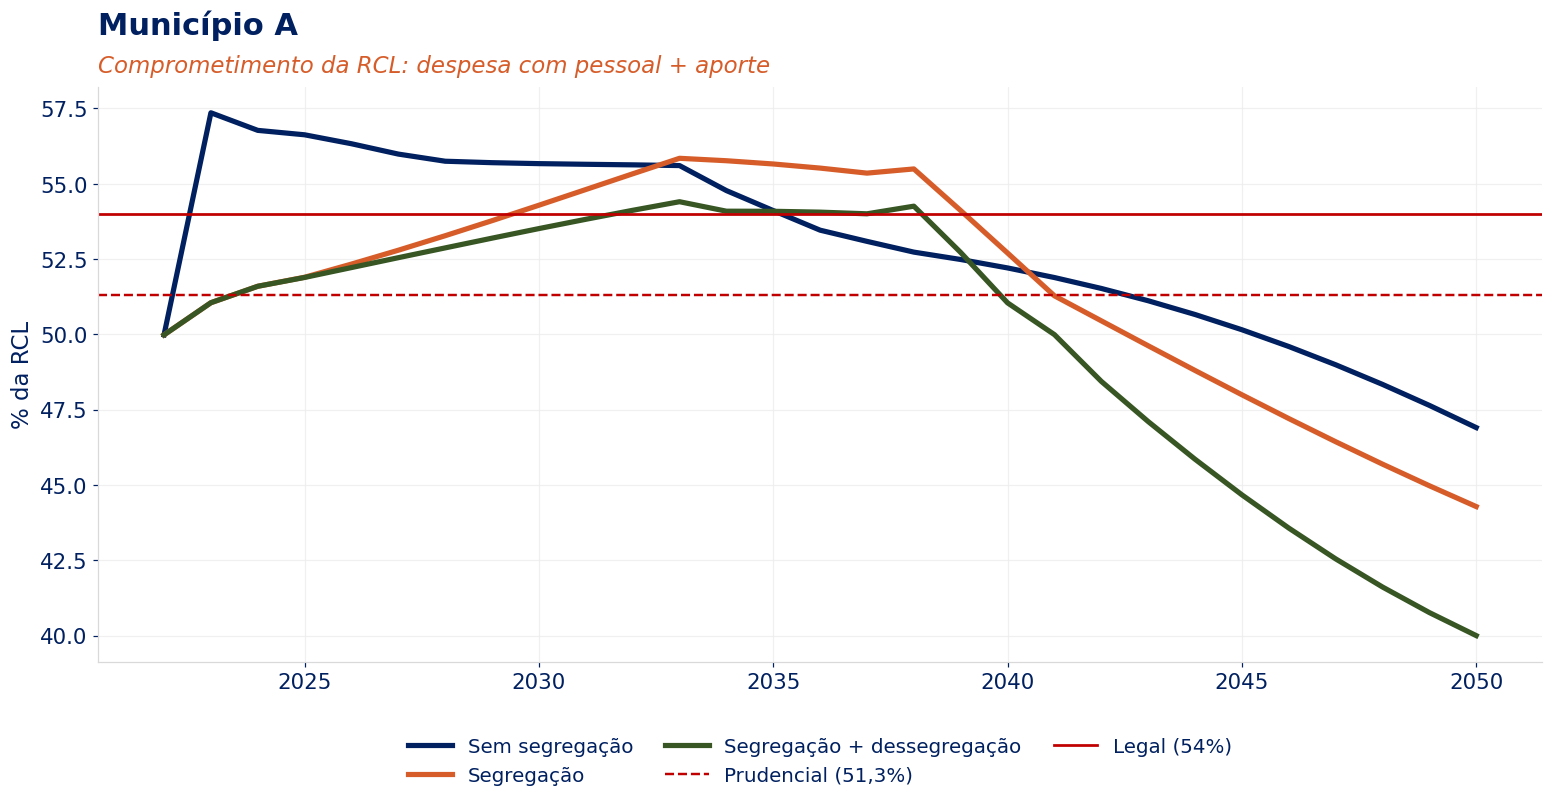

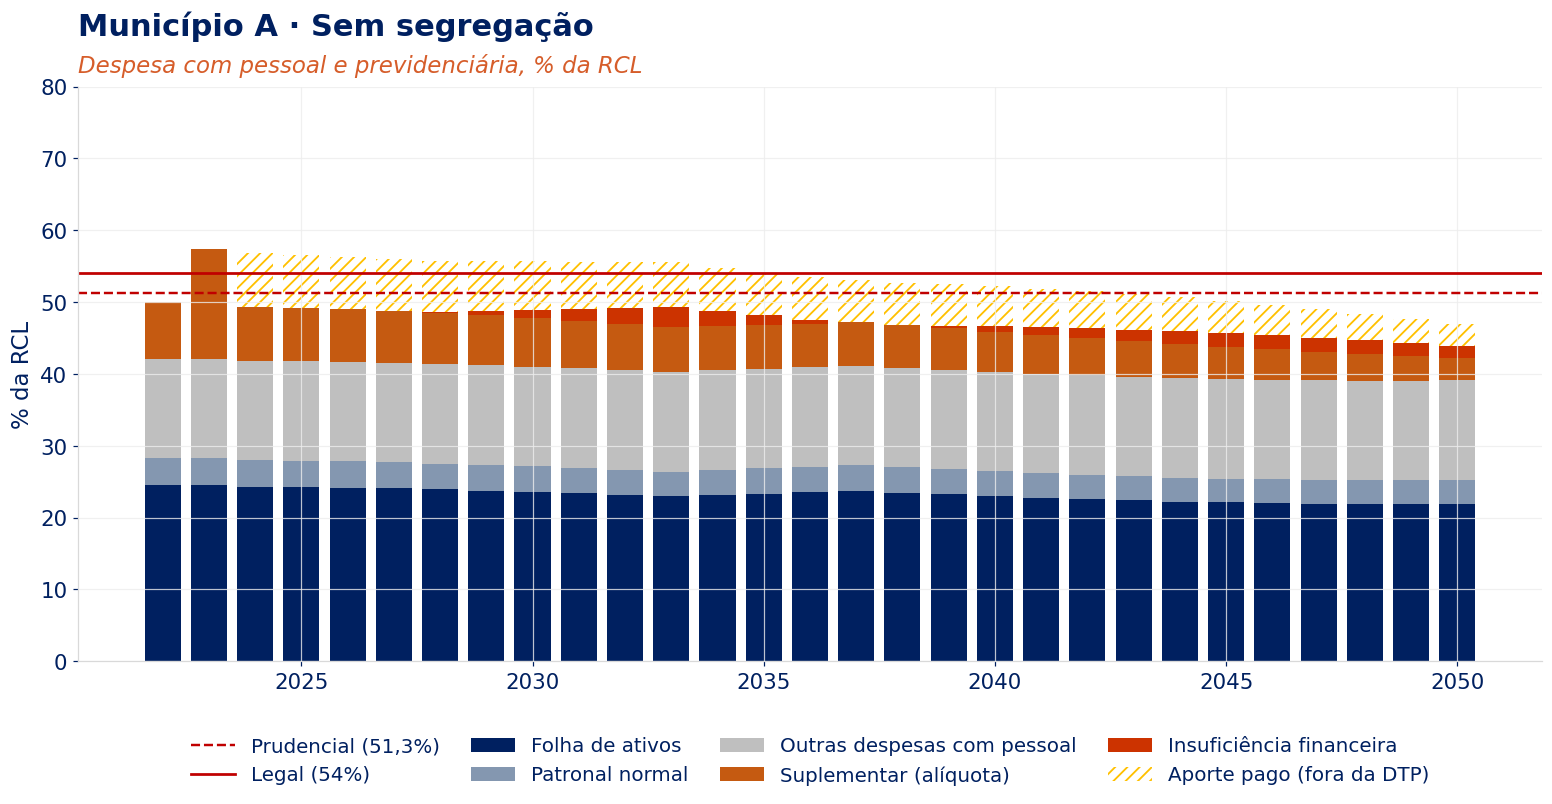

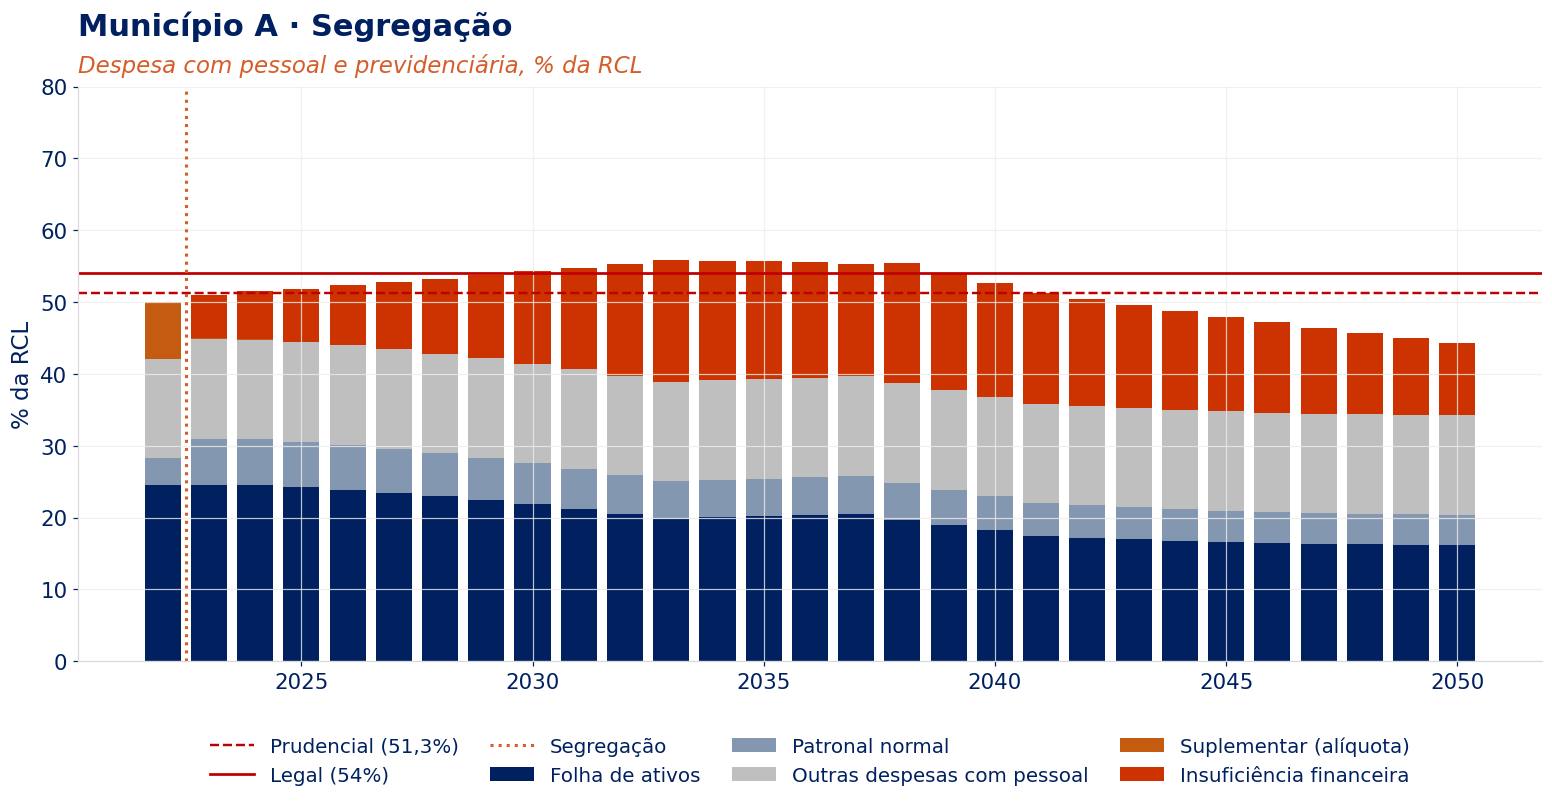

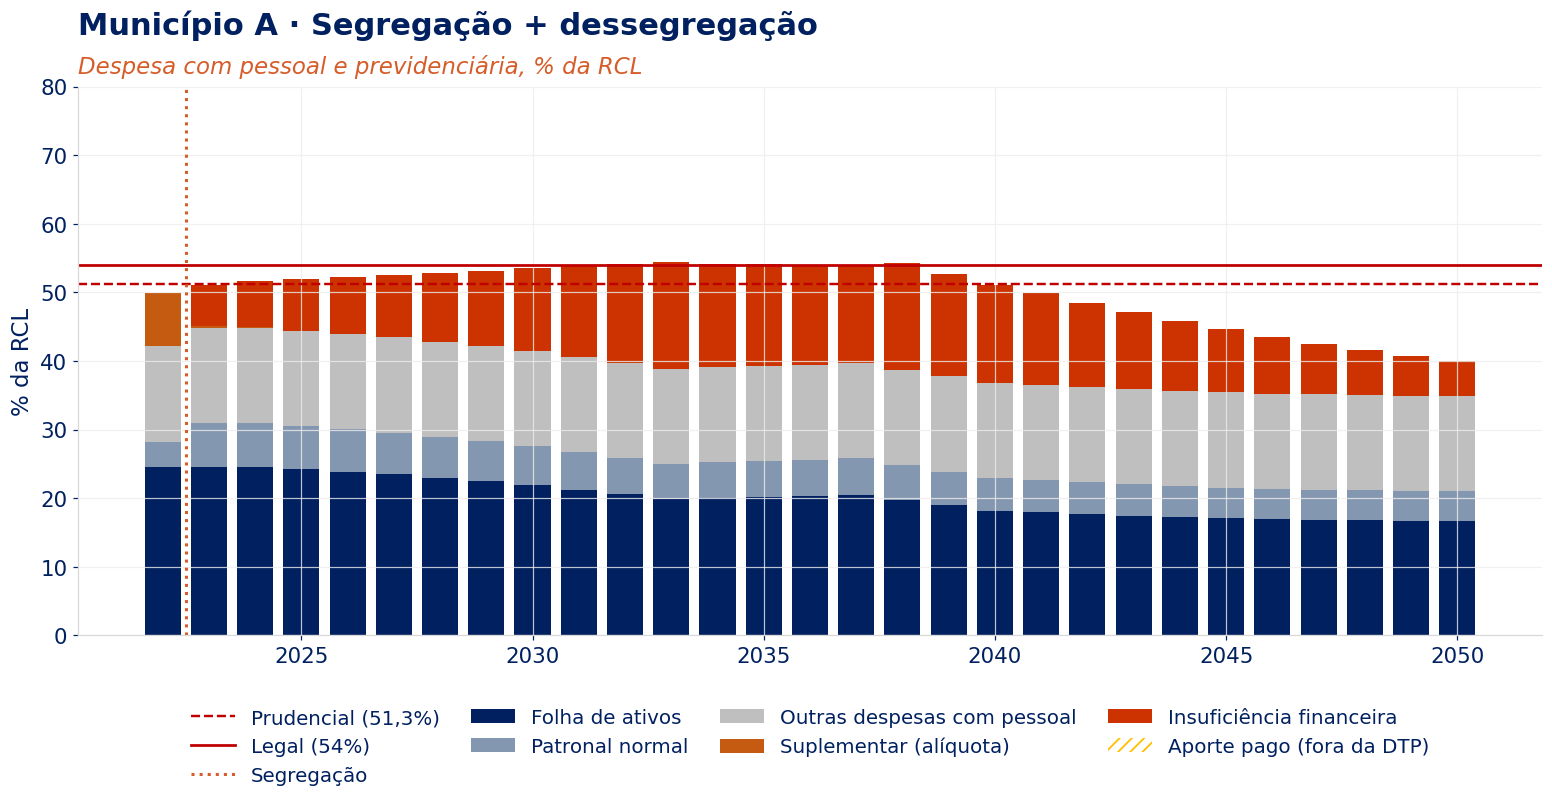

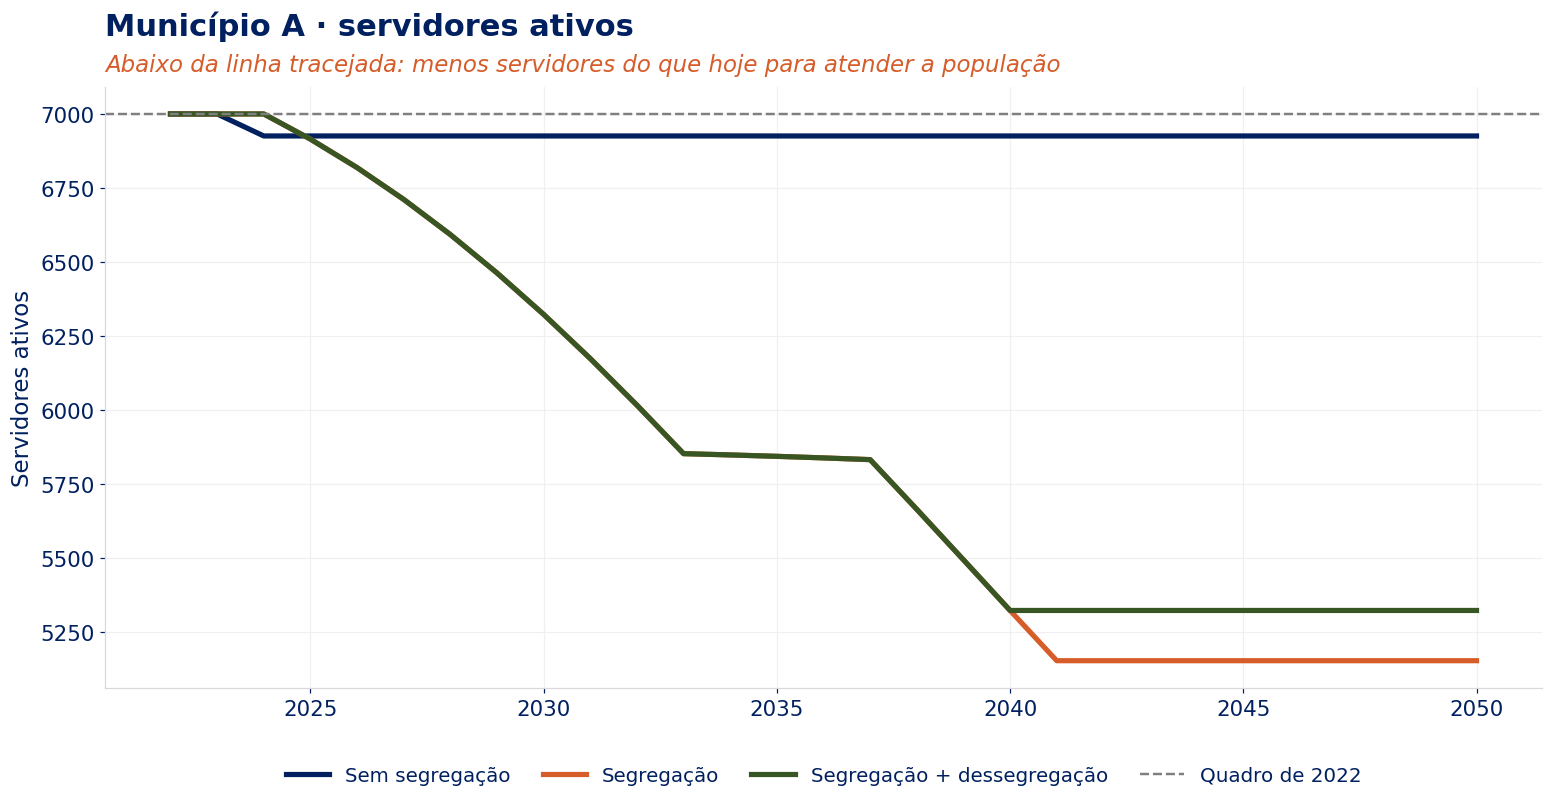

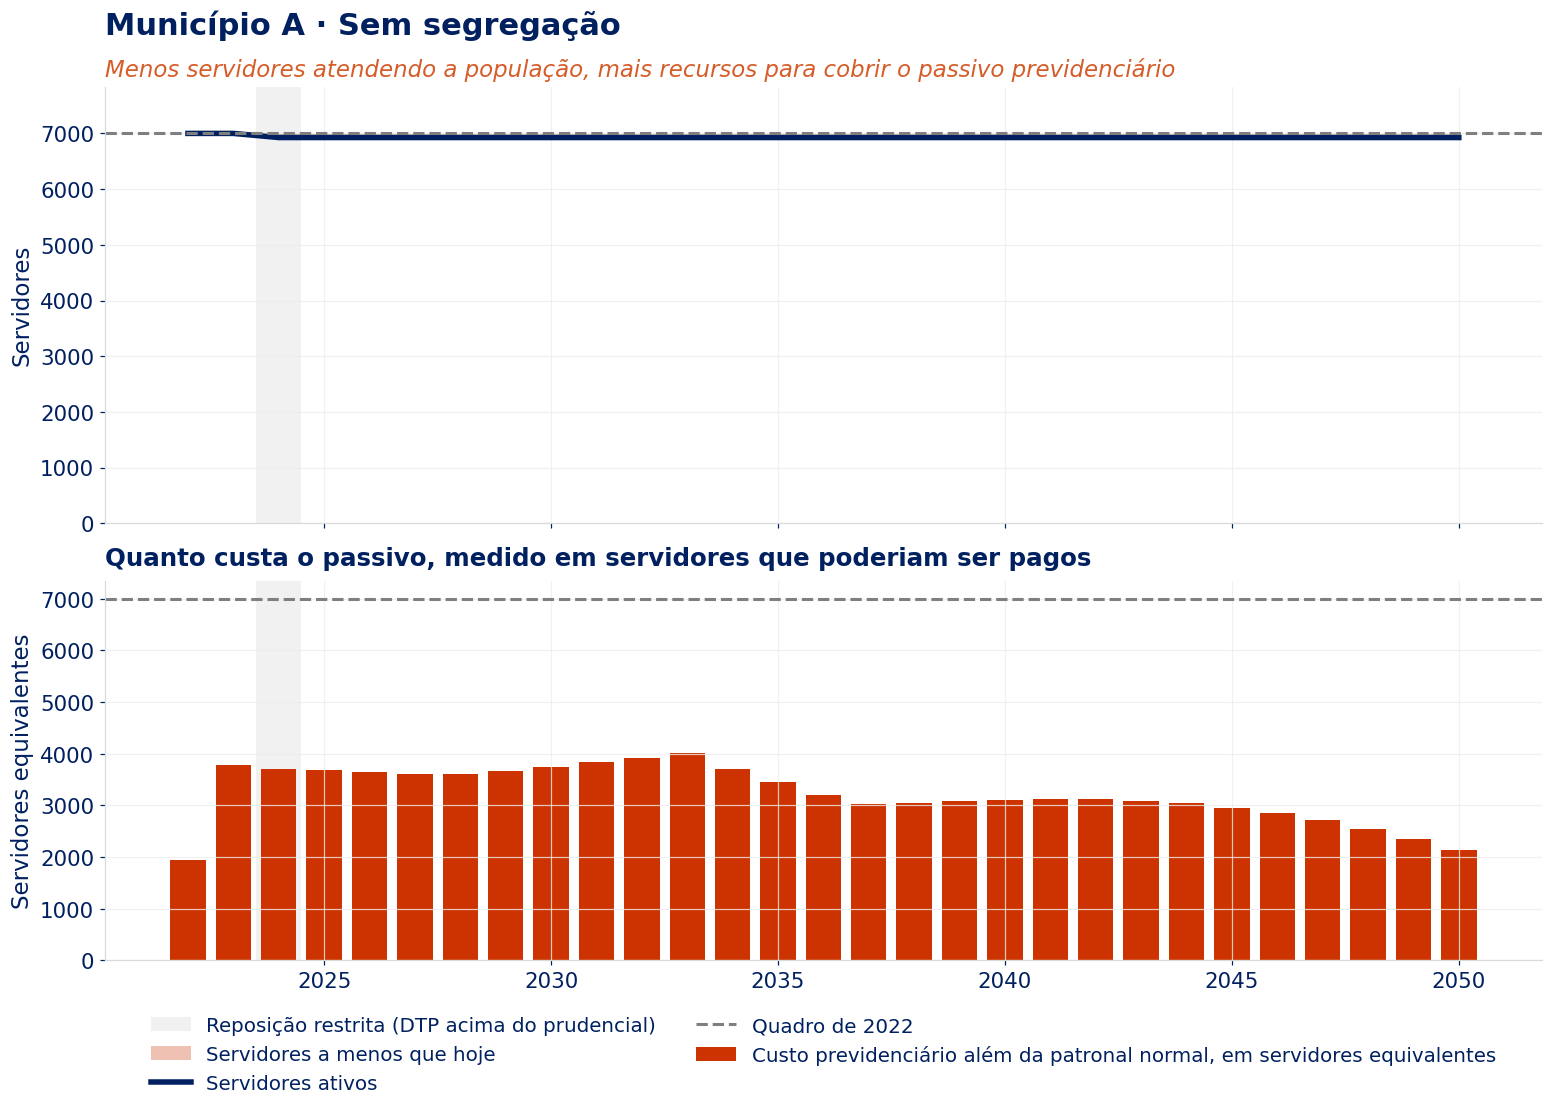

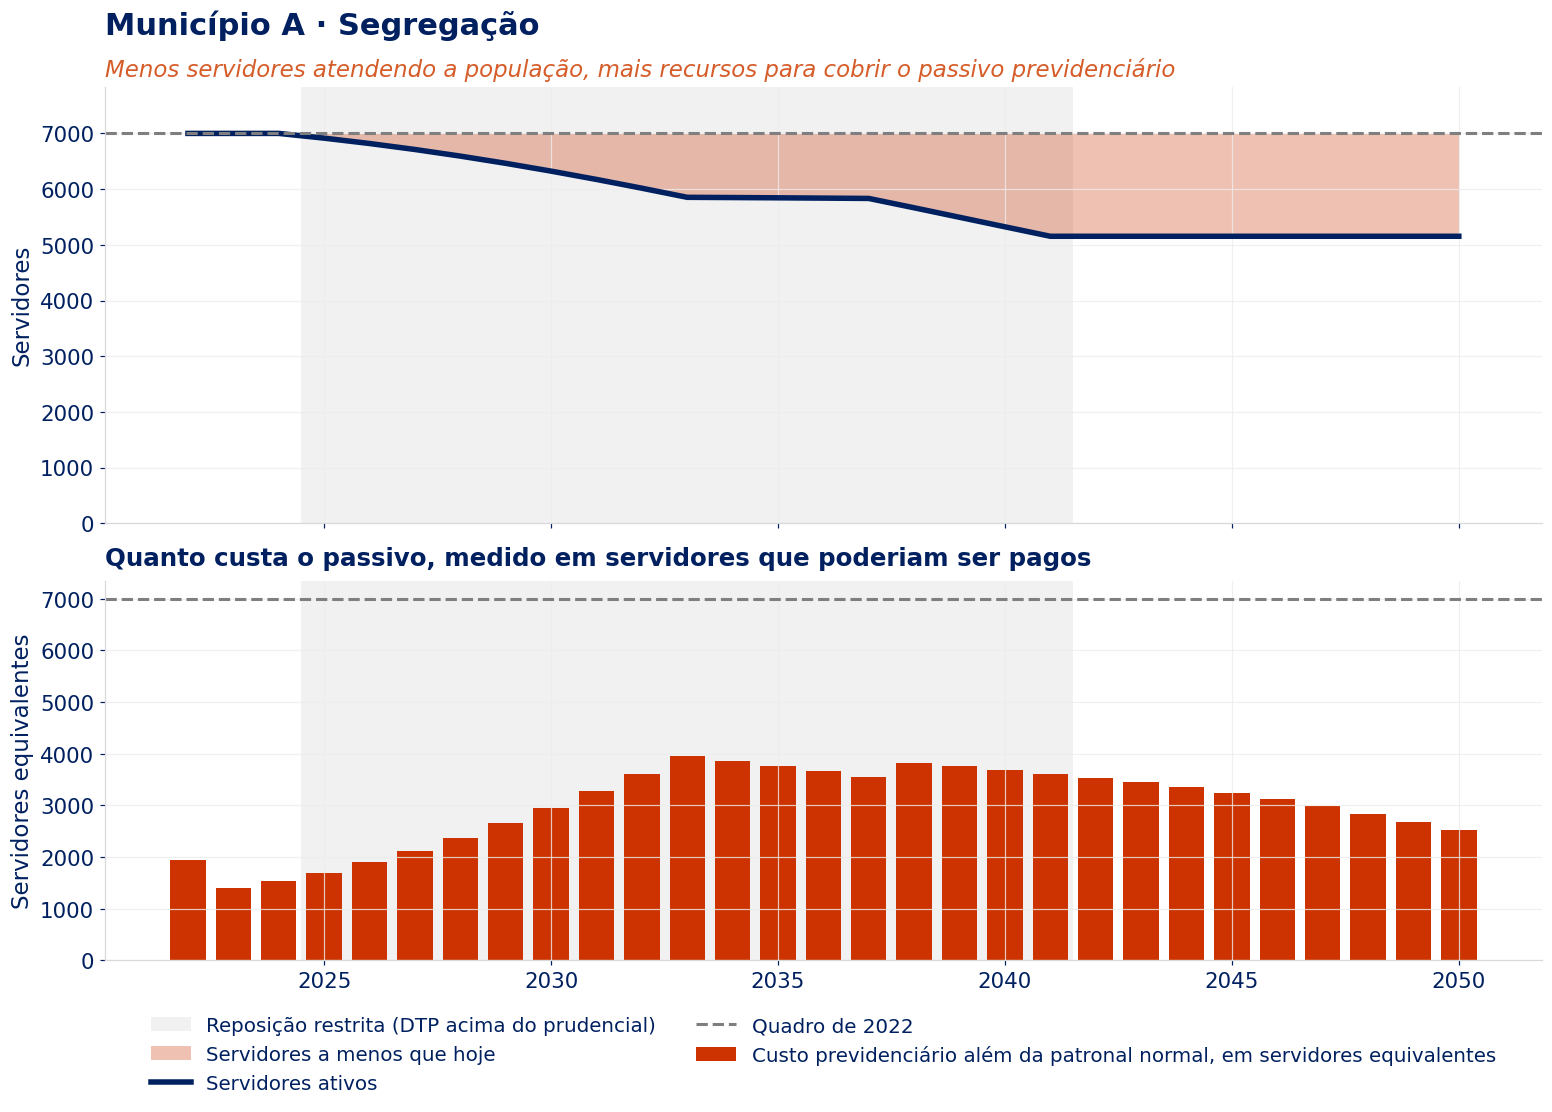

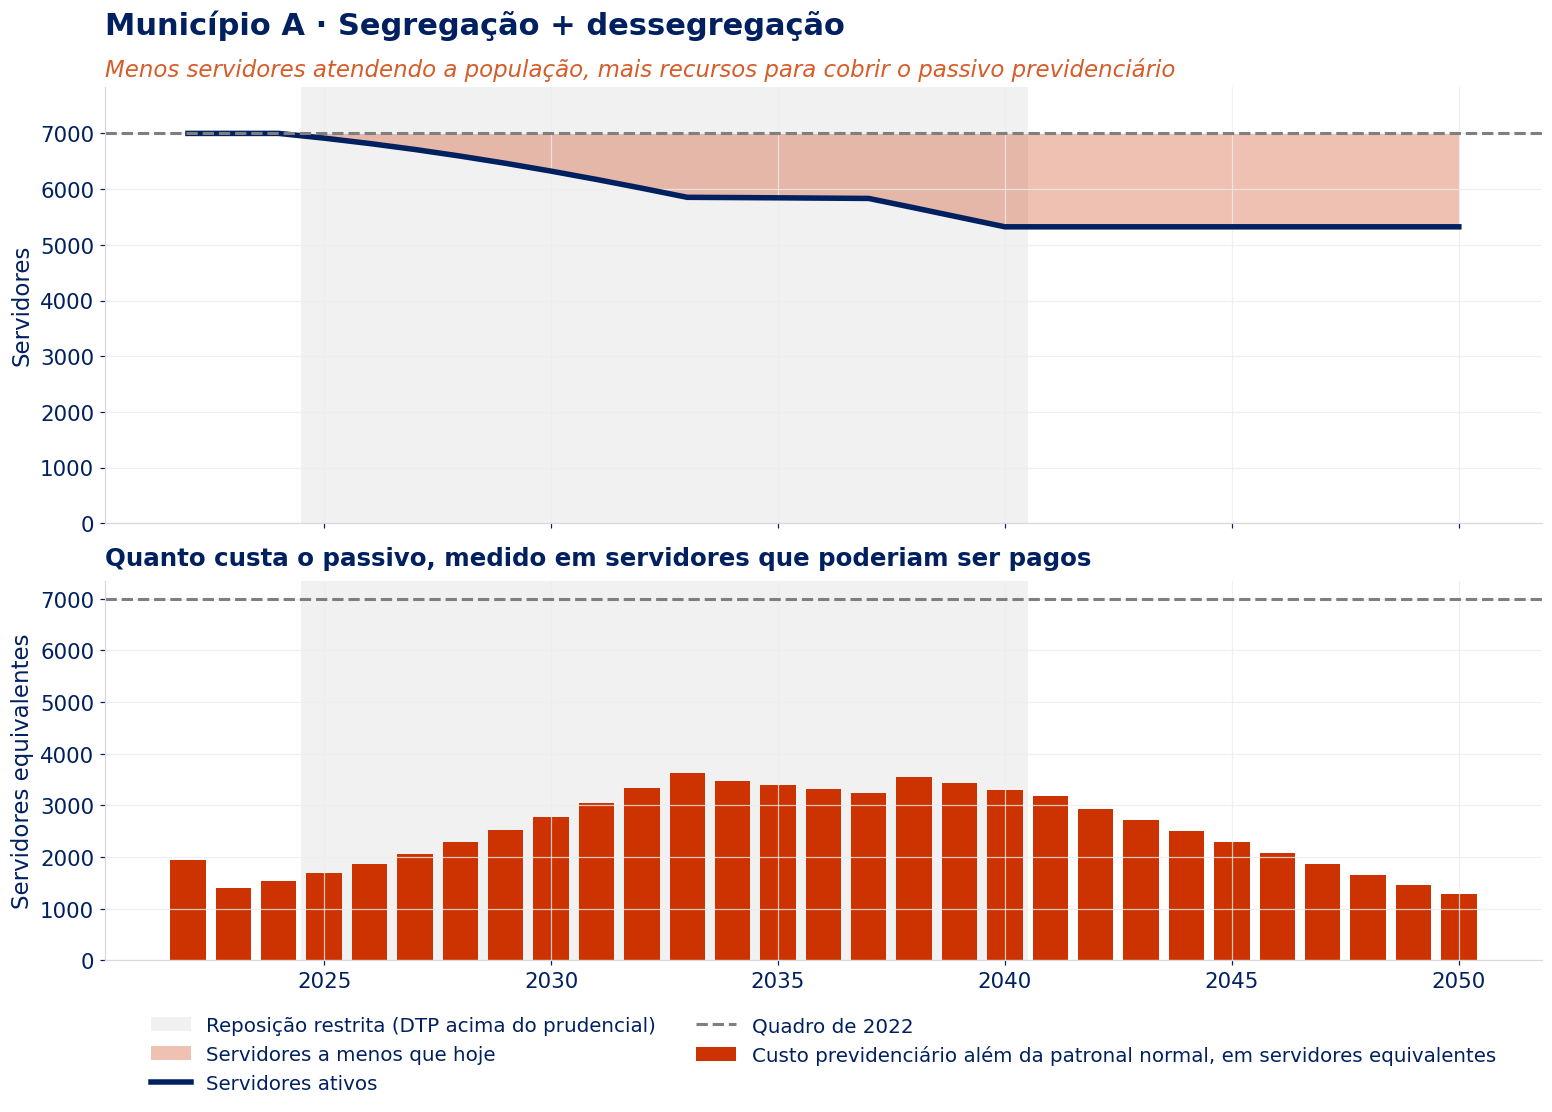

servidores  a_menos_que_hoje  \
cenário                    ano                                  
Sem segregação             2030        6926                74   
                           2040        6926                74   
                           2050        6926                74   
Segregação                 2030        6323               677   
                           2040        5323              1677   
                           2050        5153              1847   
Segregação + dessegregação 2030        6323               677   
                           2040        5323              1677   
                           2050        5323              1677   

                                 vagas_nao_repostas_acum  \
cenário                    ano                             
Sem segregação             2030                       74   
                           2040                       74   
                           2050                       74   
Segregação                 2030                      826   
                           2040                     1847   
                           2050                     1847   
Segregação + dessegregação 2030                      826   
                           2040                     1677   
                           2050                     1677   

                                 custo_extra_em_servidores  \
cenário                    ano                               
Sem segregação             2030                       3747   
                           2040                       3113   
                           2050                       2140   
Segregação                 2030                       2952   
                           2040                       3686   
                           2050                       2520   
Segregação + dessegregação 2030                       2774   
                           2040                       3302   
                           2050                       1277   

                                 anos_com_reposicao_restrita  
cenário                    ano                                
Sem segregação             2030                            1  
                           2040                            1  
                           2050                            1  
Segregação                 2030                            6  
                           2040                           16  
                           2050                           17  
Segregação + dessegregação 2030                            6  
                           2040                           16  
                           2050                           16

DTP (% RCL)  comprometimento (% RCL)  \
cenário                    ano                                          
Sem segregação             2027       48.800                   56.000   
                           2030       48.800                   55.700   
                           2040       46.600                   52.200   
                           2050       43.800                   46.900   
Segregação                 2027       52.800                   52.800   
                           2030       54.300                   54.300   
                           2040       52.700                   52.700   
                           2050       44.300                   44.300   
Segregação + dessegregação 2027       52.500                   52.500   
                           2030       53.500                   53.500   
                           2040       51.000                   51.000   
                           2050       40.000                   40.000   

                                 insuficiência (% RCL)  aporte pago (% RCL)  \
cenário                    ano                                                
Sem segregação             2027                  0.000                7.200   
                           2030                  1.000                6.800   
                           2040                  0.700                5.600   
                           2050                  1.600                3.100   
Segregação                 2027                  9.400                0.000   
                           2030                 12.900                0.000   
                           2040                 15.900                0.000   
                           2050                 10.000                0.000   
Segregação + dessegregação 2027                  9.100                0.000   
                           2030                 12.100                0.000   
                           2040                 14.200                0.000   
                           2050                  5.100                0.000   

                                 aporte não pago (% RCL)  servidores  \
cenário                    ano                                         
Sem segregação             2027                    0.000        6926   
                           2030                    0.000        6926   
                           2040                    0.000        6926   
                           2050                    0.000        6926   
Segregação                 2027                    0.000        6711   
                           2030                    0.000        6323   
                           2040                    0.000        5323   
                           2050                    0.000        5153   
Segregação + dessegregação 2027                    0.000        6711   
                           2030                    0.000        6323   
                           2040                    0.000        5323   
                           2050                    0.000        5323   

                                 nomeados pela troca (acum.)  \
cenário                    ano                                 
Sem segregação             2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0   
Segregação                 2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0   
Segregação + dessegregação 2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0  


=== Sem segregação


,marco,ano
0,DTP acima do alerta,2022
1,DTP acima do prudencial (reposição restrita em...,2023
2,Custeio passa (total ou parcialmente) a aporte,2024
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,2028
5,DTP acima do limite legal,2023
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2022
8,Primeiro superávit do FC,2057
9,Primeira dessegregação,—


,critério (exige justificativa técnica),atingido
0,I — DTP acima de limite da LRF em algum exercício,True
1,"II — endividamento com déficit acima de 1,2 × RCL",True
2,III — insuficiência financeira nos 10 exercíci...,True


...

,marco,ano
0,DTP acima do alerta,2022
1,DTP acima do prudencial (reposição restrita em...,2024
2,Custeio passa (total ou parcialmente) a aporte,2025
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,—
5,DTP acima do limite legal,2030
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2022
8,Primeiro superávit do FC,2024
9,Primeira dessegregação,—


,critério (exige justificativa técnica),atingido
0,I — DTP acima de limite da LRF em algum exercício,True
1,"II — endividamento com déficit acima de 1,2 × RCL",True
2,III — insuficiência financeira nos 10 exercíci...,True



=== Segregação + dessegregação


,marco,ano
0,DTP acima do alerta,2022
1,DTP acima do prudencial (reposição restrita em...,2024
2,Custeio passa (total ou parcialmente) a aporte,2025
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,—
5,DTP acima do limite legal,2032
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2022
8,Primeiro superávit do FC,2024
9,Primeira dessegregação,2024


,critério (exige justificativa técnica),atingido
0,I — DTP acima de limite da LRF em algum exercício,True
1,"II — endividamento com déficit acima de 1,2 × RCL",True
2,III — insuficiência financeira nos 10 exercíci...,True


In [15]:
# Nas projeções, sem a expansão de 1,5% a.a. calibrada em 2022–2026: o quadro só repõe saídas.
MUN_A_PROJ = cenario(MUN_A, rcl_obs=None, reposicao_extra=0.0)
cenarios = {
    "Sem segregação": cenario(MUN_A_PROJ, "Sem segregação"),
    "Segregação": cenario(MUN_A_PROJ, "Segregação", segregar=True),
    "Segregação + dessegregação": cenario(MUN_A_PROJ, "Segregação + dessegregação", segregar=True, desseg=True),
}
res = {nome: simular(p) for nome, p in cenarios.items()}

ax = grafico_comparativo(res, MUN_A_PROJ)
titulo(ax, "Município A", "Comprometimento da RCL: despesa com pessoal + aporte")
salvar("A_comparativo"); plt.show()
for nome, p in cenarios.items():
    grafico_composicao(res[nome], p, titulo=f"Município A · {nome}")
    salvar(f"A_{nome}"); plt.show()
ax = grafico_servidores(res, MUN_A_PROJ)
titulo(ax, "Município A · servidores ativos",
       "Abaixo da linha tracejada: menos servidores do que hoje para atender a população")
salvar("A_servidores"); plt.show()
for nome, p in cenarios.items():
    grafico_servicos(res[nome], p, f"Município A · {nome}")
    salvar(f"A_servicos_{nome}"); plt.show()
display(tabela_servicos(res))
display(numeros_palestra(res))

for nome, p in cenarios.items():
    print(f"\n=== {nome}")
    display(marcos(res[nome], p))
    display(art52(res[nome], p))

## 6. Robustez: a conclusão muda se as hipóteses mudarem?
Para cada variação, compara o comprometimento médio 2023–2050 entre os cenários.
A conclusão é robusta se a **ordem** entre eles não se inverte.

In [16]:
VARIACOES = {
    "base": {},
    "idades +2": dict(idade_apos=tuple(a + 2 for a in MUN_A_PROJ["idade_apos"])),
    "reposição G2/G3 75%/65%": dict(repos=(1.0, 0.75, 0.65)),
    "RCL e vencimentos 2% a.a.": dict(g_rcl=0.02, g_rcl_cenario=0.02, g_geral=0.02),
    "RCL 1% e vencimentos 1,5% a.a.": dict(g_geral=0.015),
    "migração integral para aporte": dict(frac_aporte=1.0),
    "sem teto de capacidade": dict(teto_comprometimento=None),
    "juros = retorno 4%": dict(juros=0.04, retorno=0.04),
    "retorno 3,5% (perda)": dict(retorno=0.035),
    "bloqueio total (0%)": dict(repos_bloqueio=0.0),
}


def robustez(p_base, variacoes, ate=2050):
    linhas = []
    for rot, alt in variacoes.items():
        pv = cenario(p_base, **alt)
        r = {}
        for nome, kw in (("Sem segregação", {}), ("Segregação", dict(segregar=True)),
                         ("Seg. + desseg.", dict(segregar=True, desseg=True))):
            d = simular(cenario(pv, nome, **kw))
            r[nome] = d[(d.ano >= p_base["ano_base"] + 1) & (d.ano <= ate)].comprometimento.mean()
        r["variação"] = rot
        r["ordem"] = " < ".join(sorted(["Sem segregação", "Segregação", "Seg. + desseg."], key=r.get))
        linhas.append(r)
    return pd.DataFrame(linhas).set_index("variação")

display(robustez(MUN_A_PROJ, VARIACOES).round(3))

,Sem segregação,Segregação,Seg. + desseg.,ordem
variação,,,,
base,0.531,0.517,0.500,Seg. + desseg. < Segregação < Sem segregação
idades +2,0.523,0.519,0.500,Seg. + desseg. < Segregação < Sem segregação
reposição G2/G3 75%/65%,0.528,0.516,0.499,Seg. + desseg. < Segregação < Sem segregação
RCL e vencimentos 2% a.a.,0.537,0.516,0.504,Seg. + desseg. < Segregação < Sem segregação
"RCL 1% e vencimentos 1,5% a.a.",0.562,0.539,0.525,Seg. + desseg. < Segregação < Sem segregação
migração integral para aporte,0.531,0.517,0.500,Seg. + desseg. < Segregação < Sem segregação
sem teto de capacidade,0.531,0.517,0.500,Seg. + desseg. < Segregação < Sem segregação
juros = retorno 4%,0.538,0.516,0.503,Seg. + desseg. < Segregação < Sem segregação
"retorno 3,5% (perda)",0.541,0.517,0.504,Seg. + desseg. < Segregação < Sem segregação


## 7. Experimento: norma vigente (3 superávits) × proposta (1)

,parametro,referencia,este cenario
0,n_superavits,1,3


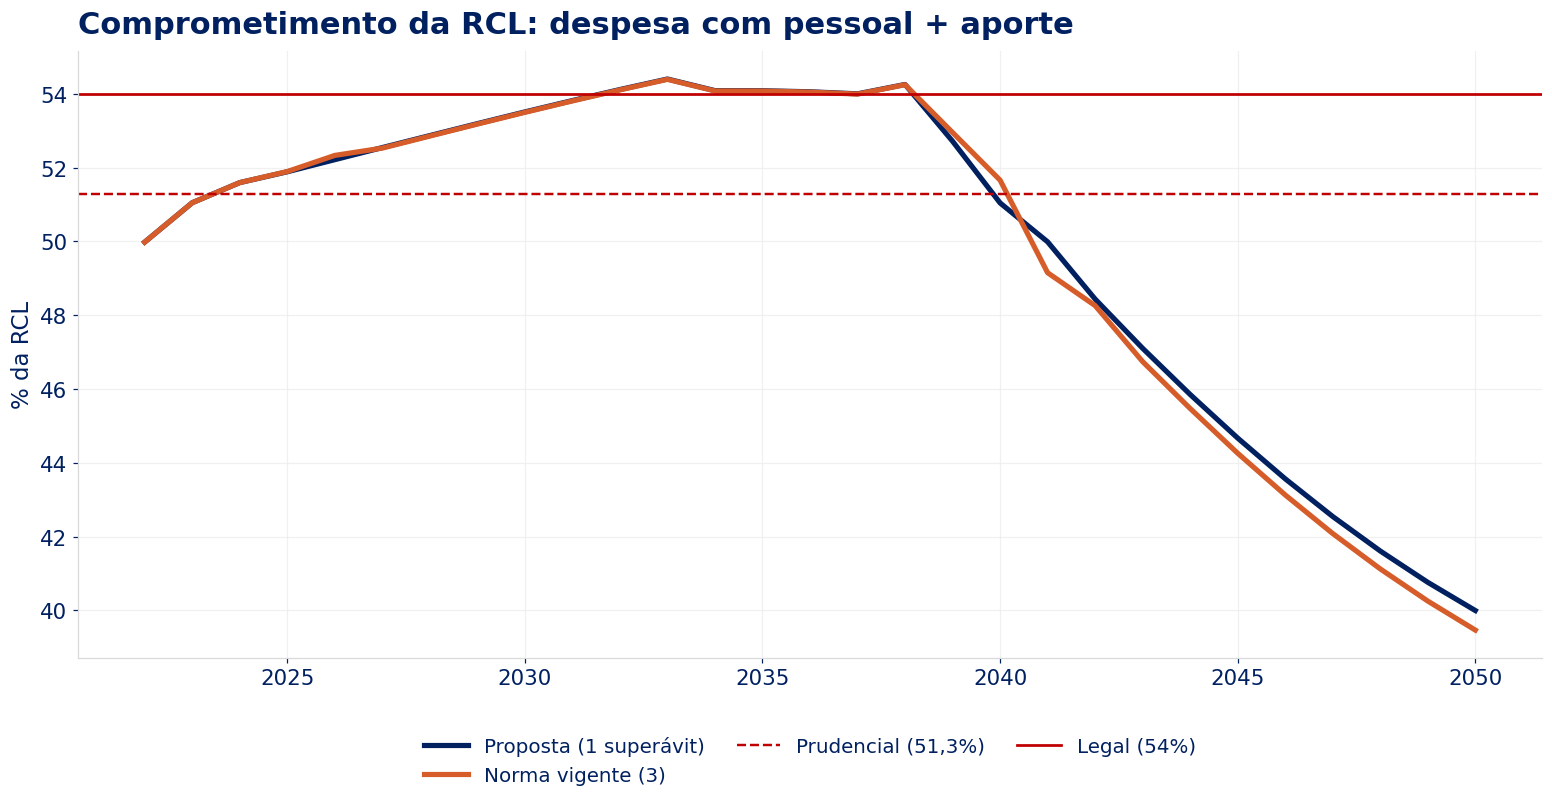

In [17]:
alt = cenario(cenarios["Segregação + dessegregação"], "Desseg. com 3 superávits (norma vigente)", n_superavits=3)
display(diferencas(alt, cenarios["Segregação + dessegregação"]))
res_alt = {"Proposta (1 superávit)": res["Segregação + dessegregação"], "Norma vigente (3)": simular(alt)}
grafico_comparativo(res_alt, MUN_A_PROJ)
plt.show()

## 8. (Após a palestra) Municípios a partir do pipeline do CADPREV

**Desligado por padrão** (`RODAR_CADPREV = False`). A leitura automática do CADPREV ainda tem lacunas
(ativos de municípios pequenos, resultado atuarial de alguns entes); os cinco municípios da palestra
usam os DRAA em PDF (seção 9).

In [18]:
RODAR_CADPREV = False

### Funções

Lê as tabelas brutas que o pipeline (`rpps_pipeline_v2`) grava em `RAIZ_PIPELINE/raw/*.parquet`,
fica com a **última remessa** de cada DRAA e extrai, por ente, exercício e plano (FC/FR), os dados que o
simulador precisa. Três regras de prudência:

1. **Parcelamentos fora dos ativos.** O valor atual dos parcelamentos de débitos previdenciários é deduzido
   dos ativos garantidores. Parcelamento é crédito contra o próprio ente, não ativo concreto do RPPS.
2. **Alerta de variação atípica dos ativos.** Saltos de um exercício para o outro que não se explicam por
   rentabilidade e resultado financeiro são sinalizados. Há entes que vincularam receitas de IRRF e as incluíram
   como ativo; o CADPREV não permite saber com certeza, e o TCE/RS considera essa inclusão inadequada.
   O alerta é **indício para conferência**, nunca conclusão.
3. **Validação contra os PDFs.** Antes de usar o CADPREV em escala, os valores extraídos são comparados com os
   DRAA em PDF já conferidos (gabarito abaixo).

**Nomes de colunas e itens:** os do `DRAA_VALORES_COMPROMISSOS` e do `DRAA_PLANO_CUSTEIO` seguem o pipeline.
Os das tabelas `DRAA_ESTATISTICA` e `DRAA_HIPOTESE_ATUARIAL` são **detectados automaticamente** e precisam
ser conferidos com `inspecionar()` na primeira execução; ajuste `MAPA_COLUNAS` se necessário.

In [19]:
import re, unicodedata

RAIZ_PIPELINE = "/content/drive/MyDrive/TCE/rpps_rs"
TABELAS_CADPREV = ["DRAA_VALORES_COMPROMISSOS", "DRAA_ESTATISTICA", "DRAA_HIPOTESE_ATUARIAL",
                   "DRAA_PLANO_CUSTEIO", "DRAA_PLANO_AMORTIZACAO", "DRAA_FLUXO_ATUARIAL"]


def _txt(v):
    t = unicodedata.normalize("NFKD", str(v))
    t = "".join(c for c in t if not unicodedata.combining(c)).lower()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9%]+", " ", t)).strip()


def _num(s):
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce")
    t = s.astype("string").str.strip()
    br = t.str.contains(",", na=False)
    t = t.where(~br, t.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(t.str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")


def _preparar(df):
    df = df.copy()
    if "nr_cnpj_entidade" in df:
        df["cnpj"] = df.nr_cnpj_entidade.astype("string").str.replace(r"\.0$", "", regex=True) \
                       .str.replace(r"[^0-9]", "", regex=True).str.zfill(14)
    if "dt_exercicio" in df:
        df["ano"] = pd.to_numeric(df.dt_exercicio.astype("string").str[:4], errors="coerce")
    if "dt_envio" in df:
        df["_envio"] = pd.to_datetime(df.dt_envio, errors="coerce")
        ult = df.groupby(["cnpj", "ano"])["_envio"].transform("max")
        df = df[(df._envio == ult) | ult.isna()]
    if "tp_plano" in df:
        df["plano"] = np.where(df.tp_plano.astype("string").str.contains("Financ", case=False, na=False), "FR", "FC")
    return df


def carregar_cadprev(raiz=RAIZ_PIPELINE, tabelas=TABELAS_CADPREV):
    cad = {}
    faltam = []
    for t in tabelas:
        arq = f"{raiz}/raw/{t}.parquet"
        if os.path.exists(arq):
            cad[t] = _preparar(pd.read_parquet(arq))
            print(f"{t:<28} {len(cad[t]):>8,} linhas")
        else:
            faltam.append(t)
            print(f"{t:<28} ausente")
    if faltam:
        print("\nPara baixar as ausentes, no notebook do pipeline:\n"
              f"    pipe.atualizar_raw({faltam})\n"
              "As funções seguem sem elas; os campos correspondentes usam o PDF ou o valor padrão.")
    return cad


def inspecionar(cad, tabela, cnpj=None, ano=None, n=8):
    """Mostra colunas, exemplo de linhas e, nas colunas de texto, os valores mais frequentes."""
    df = cad[tabela]
    if cnpj:
        df = df[df.cnpj == cnpj]
    if ano:
        df = df[df.ano == ano]
    print(tabela, df.shape)
    print(df.dtypes.to_string())
    display(df.head(n))
    for c in df.select_dtypes("object").columns[:6]:
        print(f"\n{c}:", df[c].value_counts().head(12).to_dict())

### 8.1 Itens do resultado atuarial e do custeio

In [20]:
# item do DRAA (texto normalizado, expressão regular) -> variável; 'soma' agrega linhas repetidas
ITENS_VALORES = {
    "ativos_garantidores": (r"^ativos garantidores dos compromissos", "max"),
    "pmbc": (r"^provisao matematica dos beneficios concedidos", "max"),
    "pmbac": (r"^provisao matematica dos beneficios a conceder", "max"),
    "va_parcelamentos": (r"^valor atual dos parcelamentos", "max"),
    "va_plano_amortizacao": (r"^valor atual do plano de amortizacao", "max"),
    "cobertura_insuficiencia": (r"cobertura de insuficiencia", "max"),
    "deficit_atuarial": (r"^deficit atuarial$", "max"),
    "superavit_atuarial": (r"^superavit atuarial$", "max"),
    "comprev_receber": (r"compensacao previdenciaria a receber", "soma"),
    "receitas_estimadas": (r"total de receitas estimadas", "max"),
    "despesas_estimadas": (r"total de despesas estimadas", "max"),
}


def _maior_abs(s):
    """Valor de maior módulo do grupo, preservando o sinal; NaN se o grupo estiver vazio."""
    s = s.dropna()
    return np.nan if s.empty else s.loc[s.abs().idxmax()]


def _exige(cad, tabela):
    if tabela not in cad:
        raise KeyError(f"Tabela {tabela} não carregada. No pipeline: pipe.atualizar_raw(['{tabela}'])")


# Componentes usados quando o total não vem como item próprio (layout antigo do DRAA, ex. 2022)
COMPONENTES = {
    "ativos": r"^(?:aplicacoes em segmento|disponibilidades|demais bens|titulos|investimentos)",
    "enc_conc": r"^beneficios concedidos encargos",
    "contr_conc": r"^beneficios concedidos contribuicoes",
    "comprev_conc": r"^beneficios concedidos compensacao previdenciaria a receber",
    "comprev_pag_conc": r"^beneficios concedidos encargos compensacao previdenciaria a pagar",
    "enc_conced": r"^beneficios a conceder encargos",
    "contr_conced": r"^beneficios a conceder contribuicoes",
    "comprev_conced": r"^beneficios a conceder compensacao previdenciaria a receber",
    "comprev_pag_conced": r"^beneficios a conceder encargos compensacao previdenciaria a pagar",
}


def _completar_por_componentes(v, df):
    """Preenche ativos, PMBC e PMBAC a partir dos componentes quando o total está ausente.
    Cada item entra uma vez (maior módulo das linhas repetidas) e depois soma-se por grupo."""
    ch = ["cnpj", "ano", "plano"]
    tot = {}
    for nome, pad in COMPONENTES.items():
        x = v[v.item.str.contains(pad, regex=True, na=False)]
        if nome.startswith("enc_"):          # encargos sem a compensação a pagar
            x = x[~x.item.str.contains("compensacao previdenciaria a pagar")]
        por_item = x.groupby(ch + ["item"]).valor.agg(_maior_abs).abs()
        tot[nome] = por_item.groupby(level=[0, 1, 2]).sum(min_count=1)
    c = pd.DataFrame(tot).reset_index()
    for k in COMPONENTES:
        if k not in c:
            c[k] = np.nan
    f = lambda a: c[a].fillna(0)
    c["pmbc_comp"] = f("enc_conc") + f("comprev_pag_conc") - f("contr_conc") - f("comprev_conc")
    c["pmbac_comp"] = f("enc_conced") + f("comprev_pag_conced") - f("contr_conced") - f("comprev_conced")
    c.loc[c.enc_conc.isna(), "pmbc_comp"] = np.nan
    c.loc[c.enc_conced.isna(), "pmbac_comp"] = np.nan
    c = c.rename(columns={"ativos": "ativos_comp"})
    df = df.merge(c[ch + ["ativos_comp", "pmbc_comp", "pmbac_comp"]], on=ch, how="outer")
    # Só os ativos são completados por componentes. Provisões por componentes mostraram-se
    # inconsistentes (itens com nomes e agregações que variam entre exercícios).
    for alvo, comp in (("ativos_garantidores", "ativos_comp"),):
        usa = df[alvo].isna() & df[comp].notna()
        df[f"origem_{alvo}"] = np.where(df[alvo].notna(), "total", np.where(usa, "componentes", "ausente"))
        df.loc[usa, alvo] = df.loc[usa, comp]
    return df


def extrair_valores(cad, cnpj=None):
    _exige(cad, "DRAA_VALORES_COMPROMISSOS")
    v = cad["DRAA_VALORES_COMPROMISSOS"]
    if cnpj:
        v = v[v.cnpj == cnpj]
    v = v.assign(item=v.ds_item_resultado.map(_txt), valor=_num(v.vl_geracao_atual))
    if v.empty:
        print(f"Sem linhas em DRAA_VALORES_COMPROMISSOS para o CNPJ {cnpj}: confira o CNPJ")
    saida = []
    for var, (padrao, agg) in ITENS_VALORES.items():
        x = v[v.item.str.contains(padrao, regex=True, na=False)]
        if x.empty:
            continue
        g = x.groupby(["cnpj", "ano", "plano"]).valor
        r = g.sum(min_count=1) if agg == "soma" else g.agg(_maior_abs)
        saida.append(r.rename(var))
    if not saida:
        raise ValueError("Nenhum item reconhecido: confira ITENS_VALORES com inspecionar(cad, 'DRAA_VALORES_COMPROMISSOS')")
    df = pd.concat(saida, axis=1).reset_index()
    for c in ITENS_VALORES:
        if c not in df:
            df[c] = np.nan
    df = _completar_por_componentes(v, df)
    # Parcelamentos: a validação contra os PDFs (Pelotas, São Leopoldo, Sant'Ana, Santa Vitória) mostrou
    # que o item "Ativos garantidores" do CADPREV é o do QUADRO DE RESULTADOS, que já exclui os
    # parcelamentos. Deduzi-los de novo os tiraria duas vezes. A regra de prudência está atendida pela fonte.
    df["ativos_sem_parcelamentos"] = df.ativos_garantidores
    # Resultado antes do plano (art. 50, VI), pela via declarada no DRAA:
    #   resultado declarado = superávit − |déficit|
    #   deduções = item "cobertura de insuficiências assegurada por lei" (no DRAA ele soma plano de
    #              amortização + parcelamentos + cobertura do FR); se ausente, plano + parcelamentos
    declarado = df.superavit_atuarial.fillna(0).abs() - df.deficit_atuarial.fillna(0).abs()
    tem_declarado = df.superavit_atuarial.notna() | df.deficit_atuarial.notna()
    soma = df.va_plano_amortizacao.fillna(0).abs() + df.va_parcelamentos.fillna(0).abs()
    cob = df.cobertura_insuficiencia.abs()
    deducoes = np.where(cob.fillna(0) > 0, np.maximum(cob.fillna(0), soma), soma)
    df["resultado_antes_plano"] = np.where(tem_declarado, declarado - deducoes, np.nan)
    df["resultado_por_provisoes"] = df.ativos_sem_parcelamentos - df.pmbc - df.pmbac   # conferência
    return df


def extrair_custeio(cad, cnpj=None):
    if "DRAA_PLANO_CUSTEIO" not in cad:
        print("DRAA_PLANO_CUSTEIO ausente: alíquotas ficarão com os valores padrão")
        return pd.DataFrame(columns=["cnpj", "ano", "plano", "aliq_ente_normal", "aliq_servidor", "base_anual"])
    c = cad["DRAA_PLANO_CUSTEIO"]
    if cnpj:
        c = c[c.cnpj == cnpj]
    c = c.assign(tipo=c.tp_contribuicao.map(_txt), aliq=_num(c.vl_aliquota) / 100,
                 base=_num(c.vl_anual_base_calculo))
    ente = c.tipo.str.startswith("ente federativo") & ~c.tipo.str.contains("total|administra|aporte")
    serv = c.tipo.str.startswith("segurados ativos")
    ch = ["cnpj", "ano", "plano"]
    out = pd.concat([c[ente].groupby(ch).aliq.max().rename("aliq_ente_normal"),
                     c[serv].groupby(ch).aliq.max().rename("aliq_servidor"),
                     c[ente].groupby(ch).base.max().rename("base_anual")], axis=1).reset_index()
    if "DRAA_PLANO_AMORTIZACAO" in cad:
        a = cad["DRAA_PLANO_AMORTIZACAO"]
        if cnpj:
            a = a[a.cnpj == cnpj]
        a = a.assign(ano_plano=pd.to_numeric(a.dt_ano.astype("string").str[:4], errors="coerce"),
                     aliq_sup=_num(a.get("vl_aliquotas", pd.Series(np.nan, index=a.index))) / 100,
                     aporte=_num(a.get("vl_aporte", pd.Series(np.nan, index=a.index))),
                     base_sup=_num(a.get("vl_base_calculo", pd.Series(np.nan, index=a.index))))
        a = a[a.ano_plano >= a.ano].sort_values("ano_plano").groupby(["cnpj", "ano", "plano"]).first()
        out = out.merge(a[["aliq_sup", "aporte", "base_sup"]].reset_index(), on=["cnpj", "ano", "plano"], how="left")
    return out

def diagnosticar_itens(cad, cnpj, anos=None):
    """Lista os itens de DRAA_VALORES_COMPROMISSOS de um ente, por ano e plano, e indica quais
    foram reconhecidos por ITENS_VALORES. Use para ajustar as expressões quando a validação falhar."""
    v = cad["DRAA_VALORES_COMPROMISSOS"]
    v = v[v.cnpj == cnpj]
    if anos:
        v = v[v.ano.isin(anos)]
    v = v.assign(item_norm=v.ds_item_resultado.map(_txt), valor=_num(v.vl_geracao_atual))
    def reconhece(t):
        for var, (pad, _) in ITENS_VALORES.items():
            if re.search(pad, t):
                return var
        return ""
    v["variavel"] = v.item_norm.map(reconhece)
    t = v.groupby(["ano", "plano", "ds_item_resultado", "variavel"]).valor.agg(["count", "max"]).reset_index()
    t = t.sort_values(["ano", "plano", "variavel"])
    t.to_csv("/content/itens_draa_diagnostico.csv" if EM_COLAB else "itens_draa_diagnostico.csv", index=False)
    return t


def diagnosticar_resultado(cad, cnpj, ano, padrao="garant|superavit|deficit|cobertura|parcelament|aplicac|disponib"):
    """Linhas brutas de um ente/ano com TODAS as colunas de valor (vl_*): mostra se o número está noutra coluna
    (ex.: gerações futuras) ou noutra massa/remessa."""
    v = cad["DRAA_VALORES_COMPROMISSOS"]
    v = v[(v.cnpj == cnpj) & (v.ano == ano)]
    v = v[v.ds_item_resultado.map(_txt).str.contains(padrao, regex=True, na=False)]
    cols = ["plano", "tp_massa", "dt_envio", "ds_item_resultado"] + [c for c in v.columns if c.startswith("vl_")]
    with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
        display(v[[c for c in cols if c in v.columns]].sort_values(["plano", "ds_item_resultado"]))

### 8.2 Estatísticas da massa e hipóteses (colunas detectadas — conferir)

In [21]:
MAPA_COLUNAS = {   # None = detectar automaticamente; preencha com o nome real se a detecção falhar
    "estat_categoria": None, "estat_quantidade": None, "estat_valor_medio": None, "estat_idade": None,
    "hip_descricao": None, "hip_valor": None,
}


def _achar(df, chave, padroes):
    if MAPA_COLUNAS.get(chave):
        return MAPA_COLUNAS[chave]
    for p in padroes:
        for c in df.columns:
            if re.search(p, c, re.I):
                return c
    return None


# códigos de população do CADPREV -> grupo (preencher após diagnosticar_estatistica, se a descrição não vier)
MAPA_POPULACAO = {}


def _col_texto_populacao(e):
    """Coluna com o TIPO de população (Servidores, Servidores Iminentes, Aposentados, Pensionistas).
    Não usar no_cat_populacao: ela traz a categoria funcional (Professores, Demais Servidores)."""
    for c in ("tp_populacao", "ds_tipo_populacao", "ds_populacao"):
        if c in e.columns:
            return c
    return None


def _classificar(t):
    t = _txt(t)
    if "pension" in t:
        return "pens"
    if "aposent" in t:
        return "apos"
    if "iminente" in t:
        return "iminentes"
    if "servidor" in t or "ativo" in t:
        return "ativos"
    return "outro"


INCLUIR_IMINENTES_EM_ATIVOS = True   # servidores iminentes são ativos (já elegíveis à aposentadoria)


def diagnosticar_estatistica(cad, cnpj, ano):
    """Totais de pessoas por fundo e tipo de população, com as colunas que podem separar
    a previdência complementar (no_regra_enquadramento, te_situacao, tp_massa)."""
    e = cad["DRAA_ESTATISTICA"]
    e = e[(e.cnpj == cnpj) & (e.ano == ano)].copy()
    e["pessoas"] = _num(e.qt_grupo_masc).fillna(0) + _num(e.qt_grupo_fem).fillna(0)
    for c in ("tp_populacao", "no_regra_enquadramento", "te_situacao", "tp_massa"):
        if c in e:
            print(f"\n— pessoas por plano × {c}")
            print(e.pivot_table(index=c, columns="plano", values="pessoas", aggfunc="sum").fillna(0).to_string())


def extrair_massa(cad, cnpj=None):
    e = cad.get("DRAA_ESTATISTICA")
    if e is None:
        return pd.DataFrame()
    if cnpj:
        e = e[e.cnpj == cnpj]
    e = e.copy()
    # quantidade, valor médio e idade vêm separados por sexo: soma e média ponderada
    def par(prefixo):
        m = [c for c in e.columns if re.search(prefixo + r".*masc", c, re.I)]
        f = [c for c in e.columns if re.search(prefixo + r".*fem", c, re.I)]
        return (m[0] if m else None), (f[0] if f else None)
    qm, qf = par(r"^qt_")
    vm, vf = par(r"^vl_medio")
    im, i_f = par(r"idade_media")
    if not (qm or qf):
        print("Quantidades por sexo não encontradas. Colunas:", list(e.columns))
        return pd.DataFrame()
    z = lambda c: _num(e[c]).fillna(0) if c else 0
    e["qM"], e["qF"] = z(qm), z(qf)
    e["q"] = e.qM + e.qF
    e["vxq"] = z(vm) * e.qM + z(vf) * e.qF
    e["ixq"] = z(im) * e.qM + z(i_f) * e.qF
    chave_dup = [c for c in ("cnpj", "ano", "plano", "cnpj_orgao", "cd_populacao", "no_cat_populacao",
                             "no_regra_enquadramento", "no_criterio_aposentadoria",
                             "qt_grupo_masc", "qt_grupo_fem") if c in e.columns]
    n0 = len(e)
    e = e.drop_duplicates(chave_dup)
    if len(e) < n0 and cnpj:
        print(f"  estatística: {n0 - len(e)} linhas duplicadas removidas ({cnpj})")
    ct = _col_texto_populacao(e)
    cc = next((c for c in e.columns if re.search(r"^cd_.*popul", c, re.I)), None)
    if ct:
        e["grupo"] = e[ct].map(_classificar)
    elif cc and MAPA_POPULACAO:
        e["grupo"] = e[cc].astype(str).map(MAPA_POPULACAO).fillna("outro")
    else:
        print(f"Sem descrição da população (só o código '{cc}'). Rode diagnosticar_estatistica(...) "
              "e preencha MAPA_POPULACAO = {código: 'ativos' | 'apos' | 'pens'}")
        return pd.DataFrame()
    global _AVISO_ESTAT
    if not globals().get("_AVISO_ESTAT"):
        print(f"ESTATÍSTICA — população: {ct or cc} · quantidade: {qm} + {qf} · valor: {vm} + {vf} · idade: {im} + {i_f}")
        _AVISO_ESTAT = True
    e = e[e.grupo != "outro"]
    if INCLUIR_IMINENTES_EM_ATIVOS:
        e = pd.concat([e, e[e.grupo == "iminentes"].assign(grupo="ativos")])
    g = e.groupby(["cnpj", "ano", "plano", "grupo"])[["q", "vxq", "ixq"]].sum()
    g["n"] = g.q
    g["valor_medio"] = np.where(g.q > 0, g.vxq / g.q.replace(0, np.nan), np.nan)
    g["idade_media"] = np.where(g.q > 0, g.ixq / g.q.replace(0, np.nan), np.nan)
    w = g[["n", "valor_medio", "idade_media"]].unstack("grupo")
    w.columns = [f"{a}_{b}" for a, b in w.columns]
    return w.reset_index()


def extrair_hipoteses(cad, cnpj=None):
    h = cad.get("DRAA_HIPOTESE_ATUARIAL")
    if h is None:
        return pd.DataFrame()
    if cnpj:
        h = h[h.cnpj == cnpj]
    cd = _achar(h, "hip_descricao", [r"^ds_", r"descri", r"hipotese"])
    cv = _achar(h, "hip_valor", [r"^vl_", r"valor"])
    print(f"HIPÓTESES — descrição: {cd} · valor: {cv}")
    if not all([cd, cv]):
        return pd.DataFrame()
    h = h.assign(d=h[cd].map(_txt), v=_num(h[cv]))
    pega = lambda padrao, nome: h[h.d.str.contains(padrao)].groupby(["cnpj", "ano", "plano"]).v.first().rename(nome)
    return pd.concat([pega(r"taxa de juros real", "juros_pct"),
                      pega(r"crescimento real do salario", "g_sal_pct"),
                      pega(r"crescimento real dos beneficios", "g_ben_pct")], axis=1).reset_index()

### 8.3 Gabarito: valores conferidos nos DRAA em PDF
Extraídos em 05/10 dos PDFs. `ag_quadro` é o ativo do quadro de resultados (sem parcelamentos);
`ag_comparativo` é o da tabela comparativa (em alguns entes, com parcelamentos). Valores em R$ milhões.

In [22]:
GABARITO_PDF = pd.DataFrame([
    # ente, ano, plano, ativos, aposentados, pensionistas, ag_quadro, ag_comparativo, resultado_antes_plano, juros %, aliq ente %
    ("Canoas", 2026, "FC", 2694, 258, 639, 1241.9, 1241.87, 199.3, 5.72, 15.00),
    ("Canoas", 2026, "FR", 525, 2938, 3, 1.4, 1.41, -3805.8, 5.57, 15.00),
    ("Caxias do Sul", 2022, "FC", 6972, 3995, 720, 419.1, 419.09, -6485.1, 4.88, 14.92),
    ("Caxias do Sul", 2023, "FC", 4095, 925, 535, 442.3, 442.27, 51.2, 4.50, 26.00),
    ("Caxias do Sul", 2023, "FR", 2914, 3214, 176, 0.0, 0.00, -5217.6, 4.50, 26.00),
    ("Caxias do Sul", 2024, "FC", 4342, 882, 525, 545.5, 545.51, 36.1, 4.50, 26.00),
    ("Caxias do Sul", 2024, "FR", 2667, 3387, 189, 0.73, 0.73, -5454.6, 4.50, 26.00),
    ("Caxias do Sul", 2025, "FC", 4685, 844, 519, 652.8, 652.77, 63.4, 4.50, 26.00),
    ("Caxias do Sul", 2025, "FR", 2431, 3570, 200, 1.27, 1.27, -5958.4, 4.50, 26.00),
    ("Caxias do Sul", 2026, "FC", 5122, 800, 476, 776.6, 776.64, 117.3, 4.50, 26.00),
    ("Caxias do Sul", 2026, "FR", 2237, 3723, 172, 0.97, 0.97, -6573.5, 4.50, 26.00),
    ("Estrela", 2026, "FC", 583, 30, 14, 116.5, 116.48, 36.9, 5.34, 19.74),
    ("Estrela", 2026, "FR", 92, 306, 61, 5.2, 6.29, -228.0, 5.37, 19.74),
    ("Itaqui", 2026, "FC", 342, 91, 90, 124.8, 126.94, 25.6, 4.50, 15.00),
    ("Itaqui", 2026, "FR", 518, 482, 51, 0.8, 4.79, -593.2, 5.41, 26.00),
    ("Jaguari", 2026, "FC", 123, 59, 15, 23.7, 27.46, -0.4, 4.50, 13.50),
    ("Jaguari", 2026, "FR", 143, 126, 14, 0.1, 6.32, -153.9, 4.50, 25.00),
    ("Jaguarão", 2026, "FC", 523, 129, 9, 109.1, 109.07, 11.0, 4.50, 18.00),
    ("Jaguarão", 2026, "FR", 248, 190, 29, 3.6, 3.59, -292.5, 4.50, 26.00),
    ("Pelotas", 2026, "FC", 4148, 444, 475, 698.9, 754.00, -44.1, 4.50, 16.00),
    ("Pelotas", 2026, "FR", 2920, 2234, 22, 8.0, 40.83, -2878.5, 4.50, 26.00),
    ("Porto Alegre", 2026, "FC", 10154, 808, 1322, 5241.3, 5241.35, 795.4, 5.30, 16.57),
    ("Porto Alegre", 2026, "FR", 2885, 12570, 2994, 0.0, 0.00, -21046.0, 5.33, 19.60),
    ("Santa Vitória do Palmar", 2026, "FC", 620, 218, 90, 107.2, 393.30, -109.3, 5.74, 15.57),
    ("Santa Vitória do Palmar", 2026, "FR", 349, 218, 7, 0.0, 0.02, -376.4, 5.59, 15.57),
    ("Sant'Ana do Livramento", 2026, "FC", 1113, 206, 167, 88.7, 234.36, -66.7, 4.50, 16.70),
    ("Sant'Ana do Livramento", 2026, "FR", 709, 572, 143, 10.4, 188.32, -861.4, 4.50, 25.70),
    ("São Leopoldo", 2026, "FC", 1993, 90, 22, 466.6, 483.72, 56.6, 5.55, 15.22),
    ("São Leopoldo", 2026, "FR", 1800, 2024, 334, 88.2, 306.12, -2466.7, 5.42, 14.38),
    ("São Lourenço do Sul", 2026, "FC", 510, 28, 2, 118.2, 118.26, -27.5, 5.37, 17.80),
    ("São Lourenço do Sul", 2026, "FR", 350, 534, 71, 0.6, 0.61, -673.1, 5.35, 12.40),
], columns=["ente", "ano", "plano", "n_ativos", "n_apos", "n_pens", "ag_quadro_mi", "ag_comparativo_mi",
            "resultado_antes_plano_mi", "juros_pct", "aliq_ente_pct"])

# CNPJ do ente — Caxias conferido no PDF; os demais são buscados pelo nome em buscar_cnpjs()
CNPJ_ENTE = {"Caxias do Sul": "88830609000139"}


def buscar_cnpjs(cad, nomes):
    """Procura o CNPJ do ente pelo nome (coluna no_ente da estatística). Mostra os candidatos."""
    e = cad["DRAA_ESTATISTICA"][["cnpj", "no_ente"]].drop_duplicates()
    e["chave"] = e.no_ente.map(_txt)
    achados = {}
    for n in nomes:
        k = _txt(n).replace("sant ana", "santana")
        c = e[e.chave.str.replace("sant ana", "santana").str.contains(rf"\b{k}$", regex=True)]
        if len(c.cnpj.unique()) == 1:
            achados[n] = c.cnpj.iloc[0]
        else:
            print(f"{n}: {len(c.cnpj.unique())} candidatos", c[["cnpj", "no_ente"]].values.tolist()[:5])
    return achados

### 8.4 Validação CADPREV × PDF
Para cada linha do gabarito, compara o que o CADPREV traz. O ponto mais importante é saber **qual definição
de ativos o CADPREV usa**: se coincide com `ag_comparativo`, os parcelamentos estão embutidos e a dedução
está correta; se coincide com `ag_quadro` já antes da dedução, a dedução os estaria tirando duas vezes.

In [23]:
def validar_contra_pdf(cad, gabarito=GABARITO_PDF, cnpjs=CNPJ_ENTE, tol=0.02):
    linhas = []
    for ente, cnpj in cnpjs.items():
        val = extrair_valores(cad, cnpj)
        cus = extrair_custeio(cad, cnpj)
        mas = extrair_massa(cad, cnpj)
        hip = extrair_hipoteses(cad, cnpj)
        for _, g in gabarito[gabarito.ente == ente].iterrows():
            k = dict(cnpj=cnpj, ano=g.ano, plano=g.plano)
            pick = lambda df, c: (df.loc[(df.cnpj == cnpj) & (df.ano == g.ano) & (df.plano == g.plano), c].iloc[0]
                                  if (not df.empty and c in df and ((df.cnpj == cnpj) & (df.ano == g.ano) & (df.plano == g.plano)).any())
                                  else np.nan)
            ag = pick(val, "ativos_garantidores") / 1e6
            ag_liq = pick(val, "ativos_sem_parcelamentos") / 1e6
            comp = [
                ("ativos garantidores (quadro de resultados)", g.ag_quadro_mi, ag_liq),
                ("resultado antes do plano", g.resultado_antes_plano_mi, pick(val, "resultado_antes_plano") / 1e6),
                ("alíquota do ente (%)", g.aliq_ente_pct, pick(cus, "aliq_ente_normal") * 100),
                ("juros (%)", g.juros_pct, pick(hip, "juros_pct")),
                ("ativos (pessoas)", g.n_ativos, pick(mas, "n_ativos")),
                ("aposentados", g.n_apos, pick(mas, "n_apos")),
                ("pensionistas", g.n_pens, pick(mas, "n_pens")),
            ]
            for nome, pdf, cadv in comp:
                dif = (cadv - pdf) / abs(pdf) if pd.notna(cadv) and pdf else np.nan
                cadv = float(cadv) if pd.notna(cadv) else np.nan
                if pd.notna(dif):
                    ok = abs(dif) <= tol or ("ativos" in nome and abs(cadv - pdf) <= 0.06) \
                         or ("resultado" in nome and abs(cadv - pdf) <= 0.6)
                else:
                    ok = pdf == 0 and pd.notna(cadv) and abs(cadv) < 0.05
                linhas.append(dict(ente=ente, ano=g.ano, plano=g.plano, campo=nome, pdf=pdf, cadprev=cadv,
                                   dif_pct=100 * dif if pd.notna(dif) else np.nan, ok=ok,
                                   ausente_no_cadprev=pd.isna(cadv)))
    t = pd.DataFrame(linhas)
    if not t.empty:
        r = t.groupby("campo").agg(conferido=("ok", "mean"), ausente=("ausente_no_cadprev", "mean"))
        print("Resumo da conferência (% das linhas do gabarito):\n", (100 * r).round(0).to_string())
        d = gabarito.assign(dif=gabarito.ag_comparativo_mi - gabarito.ag_quadro_mi)
        d = d[d.dif.abs() > 0.5]
        if len(d):
            print("\nAtivos do comparativo maiores que os do quadro (parcelamentos ou outros valores — conferir):")
            print(d[["ente", "ano", "plano", "ag_quadro_mi", "ag_comparativo_mi", "dif"]].round(1).to_string(index=False))
    return t

### 8.5 Alerta de variação atípica dos ativos garantidores

Para cada ente e fundo, compara o ativo (sem parcelamentos) com o esperado:

esperado(t) = ativo(t−1) × (1 + juros) + [receitas estimadas − despesas estimadas](t−1)

**Variação inexplicada** = (ativo(t) − esperado(t)) ÷ ativo(t−1). Sem receitas e despesas estimadas,
usa só a variação bruta. Anos de segregação, revisão ou mudança de plano devem ser lidos à parte.

In [24]:
LIMIAR_VAR_BRUTA = 0.30      # crescimento acima de 30% num exercício
LIMIAR_INEXPLICADA = 0.20    # e variação inexplicada acima de 20% do ativo anterior
ATIVO_MINIMO = 5e6           # ignora fundos muito pequenos (ruído)


CNPJ_EXCLUIR = {"87934675000196"}   # Estado do RS (fora do escopo municipal)


def alerta_ativos(cad, cnpj=None, juros=0.045):
    v = extrair_valores(cad, cnpj)
    v = v[~v.cnpj.isin(CNPJ_EXCLUIR)].sort_values(["cnpj", "plano", "ano"])
    g = v.groupby(["cnpj", "plano"])
    v["ag_ant"] = g.ativos_sem_parcelamentos.shift()
    v["fluxo_ant"] = (g.receitas_estimadas.shift() - g.despesas_estimadas.shift())
    v["var_bruta"] = v.ativos_sem_parcelamentos / v.ag_ant - 1
    esperado = v.ag_ant * (1 + juros) + v.fluxo_ant.fillna(0)
    v["var_inexplicada"] = (v.ativos_sem_parcelamentos - esperado) / v.ag_ant
    v["fluxo_disponivel"] = v.fluxo_ant.notna()
    v["origem_ant"] = g.origem_ativos_garantidores.shift()
    cond = (v.ag_ant > ATIVO_MINIMO) & (v.var_bruta > LIMIAR_VAR_BRUTA) & \
           ((v.var_inexplicada > LIMIAR_INEXPLICADA) | ~v.fluxo_disponivel)
    v["alerta"] = cond
    # anos de início da segregação: primeiro exercício com plano FR (e o seguinte)
    ini = v[v.plano == "FR"].groupby("cnpj").ano.min().rename("ano_seg")
    v = v.merge(ini, on="cnpj", how="left")
    seg = v.ano_seg.notna() & v.ano.between(v.ano_seg, v.ano_seg + 1)
    comp = (v.origem_ativos_garantidores == "componentes") | (v.origem_ant == "componentes")
    v["leitura"] = np.select(
        [seg, comp, ~v.fluxo_disponivel],
        ["início de segregação (salto esperado)", "base diferente (total × componentes)", "sem fluxo informado"],
        "A CONFERIR")
    a = v[v.alerta][["cnpj", "plano", "ano", "ag_ant", "ativos_sem_parcelamentos", "var_bruta",
                     "var_inexplicada", "fluxo_disponivel", "leitura"]].copy()
    a[["ag_ant", "ativos_sem_parcelamentos"]] /= 1e6
    return a.rename(columns={"ag_ant": "ativo_anterior_mi", "ativos_sem_parcelamentos": "ativo_atual_mi"})

### 8.6 Montar o cenário de um município
Junta CADPREV (massa, ativos, alíquotas, hipóteses) e base fiscal do TCE (RCL, DTP, dívida).
Devolve o cenário e uma tabela com **a origem de cada número**. O que não vier do CADPREV fica com o valor padrão
de `BASE` e aparece como "padrão" na tabela de origens.

In [25]:
def montar_municipio(cad, cnpj, ano, rotulo, municipio_fiscal, base=BASE, gabarito_ente=None, **ajustes):
    val, cus = extrair_valores(cad, cnpj), extrair_custeio(cad, cnpj)
    mas, hip = extrair_massa(cad, cnpj), extrair_hipoteses(cad, cnpj)
    sel = lambda df, plano: df[(df.ano == ano) & (df.plano == plano)] if not df.empty else df
    origem, p = [], dict()

    def usa(chave, valor, fonte):
        if valor is not None and pd.notna(valor):
            p[chave] = valor
            origem.append((chave, valor, fonte))

    fc_m, fr_m = sel(mas, "FC"), sel(mas, "FR")
    if not fc_m.empty:
        r = fc_m.iloc[0]
        usa("n_ativos", int(r.get("n_ativos", np.nan)) if pd.notna(r.get("n_ativos")) else None, "CADPREV estatística")
        usa("n_apos", int(r.get("n_apos", 0) or 0), "CADPREV estatística")
        usa("n_pens", int(r.get("n_pens", 0) or 0), "CADPREV estatística")
        usa("idade_ativos", r.get("idade_media_ativos"), "CADPREV estatística")
        usa("sal_mensal", r.get("valor_medio_ativos"), "CADPREV estatística")
        nb = (r.get("n_apos", 0) or 0) + (r.get("n_pens", 0) or 0)
        if nb:
            usa("ben_mensal", np.nansum([r.get("valor_medio_apos", np.nan) * (r.get("n_apos", 0) or 0),
                                         r.get("valor_medio_pens", np.nan) * (r.get("n_pens", 0) or 0)]) / nb,
                "CADPREV estatística (média ponderada)")
            usa("idade_benef", np.nansum([r.get("idade_media_apos", np.nan) * (r.get("n_apos", 0) or 0),
                                          r.get("idade_media_pens", np.nan) * (r.get("n_pens", 0) or 0)]) / nb,
                "CADPREV estatística (média ponderada)")

    v_fc = sel(val, "FC")
    g_fc = (gabarito_ente[(gabarito_ente.ano == ano) & (gabarito_ente.plano == "FC")]
            if gabarito_ente is not None else pd.DataFrame())
    if not g_fc.empty:                                    # PDF conferido tem prioridade para os ativos
        usa("ativos0", float(g_fc.ag_quadro_mi.iloc[0]) * 1e6, "PDF do DRAA (quadro de resultados)")
        if not v_fc.empty:
            cad_v = float(v_fc.ativos_sem_parcelamentos.iloc[0]) / 1e6
            print(f"  ativos FC: PDF {g_fc.ag_quadro_mi.iloc[0]:,.1f} mi · CADPREV {cad_v:,.1f} mi")
    elif not v_fc.empty:
        usa("ativos0", float(v_fc.ativos_sem_parcelamentos.iloc[0]), "CADPREV (quadro de resultados)")
    c_fc, c_fr = sel(cus, "FC"), sel(cus, "FR")
    if not c_fc.empty:
        usa("pat0", c_fc.aliq_ente_normal.iloc[0], "CADPREV plano de custeio (ente, normal)")
        if "aliq_sup" in c_fc and pd.notna(c_fc.aliq_sup.iloc[0]) and c_fc.aliq_sup.iloc[0] > 0:
            usa("aliq_sup0", c_fc.aliq_sup.iloc[0], "CADPREV plano de amortização (1º ano)")
        elif "aporte" in c_fc and pd.notna(c_fc.aporte.iloc[0]) and c_fc.base_anual.iloc[0] > 0:
            usa("aliq_sup0", c_fc.aporte.iloc[0] / c_fc.base_anual.iloc[0], "CADPREV aporte ÷ base (equivalente)")
    h_fc = sel(hip, "FC")
    if not h_fc.empty:
        usa("juros", h_fc.juros_pct.iloc[0] / 100, "CADPREV hipóteses")
        usa("retorno", h_fc.juros_pct.iloc[0] / 100, "= juros")
        usa("g_sal", h_fc.g_sal_pct.iloc[0] / 100, "CADPREV hipóteses")
        usa("g_ben_aval", h_fc.g_ben_pct.iloc[0] / 100, "CADPREV hipóteses")

    if not fr_m.empty:
        r = fr_m.iloc[0]
        nb = (r.get("n_apos", 0) or 0) + (r.get("n_pens", 0) or 0)
        mfr = dict(n_ativos=int(r.get("n_ativos", 0) or 0), n_apos=int(r.get("n_apos", 0) or 0),
                   n_pens=int(r.get("n_pens", 0) or 0),
                   idade_ativos=r.get("idade_media_ativos", base["idade_ativos"]),
                   sal_mensal=r.get("valor_medio_ativos", base["sal_mensal"]),
                   ben_mensal=(np.nansum([r.get("valor_medio_apos", 0) * (r.get("n_apos", 0) or 0),
                                          r.get("valor_medio_pens", 0) * (r.get("n_pens", 0) or 0)]) / nb) if nb else base["ben_mensal"],
                   idade_benef=(np.nansum([r.get("idade_media_apos", 0) * (r.get("n_apos", 0) or 0),
                                           r.get("idade_media_pens", 0) * (r.get("n_pens", 0) or 0)]) / nb) if nb else base["idade_benef"])
        mfr = {k: (base[k] if (v is None or (isinstance(v, float) and np.isnan(v))) else v) for k, v in mfr.items()}
        usa("ja_segregado", True, "CADPREV: há plano Financeiro")
        usa("massa_FR", mfr, "CADPREV estatística do FR")
        if not c_fr.empty:
            usa("pat_FR", c_fr.aliq_ente_normal.iloc[0], "CADPREV plano de custeio do FR")

    if gabarito_ente is not None:                       # preenche lacunas com o PDF conferido
        for _, g in gabarito_ente[(gabarito_ente.ano == ano) & (gabarito_ente.plano == "FC")].iterrows():
            for chave, col, conv in (("n_ativos", "n_ativos", int), ("n_apos", "n_apos", int),
                                     ("n_pens", "n_pens", int), ("ativos0", "ag_quadro_mi", lambda x: x * 1e6)):
                if chave not in p:
                    usa(chave, conv(g[col]), "PDF do DRAA (gabarito)")

    q = cenario(base, nome=rotulo, ano_base=ano, **p)
    q = calibrar_fiscal(q, FISCAL, IPCA, municipio_fiscal)
    if ajustes:
        q = cenario(q, **ajustes)
        origem += [(k, v, "ajuste manual") for k, v in ajustes.items()]

    alertas = alerta_ativos(cad, cnpj, juros=q["juros"])
    if not alertas.empty:
        print(f"\n⚠ {rotulo}: variação atípica dos ativos em", alertas[["plano", "ano"]].values.tolist(),
              "— conferir possível inclusão de receitas vinculadas (ex.: IRRF) como ativo.")
    usados = {o[0] for o in origem}
    padrao = [(k, base[k], "padrão (BASE)") for k in ("idade_apos", "repos", "idade_entrada", "comprev",
                                                       "contrib_inat", "repos_bloqueio") if k not in usados]
    tabela = pd.DataFrame(origem + padrao, columns=["parametro", "valor", "origem"])
    return q, tabela

### 8.7 Execução
1. Carregar as tabelas do pipeline. 2. Conferir as colunas da estatística e das hipóteses.
3. Validar contra os PDFs. 4. Varrer alertas de ativos no RS. 5. Montar os municípios B, C e D.

In [26]:
if RODAR_CADPREV:
    pass
    CAD = carregar_cadprev()

if RODAR_CADPREV:
    pass
    # Conferência das colunas (rode uma vez e ajuste MAPA_COLUNAS se a detecção falhar)
    # inspecionar(CAD, "DRAA_ESTATISTICA", cnpj=CNPJ_ENTE["Caxias do Sul"], ano=2026)
    # inspecionar(CAD, "DRAA_HIPOTESE_ATUARIAL", cnpj=CNPJ_ENTE["Caxias do Sul"], ano=2026)

if RODAR_CADPREV:
    pass
    # Diagnóstico de leitura (Caxias): itens do resultado atuarial e populações da estatística
    cx = CNPJ_ENTE["Caxias do Sul"]
    ITENS_CX = diagnosticar_itens(CAD, cx, anos=[2022, 2025, 2026])
    with pd.option_context("display.max_rows", 300, "display.max_colwidth", 90):
        display(ITENS_CX[ITENS_CX.variavel != ""])               # itens reconhecidos
        display(ITENS_CX[ITENS_CX.ds_item_resultado.str.contains("PROVIS|Provis|GARANT|Garant", na=False)])
    diagnosticar_estatistica(CAD, cx, 2026)
    display(extrair_valores(CAD, cx).filter(regex="^(ano|plano|origem_|ativos_garantidores|pmbc|pmbac)").sort_values(["ano", "plano"]))

if RODAR_CADPREV:
    pass
    CNPJ_ENTE.update(buscar_cnpjs(CAD, [e for e in GABARITO_PDF.ente.unique() if e not in CNPJ_ENTE]))
    CNPJ_ENTE

if RODAR_CADPREV:
    pass
    VALIDACAO = validar_contra_pdf(CAD)
    falhas = VALIDACAO[(~VALIDACAO.ok) & ~VALIDACAO.campo.str.startswith("juros")].sort_values(["campo", "ente", "ano"])
    with pd.option_context("display.max_rows", 200):
        display(falhas)

if RODAR_CADPREV:
    pass
    # Casos a esclarecer: ativos do FC quase nulos e resultado zerado
    for ente in ("Estrela", "Jaguarão", "Canoas"):
        if ente in CNPJ_ENTE:
            print(f"\n=== {ente} 2026"); diagnosticar_resultado(CAD, CNPJ_ENTE[ente], 2026)

if RODAR_CADPREV:
    pass
    VALIDACAO_ = VALIDACAO  # (mantido por compatibilidade)

if RODAR_CADPREV:
    pass
    ALERTAS_RS = alerta_ativos(CAD)
    print(f"{ALERTAS_RS.cnpj.nunique()} entes com variação atípica dos ativos em algum exercício")
    print(ALERTAS_RS.leitura.value_counts().to_string())
    ALERTAS_RS[ALERTAS_RS.leitura == "A CONFERIR"].sort_values("var_inexplicada", ascending=False).head(30)

if RODAR_CADPREV:
    pass
    # Preencher os CNPJs (CADPREV) e conferir os nomes na base fiscal antes de rodar
    CNPJ_ENTE.update({
        "São Lourenço do Sul": "",     # Município B — já segregado
        "Santa Maria": "",             # Município C — sem segregação
        "Garibaldi": "",               # Município D — sem segregação
    })
    # MUN_B, origem_B = montar_municipio(CAD, CNPJ_ENTE["São Lourenço do Sul"], 2026, "Município B", "SÃO LOURENÇO DO SUL",
    #                                    gabarito_ente=GABARITO_PDF[GABARITO_PDF.ente == "São Lourenço do Sul"])
    # display(origem_B)
    # res_B = {"Já segregado": simular(cenario(MUN_B, "Já segregado")),
    #          "Com dessegregação": simular(cenario(MUN_B, "Com dessegregação", desseg=True))}
    # grafico_comparativo(res_B, MUN_B); plt.show()

## 9. Os cinco municípios da palestra (DRAA em PDF)

| | Situação | Papel na narrativa |
|---|---|---|
| **A** | Segregou em 2022; FC superavitário | A segregação feita a tempo; janela de dessegregação aberta |
| **B** | Segregado; quase todo o custo é insuficiência do FR | Segregação sem dessegregação |
| **C** | Sem segregação; plano por aportes crescentes | A espiral em curso: quando segregar se torna necessário |
| **D** | Sem segregação; suplementar de 49,5% | O caso que testa o critério: a segregação resolve? |
| **E** | Sem plano de amortização em lei | O custo de não enfrentar |

Valores tirados dos DRAA (comparativo e quadro de resultados). Ativos garantidores **sem parcelamentos**
(quadro de resultados). Idades de aposentadoria, reposição e tábua seguem `BASE`.

**Achado:** em D e E (e em C até o plano de 2025), o pagamento do primeiro ano é **menor que os juros do saldo** —
o déficit cresce mesmo pagando. C revisou o plano (Lei 7.005/2025) e em 2026 passou a amortizar, por margem
estreita (R$ 2,8 mi no primeiro ano). Ver `amortizacao_negativa` abaixo.

In [27]:
FONTE = {}

MUN_B = cenario(BASE, nome="Município B", ano_base=2026,
    n_ativos=510, n_apos=28, n_pens=2, idade_ativos=45.6, idade_benef=65.9,
    sal_mensal=4100.0, ben_mensal=2254.0,
    ativos0=118.2e6, pat0=0.178, aliq_sup0=0.0351,
    juros=0.0537, retorno=0.0537, g_sal=0.0298,
    ja_segregado=True, pat_FR=0.124,
    massa_FR=dict(n_ativos=350, n_apos=534, n_pens=71, idade_ativos=53.5, idade_benef=64.9,
                  sal_mensal=5137.7, ben_mensal=4903.6),
)
FONTE["Município B"] = "DRAA 2026 (FC e FR). Suplementar de 3,51% é a proposta do DRAA (não há plano em lei)."

MUN_C = cenario(BASE, nome="Município C", ano_base=2026,
    n_ativos=3293, n_apos=2110, n_pens=345, idade_ativos=47.3, idade_benef=67.4,
    sal_mensal=5648.9, ben_mensal=8584.0,
    ativos0=387.6e6, pat0=0.20,
    forma0="aporte", aporte0=218.42e6, plano_fixo=True, cresc_pagamento=0.018, prazo0=31,
    juros=0.0553, retorno=0.0553, g_sal=0.029,
)
FONTE["Município C"] = ("DRAA 2026. Plano por aportes (Lei 7.005/2025, desde 01/2024): R$ 218 mi em 2026, crescendo até "
                        "R$ 316 mi em 2047 e constante até 2056 (≈1,8% a.a. no modelo). Ativos de R$ 387,6 mi.")

MUN_D = cenario(BASE, nome="Município D", ano_base=2026,
    n_ativos=462, n_apos=479, n_pens=78, idade_ativos=43.9, idade_benef=66.9,
    sal_mensal=4690.8, ben_mensal=5291.9,
    ativos0=147.8e6, pat0=0.2725, aliq_sup0=0.495, plano_fixo=True, prazo0=40,
    juros=0.0525, retorno=0.0525, g_sal=0.0304,
)
FONTE["Município D"] = "DRAA 2026. Plano por alíquota desde 2006; suplementar de 49,5% (cai a ~43% no fim, em 2065)."

MUN_E = cenario(BASE, nome="Município E", ano_base=2026,
    n_ativos=3277, n_apos=1616, n_pens=249, idade_ativos=46.0, idade_benef=65.5,
    sal_mensal=6476.3, ben_mensal=6778.4,
    ativos0=461.5e6, pat0=0.136, sem_plano=True,
    juros=0.0572, retorno=0.0572, g_sal=0.015, g_ben_aval=0.015,
)
FONTE["Município E"] = ("DRAA 2026. Sem plano de amortização em lei. Ativos de R$ 461,5 mi excluem R$ 236 mi "
                        "de parcelamentos (crédito contra o próprio ente). O DRAA 2022 já propunha suplementar de 24% "
                        "subindo a 40,43%; quatro anos depois, nenhum plano foi instituído.")

def calibrar_passivo(p, alvo_resultado):
    """Calibra o passivo do modelo ao DRAA: multiplica os VABF (concedidos e a conceder) por um fator único
    até o resultado atuarial antes do plano do ano-base igualar o declarado. O resultado é linear no fator.
    O fator absorve diferenças de tábua (AT-2000 × simplificada), regras especiais (professores) e método.
    Os FLUXOS de caixa (benefícios pagos) não mudam: vêm da massa do DRAA."""
    m = massa_inicial(p)
    r = lambda f: avaliar(m, p["ativos0"], cenario(p, fator_passivo=f), 0, p["pat0"])["resultado"]
    r0, r1 = r(0.0), r(1.0)
    f = (alvo_resultado - r0) / (r1 - r0)
    print(f"  {p['nome']}: resultado do modelo {r1/1e6:,.0f} mi; DRAA {alvo_resultado/1e6:,.0f} mi → fator de passivo {f:.3f}")
    return cenario(p, fator_passivo=round(f, 4))


ALVO_RESULTADO = {"Município C": -3899.8e6, "Município D": -362.9e6, "Município E": -1418.8e6}

NOMES_FISCAIS = {"Município B": "SÃO LOURENÇO DO SUL", "Município C": "SANTA MARIA",
                 "Município D": "GARIBALDI", "Município E": "VIAMÃO"}

### Amortização negativa: o pagamento do 1º ano do plano não cobre os juros do saldo
Valores do quadro "Plano de Amortização" de cada DRAA (R$ milhões).

In [28]:
amortizacao_negativa = pd.DataFrame([
    ("Município C", 2025, "aporte em lei (plano anterior)", 4278.7, 190.4, 216.1),
    ("Município C", 2026, "aporte em lei (Lei 7.005/2025)", 3899.8, 218.4, 215.7),
    ("Município D", 2026, "alíquota em lei (49,5%)", 362.9, 14.4, 19.1),
    ("Município E", 2026, "aporte proposto (sem lei)", 1182.4, 46.4, 67.6),
], columns=["município", "exercício", "forma", "saldo a amortizar", "pagamento 1º ano", "juros 1º ano"])
amortizacao_negativa["saldo cresce em"] = amortizacao_negativa["juros 1º ano"] - amortizacao_negativa["pagamento 1º ano"]
display(amortizacao_negativa)

,município,exercício,forma,saldo a amortizar,pagamento 1º ano,juros 1º ano,saldo cresce em
0,Município C,2025,aporte em lei (plano anterior),"4,278.700",190.400,216.100,25.700
1,Município C,2026,aporte em lei (Lei 7.005/2025),"3,899.800",218.400,215.700,-2.700
2,Município D,2026,"alíquota em lei (49,5%)",362.900,14.400,19.100,4.700
3,Município E,2026,aporte proposto (sem lei),"1,182.400",46.400,67.600,21.200


### Município E: quatro anos sem plano (DRAA 2022 × 2026, R$ milhões)

In [29]:
pd.DataFrame([
    ("Déficit atuarial antes do plano", -1287.5, -1418.8),
    ("Ativos garantidores (quadro de resultados)", 412.9, 461.5),
    ("Parcelamentos com o próprio ente", 121.9, 236.4),
    ("Aposentados", 1171, 1616),
    ("Servidores ativos", 2913, 3277),
    ("Plano de amortização em lei", "não (proposta: 24% → 40,43%)", "não"),
], columns=["item", "DRAA 2022", "DRAA 2026"])

,item,DRAA 2022,DRAA 2026
0,Déficit atuarial antes do plano,"-1,287.500","-1,418.800"
1,Ativos garantidores (quadro de resultados),412.900,461.500
2,Parcelamentos com o próprio ente,121.900,236.400
3,Aposentados,1171,1616
4,Servidores ativos,2913,3277
5,Plano de amortização em lei,"não (proposta: 24% → 40,43%)",não


### Calibração fiscal dos quatro municípios

In [30]:
MUNS = {}
for p in (MUN_B, MUN_C, MUN_D, MUN_E):
    if p["nome"] in ALVO_RESULTADO:
        p = calibrar_passivo(p, ALVO_RESULTADO[p["nome"]])
    q = calibrar_fiscal(p, FISCAL, IPCA, NOMES_FISCAIS[p["nome"]])
    MUNS[p["nome"]] = cenario(q, rcl_obs=None)
    print("  fonte:", FONTE[p["nome"]], "\n")

SÃO LOURENÇO DO SUL · ano-base 2026
  RCL 231.8 mi · crescimento real histórico 6.84% · adotado nas projeções: 1.00% (vencimentos: 1.00%)
  DTP/RCL observada 54.6% · RPPS no modelo 39.5% · outras 15.1%
  fonte: DRAA 2026 (FC e FR). Suplementar de 3,51% é a proposta do DRAA (não há plano em lei). 

  Município C: resultado do modelo -3,543 mi; DRAA -3,900 mi → fator de passivo 1.076
SANTA MARIA · ano-base 2026
  RCL 1,102.0 mi · crescimento real histórico 4.85% · adotado nas projeções: 1.00% (vencimentos: 1.00%)
  DTP/RCL observada 48.5% · RPPS no modelo 41.8% · outras 6.7%
  insuficiência do ano-base pela regra do TCE: 170.3 mi (15.5% da RCL) — se não aparece na DTP observada, está sendo coberta com saques do fundo
  fonte: DRAA 2026. Plano por aportes (Lei 7.005/2025, desde 01/2024): R$ 218 mi em 2026, crescendo até R$ 316 mi em 2047 e constante até 2056 (≈1,8% a.a. no modelo). Ativos de R$ 387,6 mi. 

  Município D: resultado do modelo -342 mi; DRAA -363 mi → fator de passivo 1.033
G

### Cenários por município


=== Município A


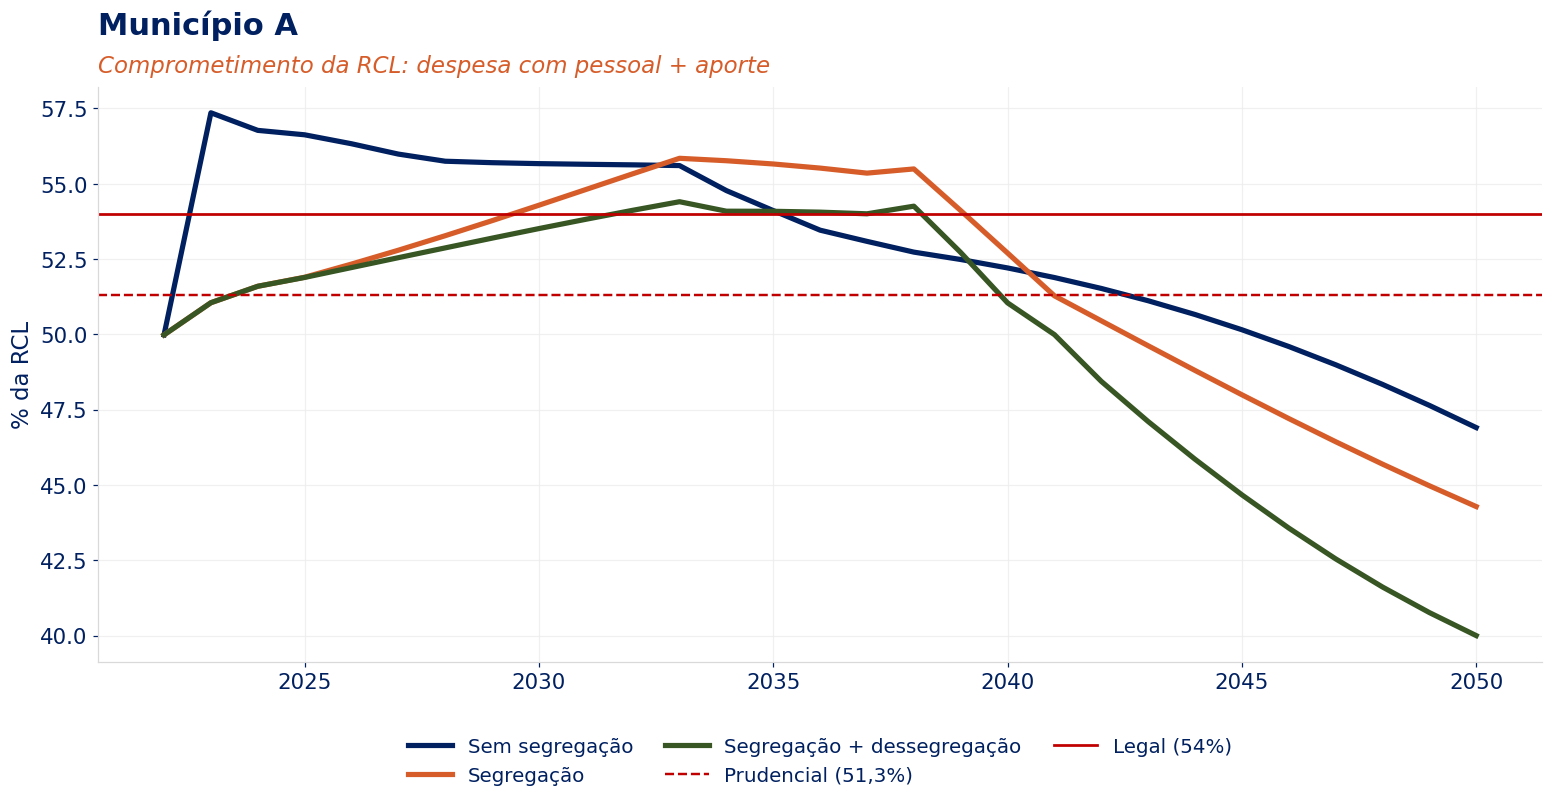

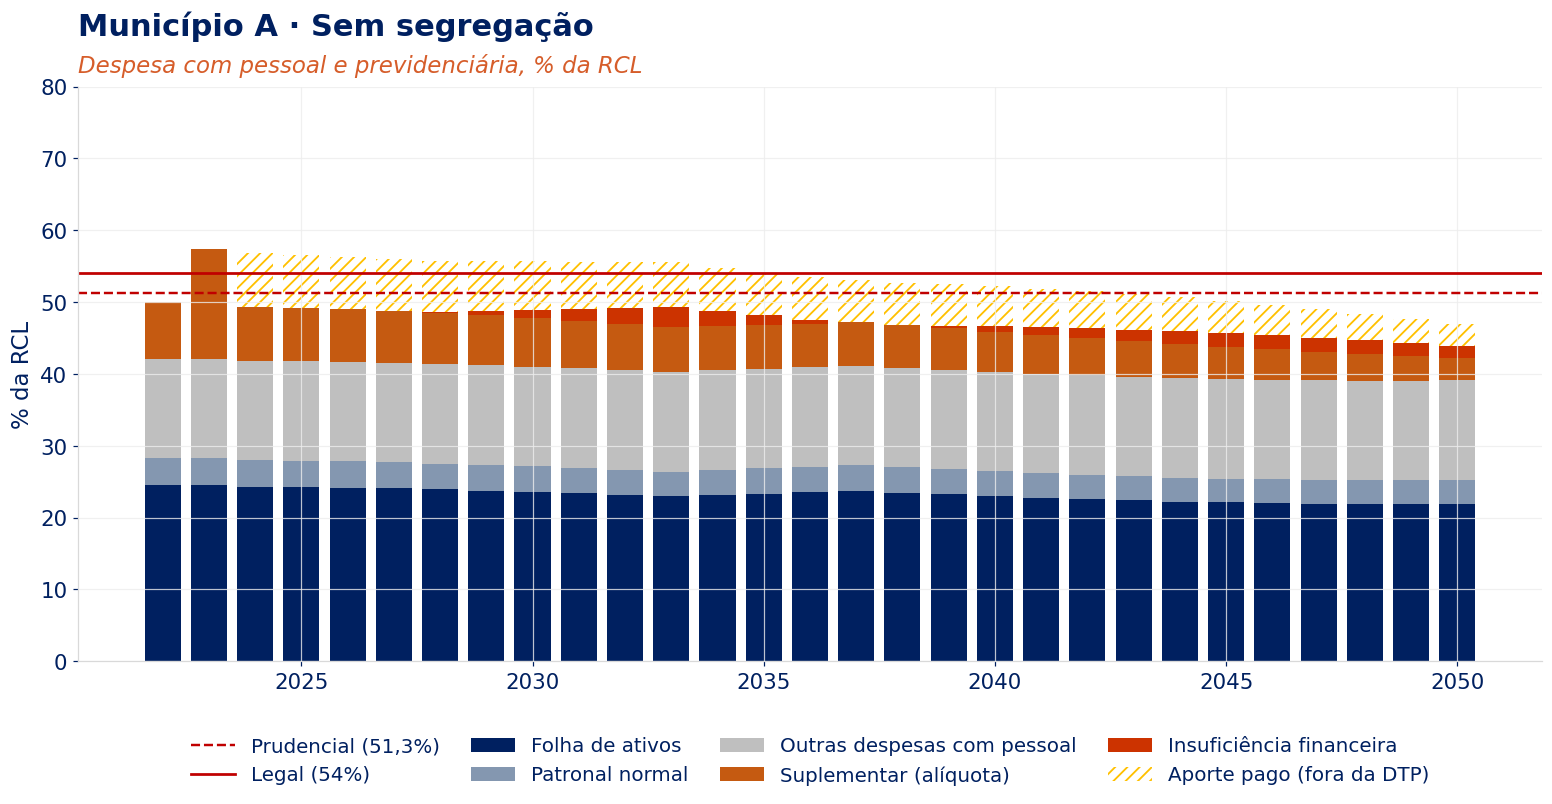

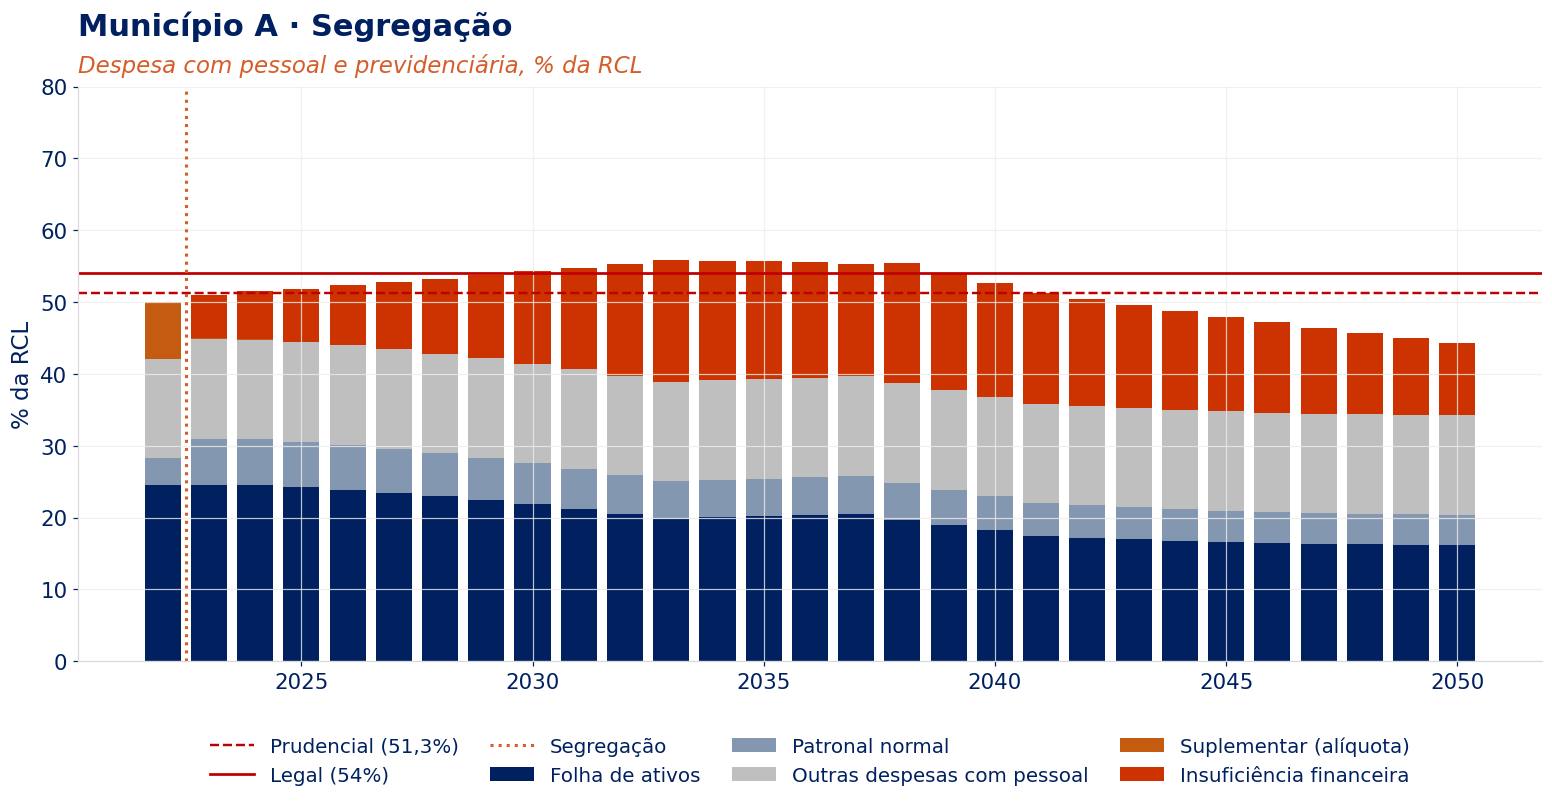

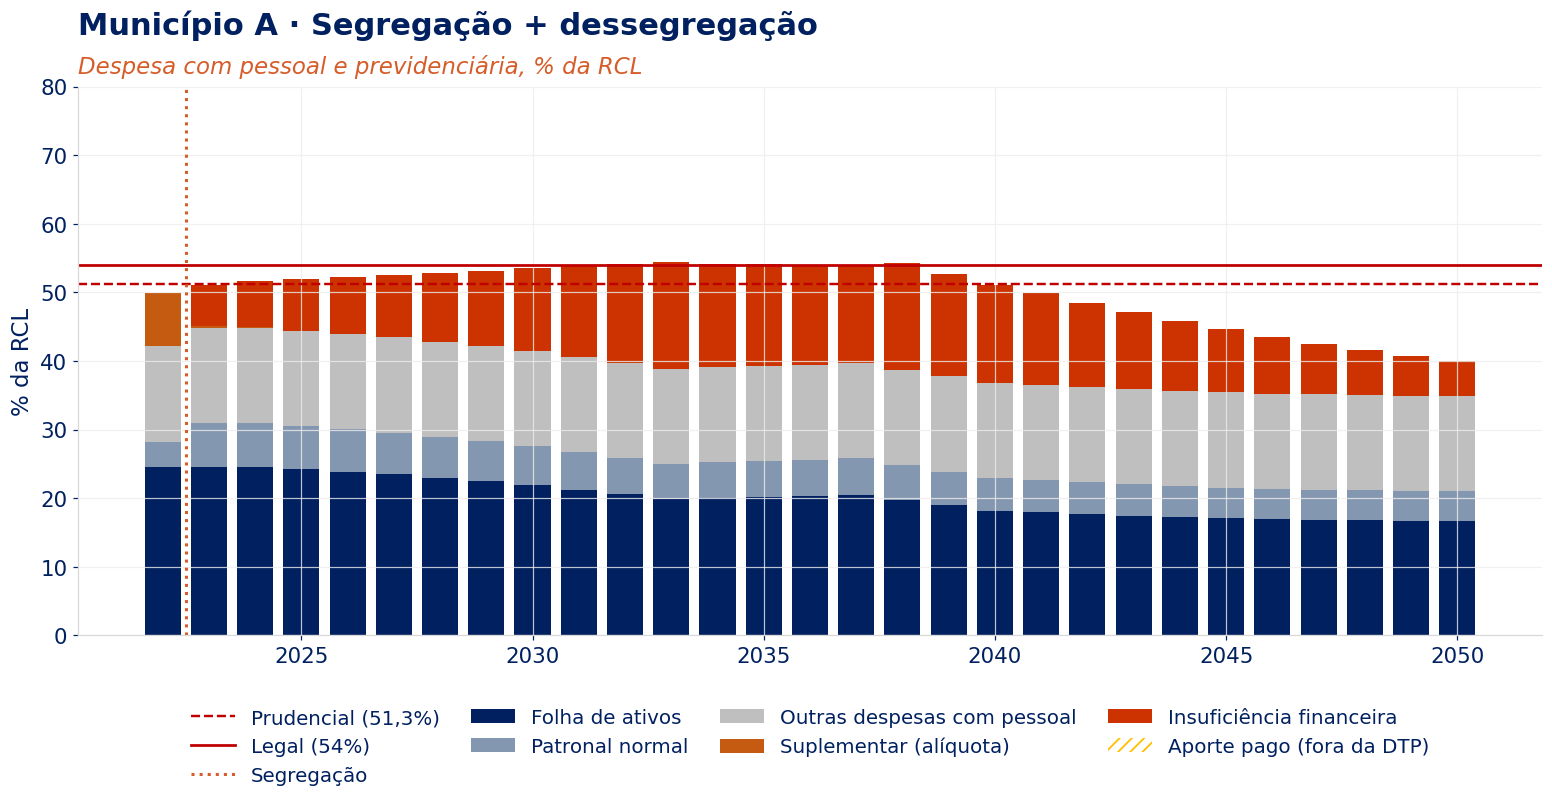

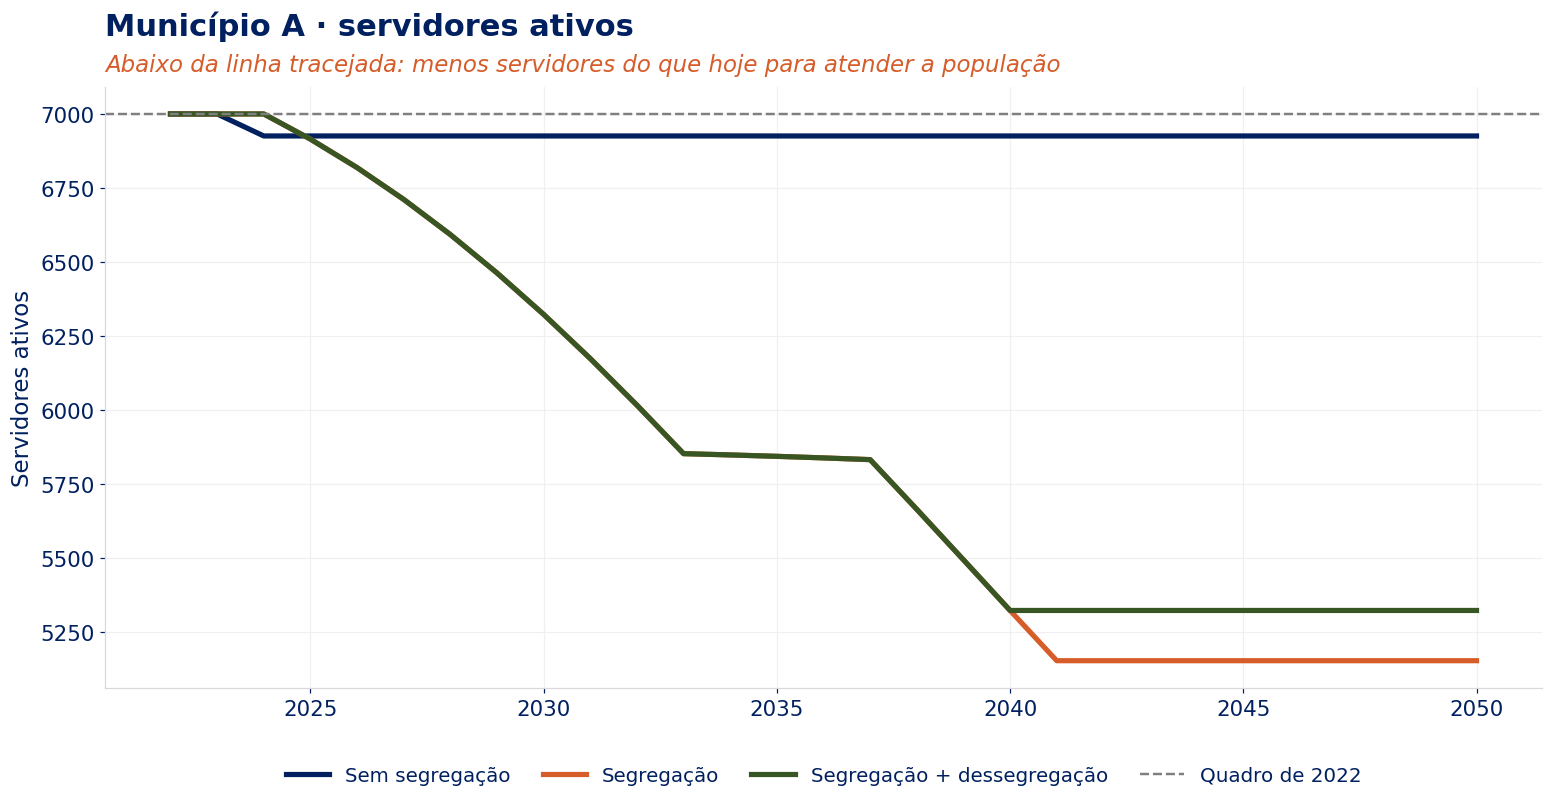

DTP (% RCL)  comprometimento (% RCL)  \
cenário                    ano                                          
Sem segregação             2027       48.800                   56.000   
                           2030       48.800                   55.700   
                           2040       46.600                   52.200   
                           2050       43.800                   46.900   
Segregação                 2027       52.800                   52.800   
                           2030       54.300                   54.300   
                           2040       52.700                   52.700   
                           2050       44.300                   44.300   
Segregação + dessegregação 2027       52.500                   52.500   
                           2030       53.500                   53.500   
                           2040       51.000                   51.000   
                           2050       40.000                   40.000   

                                 insuficiência (% RCL)  aporte pago (% RCL)  \
cenário                    ano                                                
Sem segregação             2027                  0.000                7.200   
                           2030                  1.000                6.800   
                           2040                  0.700                5.600   
                           2050                  1.600                3.100   
Segregação                 2027                  9.400                0.000   
                           2030                 12.900                0.000   
                           2040                 15.900                0.000   
                           2050                 10.000                0.000   
Segregação + dessegregação 2027                  9.100                0.000   
                           2030                 12.100                0.000   
                           2040                 14.200                0.000   
                           2050                  5.100                0.000   

                                 aporte não pago (% RCL)  servidores  \
cenário                    ano                                         
Sem segregação             2027                    0.000        6926   
                           2030                    0.000        6926   
                           2040                    0.000        6926   
                           2050                    0.000        6926   
Segregação                 2027                    0.000        6711   
                           2030                    0.000        6323   
                           2040                    0.000        5323   
                           2050                    0.000        5153   
Segregação + dessegregação 2027                    0.000        6711   
                           2030                    0.000        6323   
                           2040                    0.000        5323   
                           2050                    0.000        5323   

                                 nomeados pela troca (acum.)  \
cenário                    ano                                 
Sem segregação             2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0   
Segregação                 2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0   
Segregação + dessegregação 2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0  

,marco,ano
0,DTP acima do alerta,2022
1,DTP acima do prudencial (reposição restrita em...,2023
2,Custeio passa (total ou parcialmente) a aporte,2024
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,2028
5,DTP acima do limite legal,2023
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2022
8,Primeiro superávit do FC,2057
9,Primeira dessegregação,—



=== Município B


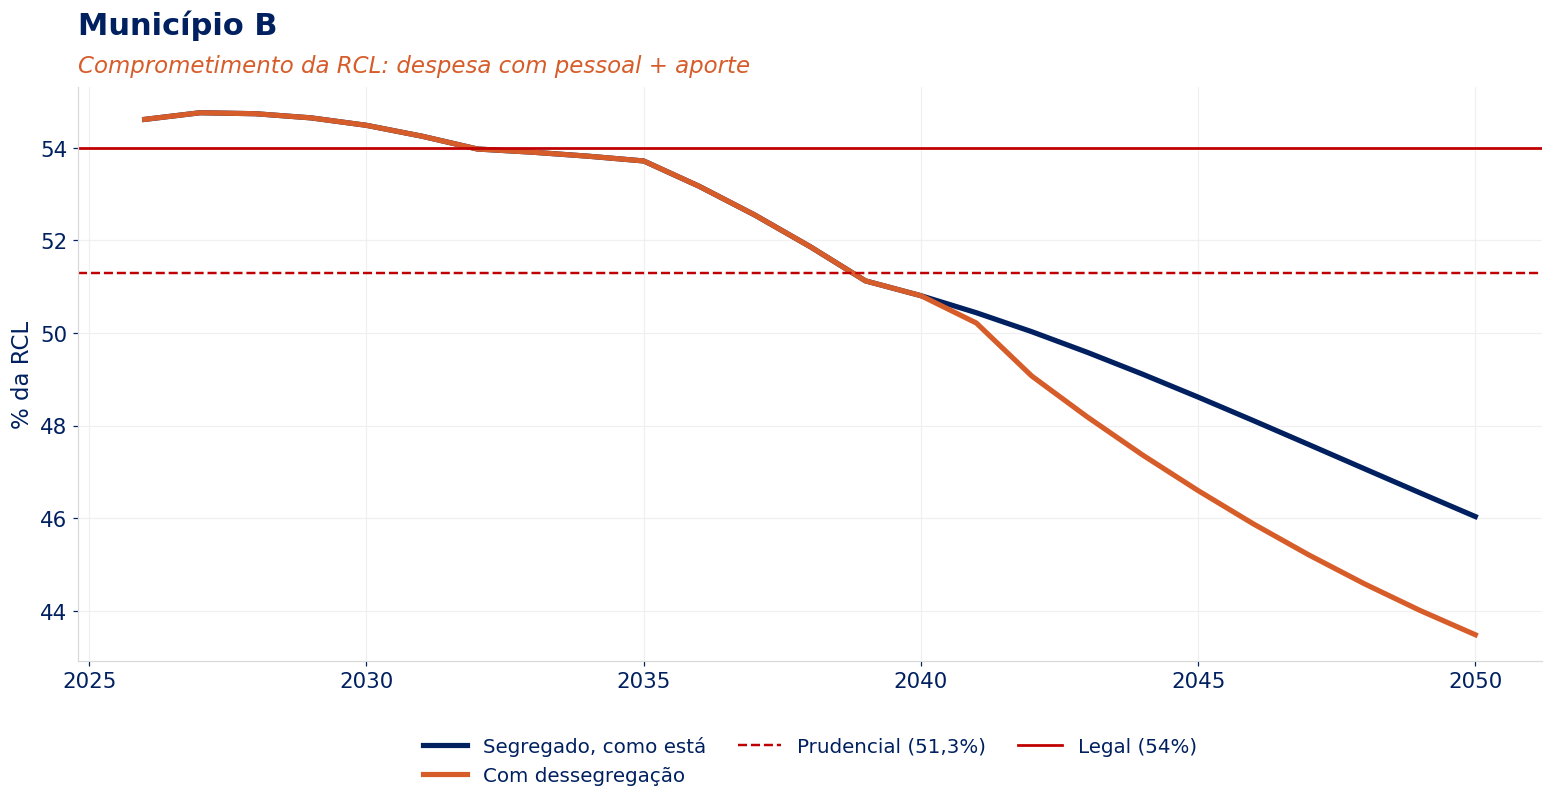

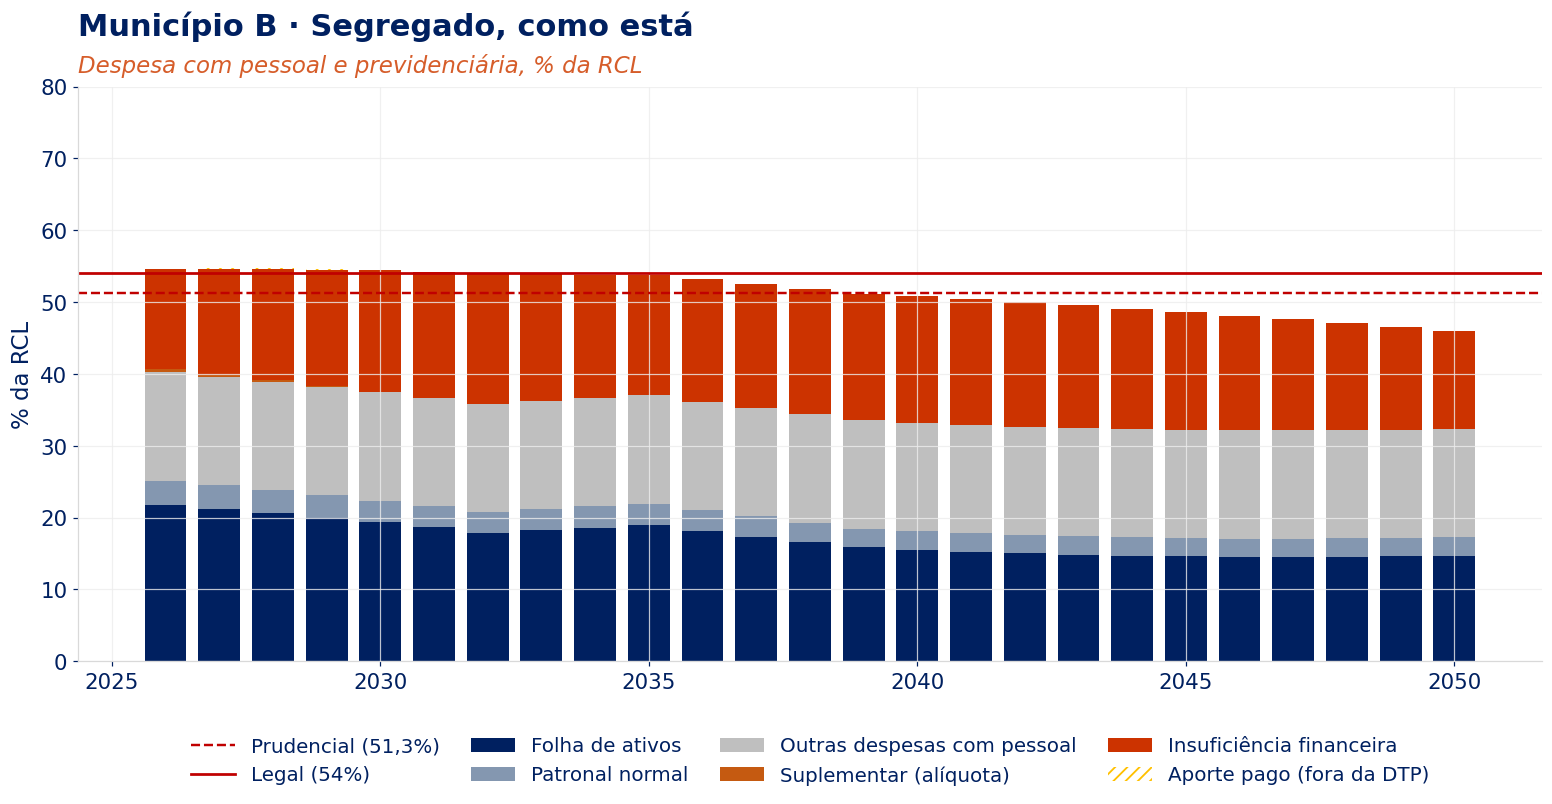

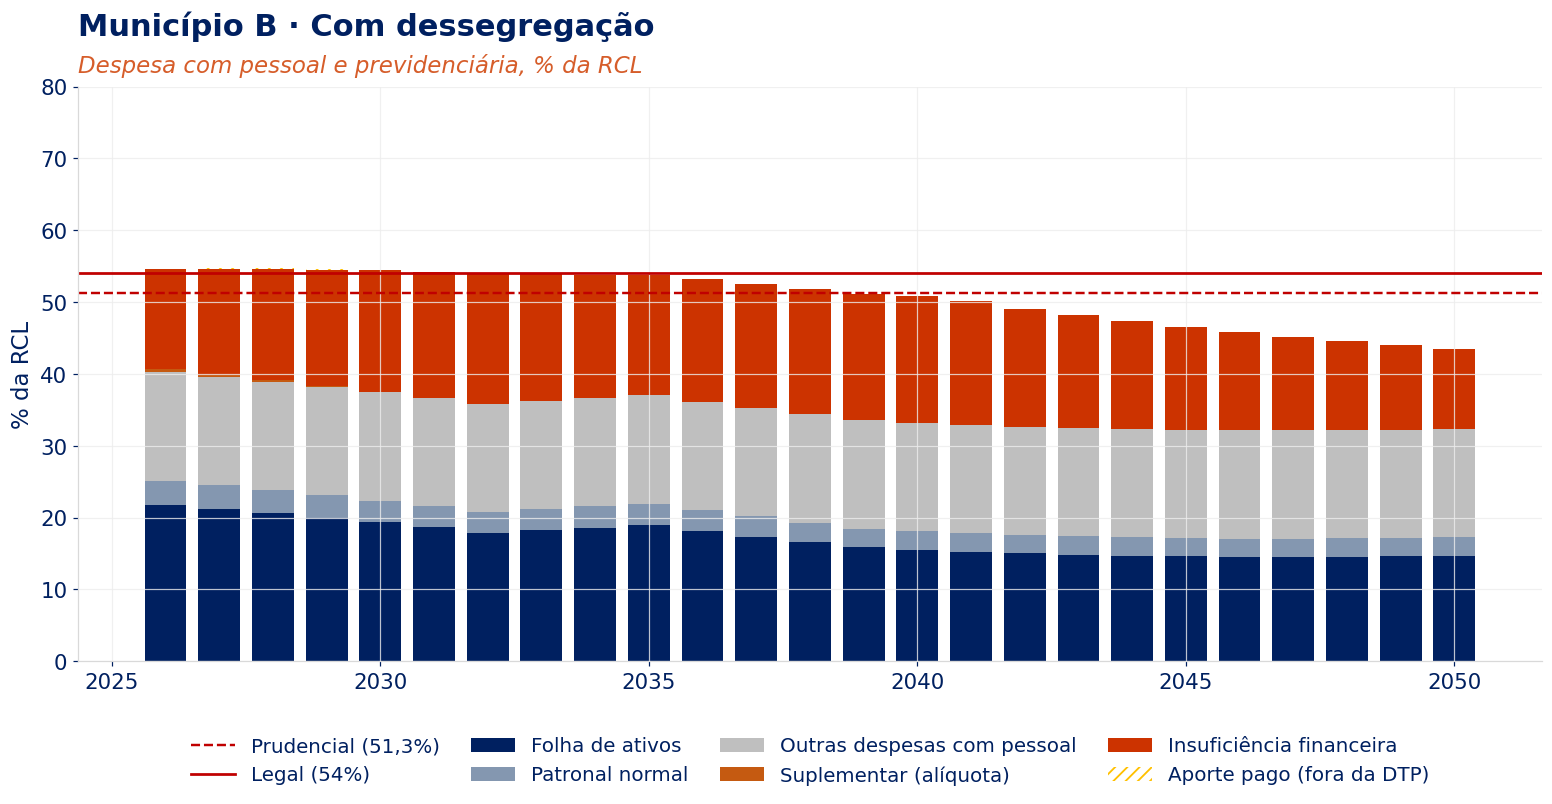

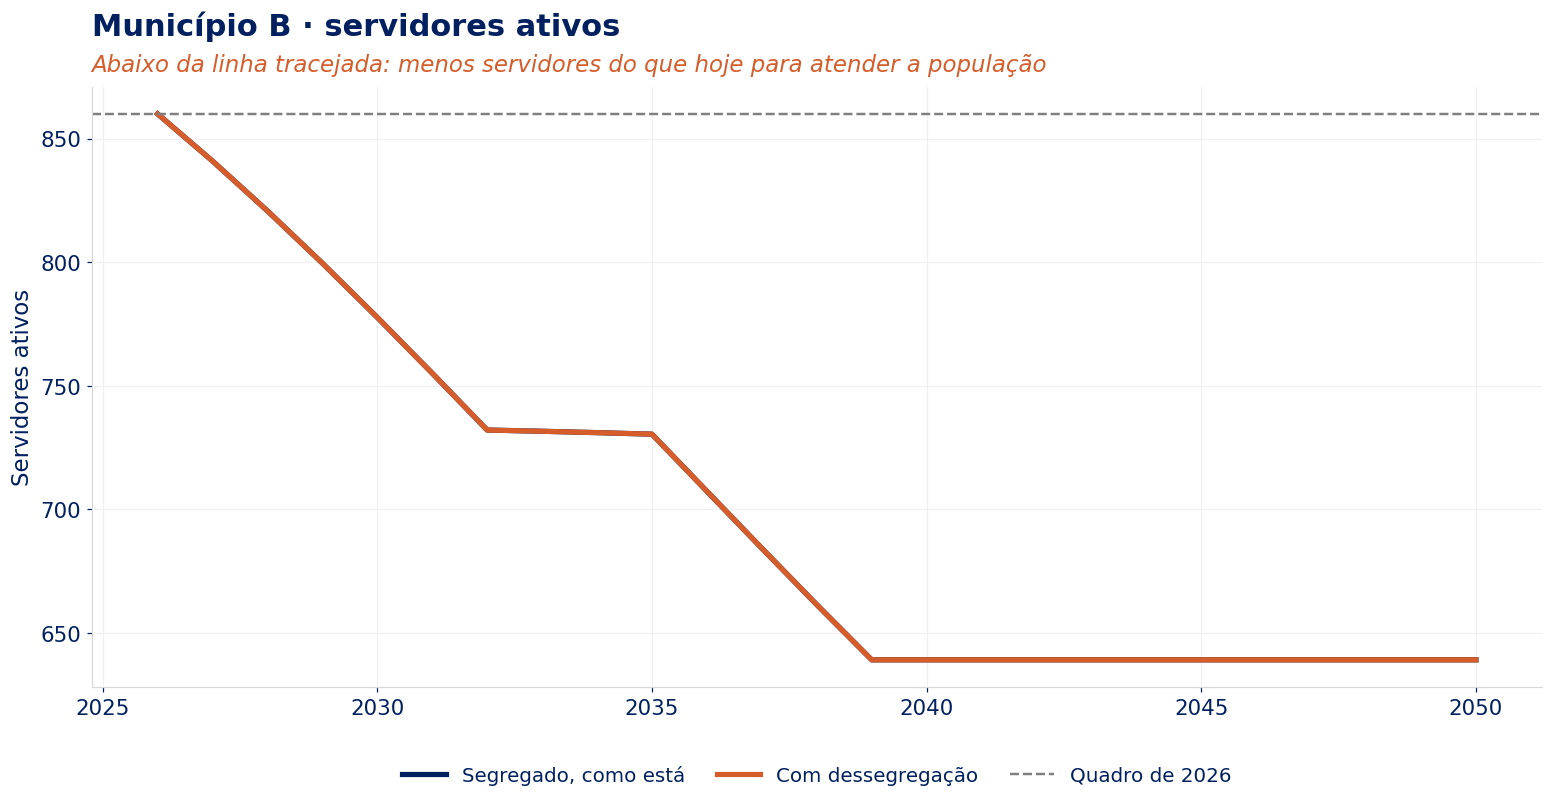

DTP (% RCL)  comprometimento (% RCL)  \
cenário              ano                                          
Segregado, como está 2027       54.500                   54.800   
                     2030       54.400                   54.500   
                     2040       50.800                   50.800   
                     2050       46.000                   46.000   
Com dessegregação    2027       54.500                   54.800   
                     2030       54.400                   54.500   
                     2040       50.800                   50.800   
                     2050       43.500                   43.500   

                           insuficiência (% RCL)  aporte pago (% RCL)  \
cenário              ano                                                
Segregado, como está 2027                 14.700                0.200   
                     2030                 16.900                0.100   
                     2040                 17.600                0.000   
                     2050                 13.700                0.000   
Com dessegregação    2027                 14.700                0.200   
                     2030                 16.900                0.100   
                     2040                 17.600                0.000   
                     2050                 11.100                0.000   

                           aporte não pago (% RCL)  servidores  \
cenário              ano                                         
Segregado, como está 2027                    0.000         841   
                     2030                    0.000         778   
                     2040                    0.000         639   
                     2050                    0.000         639   
Com dessegregação    2027                    0.000         841   
                     2030                    0.000         778   
                     2040                    0.000         639   
                     2050                    0.000         639   

                           nomeados pela troca (acum.)  \
cenário              ano                                 
Segregado, como está 2027                            0   
                     2030                            0   
                     2040                            0   
                     2050                            0   
Com dessegregação    2027                            0   
                     2030                            0   
                     2040                            0   
                     2050                            0   

                           nomeados com a economia (acum.)  \
cenário              ano                                     
Segregado, como está 2027                                0   
                     2030                                0   
                     2040                                0   
                     2050                                0   
Com dessegregação    2027                                0   
                     2030                                0   
                     2040                                0   
                     2050                                0   

                           custo de 1 novo servidor (× salário)  \
cenário              ano                                          
Segregado, como está 2027                                 1.190   
                     2030                                 1.180   
                     2040                                 1.180   
                     2050                                 1.180   
Com dessegregação    2027                                 1.190   
                     2030                                 1.180   
                     2040                                 1.180   
                     2050                                 1.180   

                          reposição restrita?  
cenário              ano                   

,marco,ano
0,DTP acima do alerta,2026
1,DTP acima do prudencial (reposição restrita em...,2026
2,Custeio passa (total ou parcialmente) a aporte,2027
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,—
5,DTP acima do limite legal,2026
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2026
8,Primeiro superávit do FC,2031
9,Primeira dessegregação,—



=== Município C


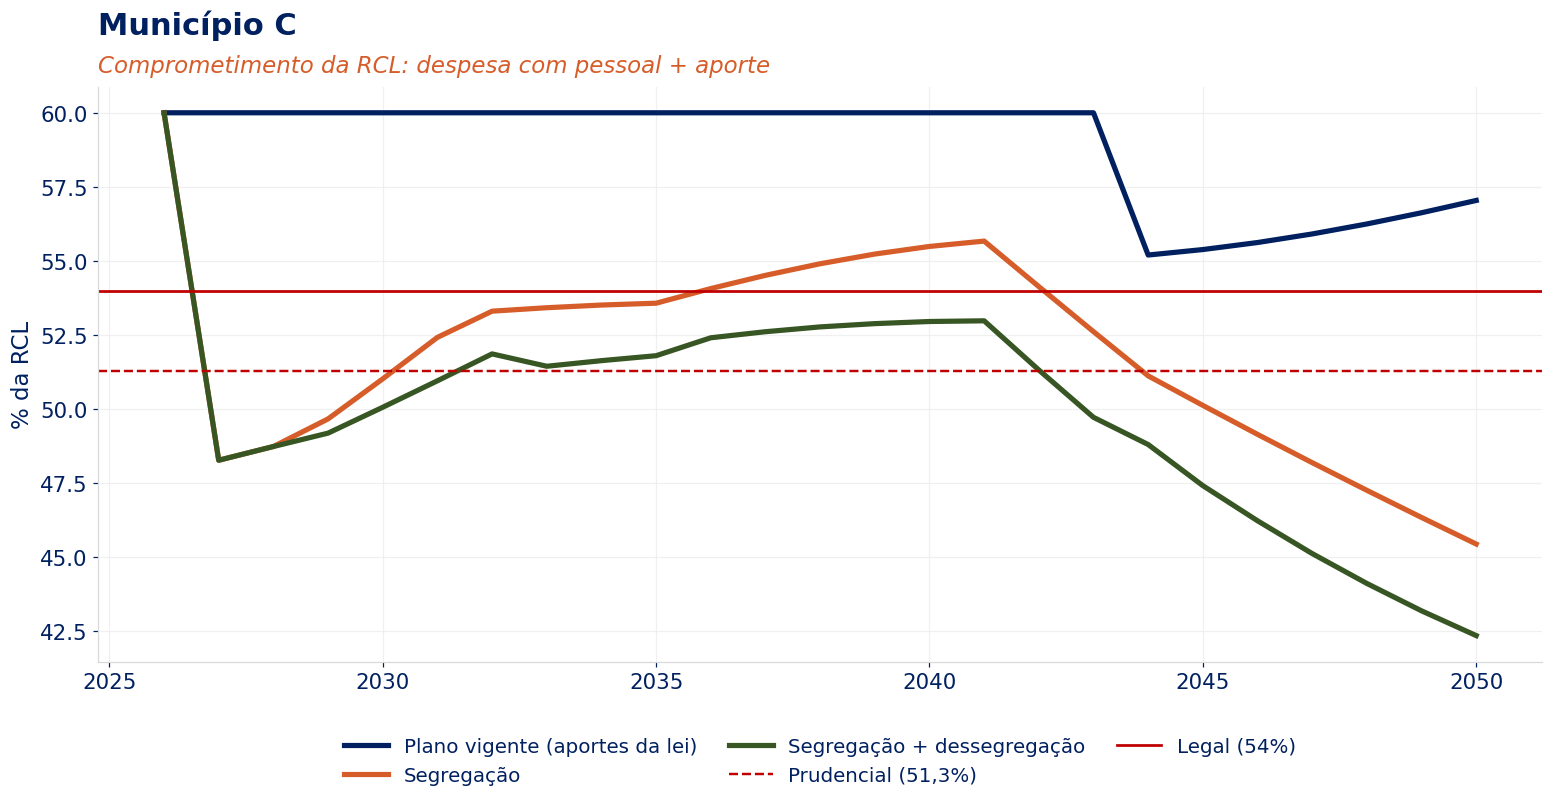

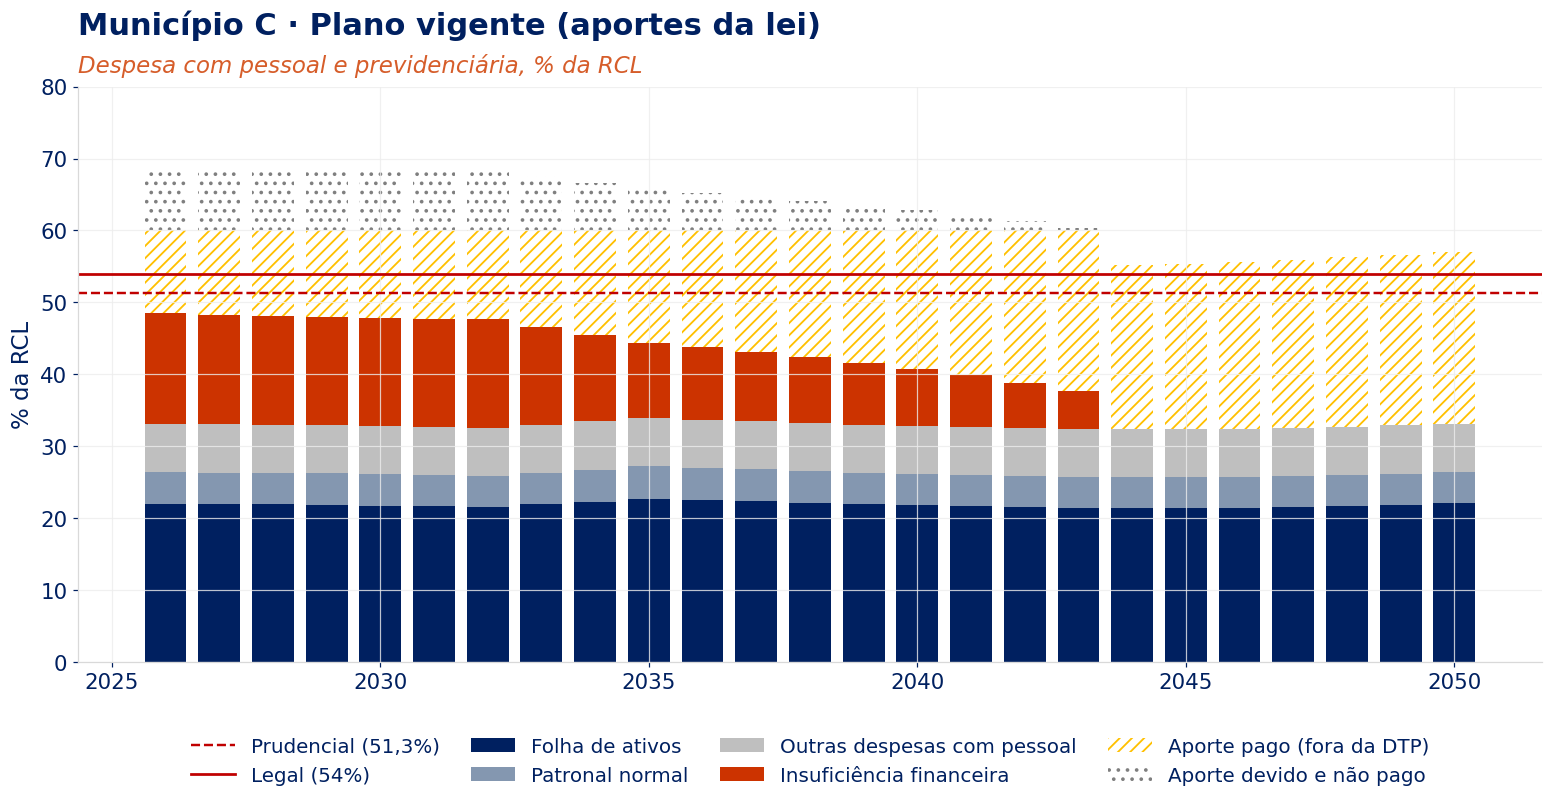

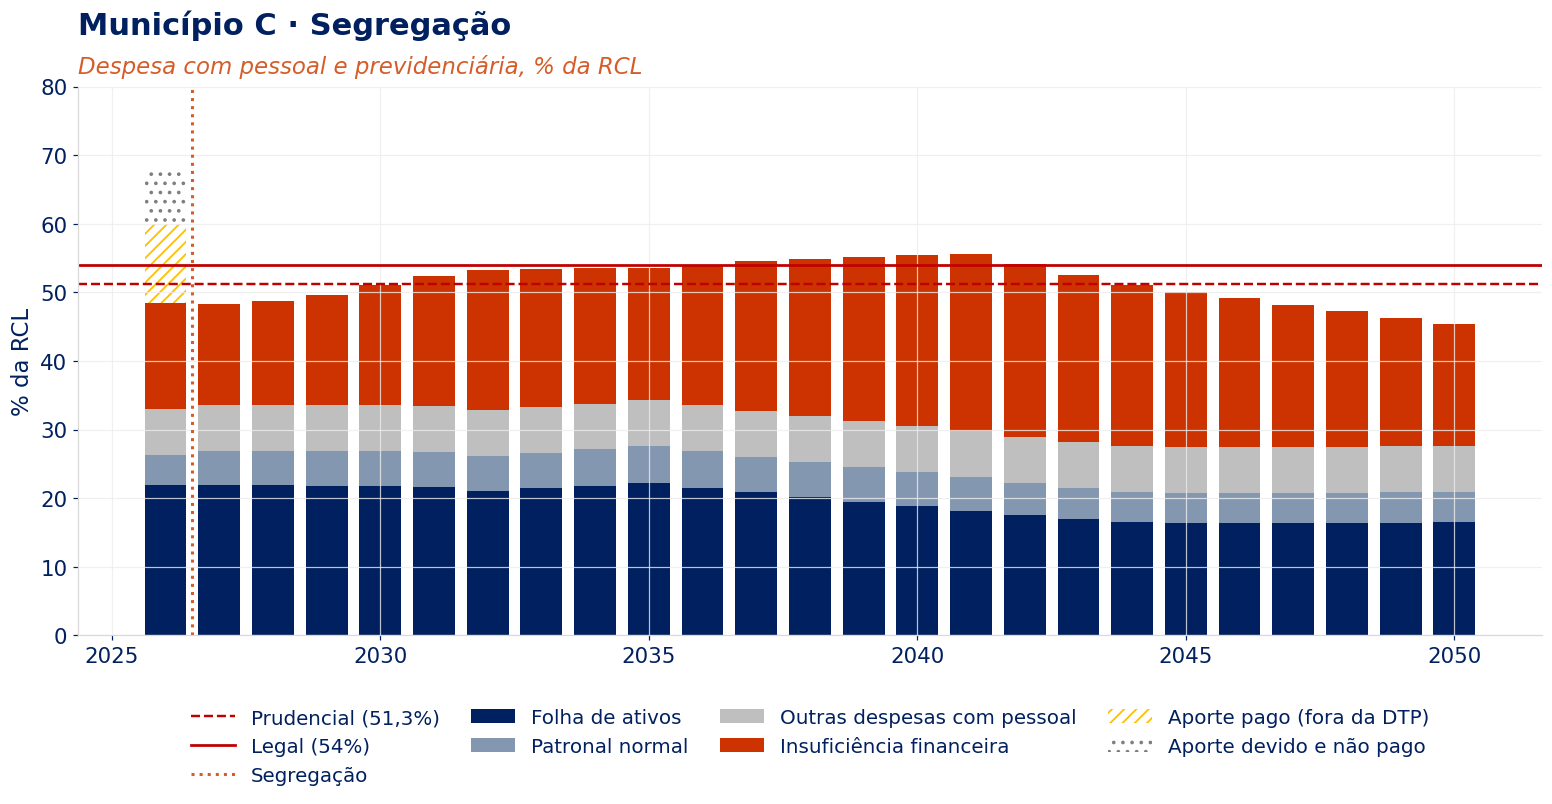

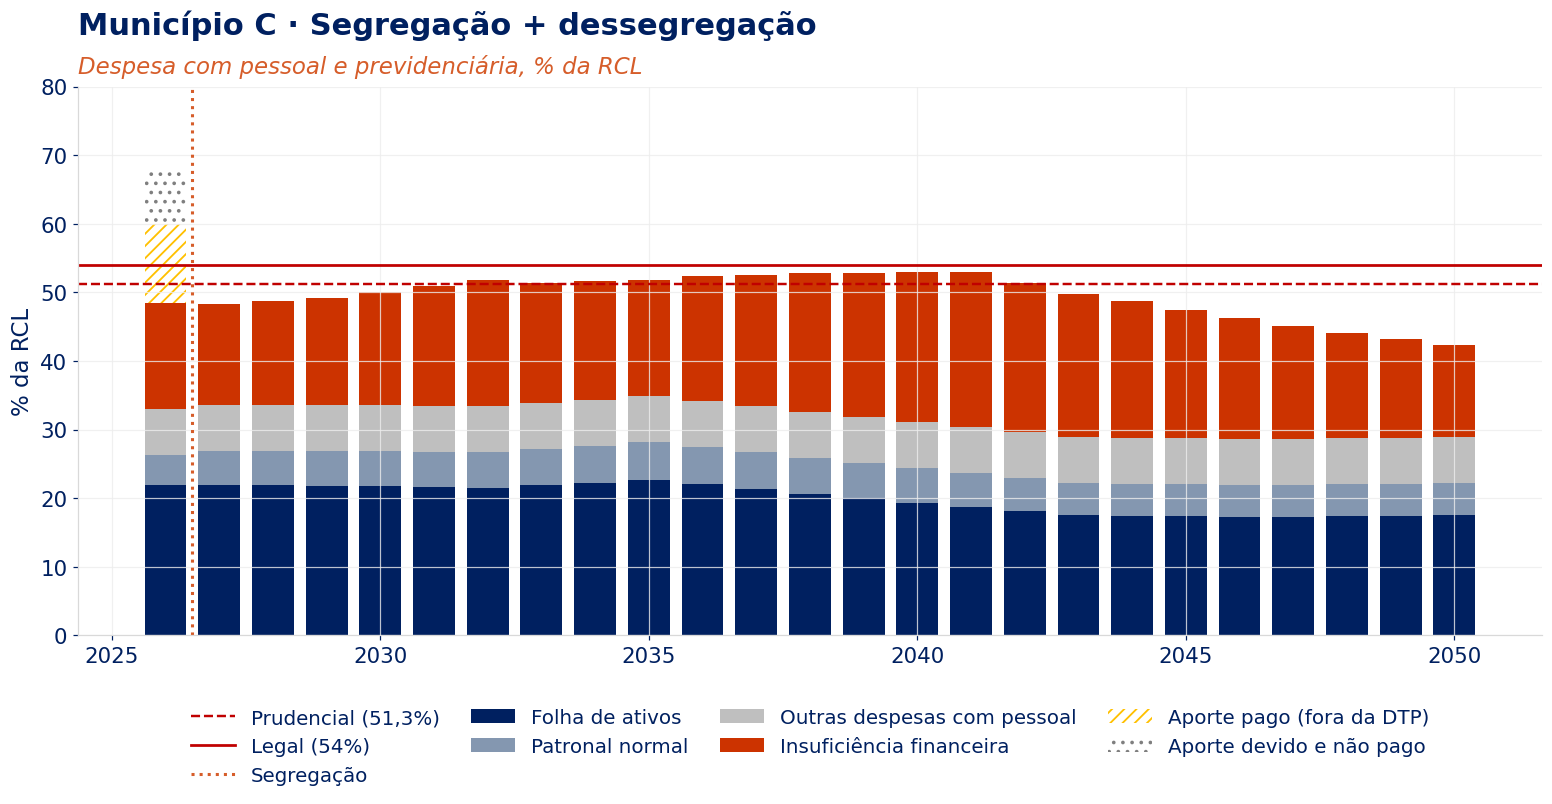

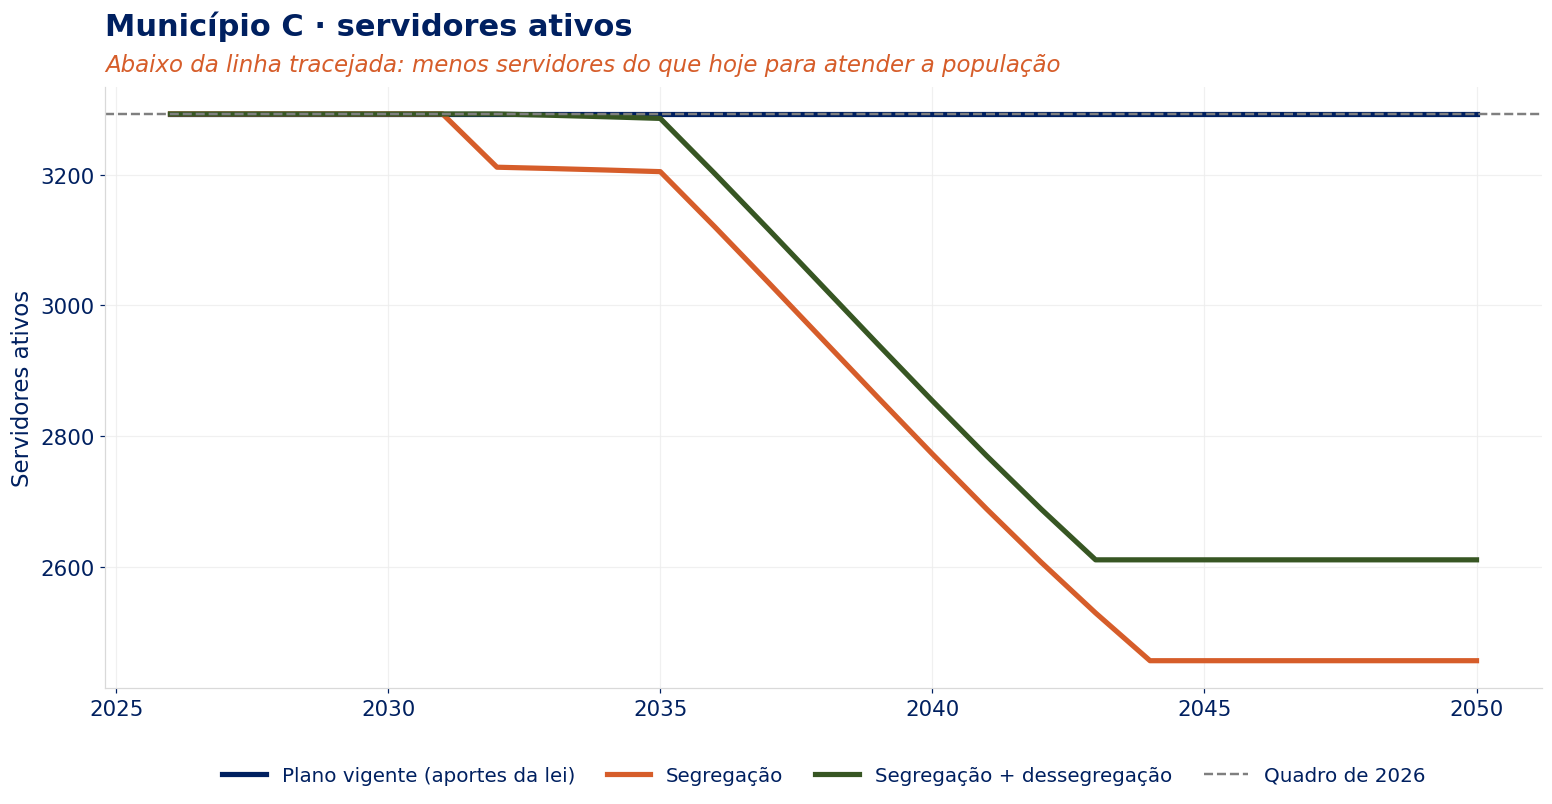

DTP (% RCL)  comprometimento (% RCL)  \
cenário                        ano                                          
Plano vigente (aportes da lei) 2027       48.300                   60.000   
                               2030       47.800                   60.000   
                               2040       40.800                   60.000   
                               2050       33.100                   57.000   
Segregação                     2027       48.300                   48.300   
                               2030       51.000                   51.000   
                               2040       55.500                   55.500   
                               2050       45.400                   45.400   
Segregação + dessegregação     2027       48.300                   48.300   
                               2030       50.100                   50.100   
                               2040       53.000                   53.000   
                               2050       42.400                   42.400   

                                     insuficiência (% RCL)  \
cenário                        ano                           
Plano vigente (aportes da lei) 2027                 15.200   
                               2030                 15.100   
                               2040                  8.000   
                               2050                  0.000   
Segregação                     2027                 14.700   
                               2030                 17.500   
                               2040                 25.000   
                               2050                 17.800   
Segregação + dessegregação     2027                 14.700   
                               2030                 16.500   
                               2040                 21.800   
                               2050                 13.400   

                                     aporte pago (% RCL)  \
cenário                        ano                         
Plano vigente (aportes da lei) 2027               11.700   
                               2030               12.200   
                               2040               19.200   
                               2050               24.000   
Segregação                     2027                0.000   
                               2030                0.000   
                               2040                0.000   
                               2050                0.000   
Segregação + dessegregação     2027                0.000   
                               2030                0.000   
                               2040                0.000   
                               2050                0.000   

                                     aporte não pago (% RCL)  servidores  \
cenário                        ano                                         
Plano vigente (aportes da lei) 2027                    8.300        3293   
                               2030                    8.300        3293   
                               2040                    2.900        3293   
                               2050                    0.000        3293   
Segregação                     2027                    0.000        3293   
                               2030                    0.000        3293   
                               2040                    0.000        2773   
                               2050                    0.000        2457   
Segregação + dessegregação     2027                    0.000        3293   
                               2030                    0.000        3293   
                               2040                    0.000        2854   
                               2050                    0.000        2611   

                                     nomeados pela troca (acum.)  \
cenário                        ano                                 
Plano vigente (aportes da lei) 2027            

,marco,ano
0,DTP acima do alerta,—
1,DTP acima do prudencial (reposição restrita em...,—
2,Custeio passa (total ou parcialmente) a aporte,2026
3,Aporte devido não é pago integralmente,2026
4,Insuficiência no FC enquanto há aporte em carê...,2026
5,DTP acima do limite legal,—
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2026
8,Primeiro superávit do FC,2043
9,Primeira dessegregação,—



=== Município D


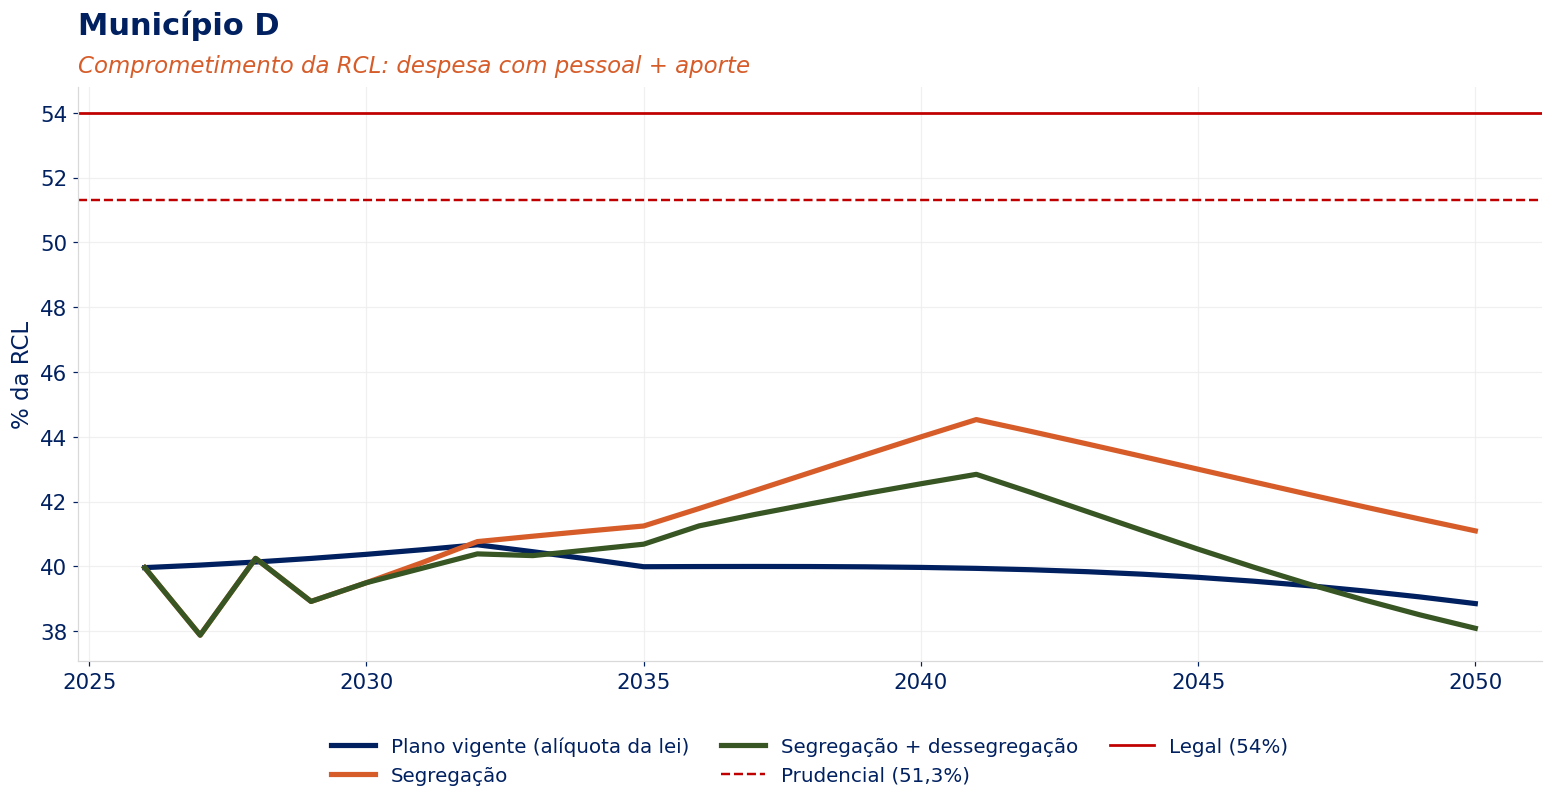

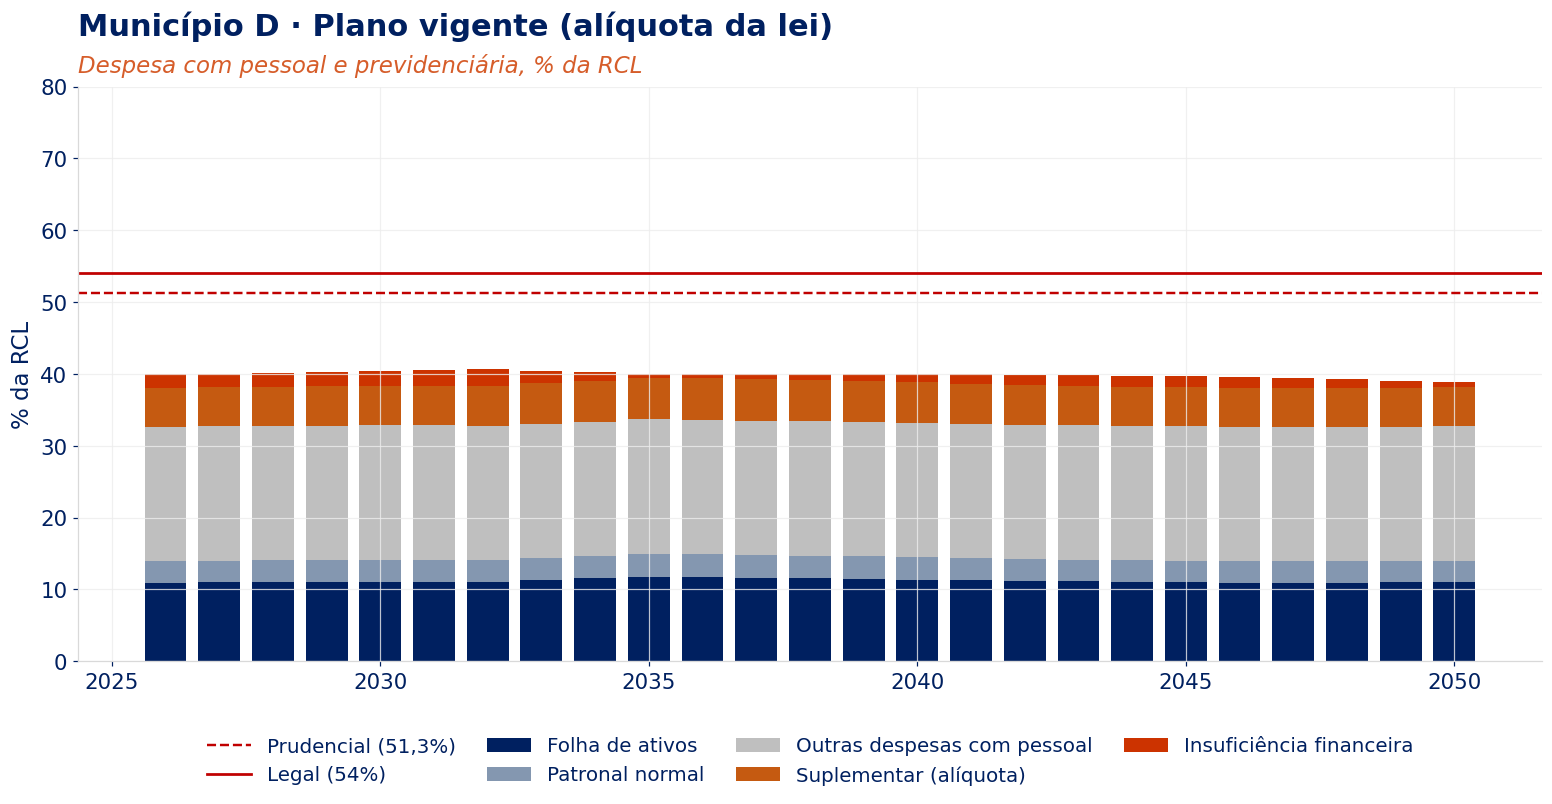

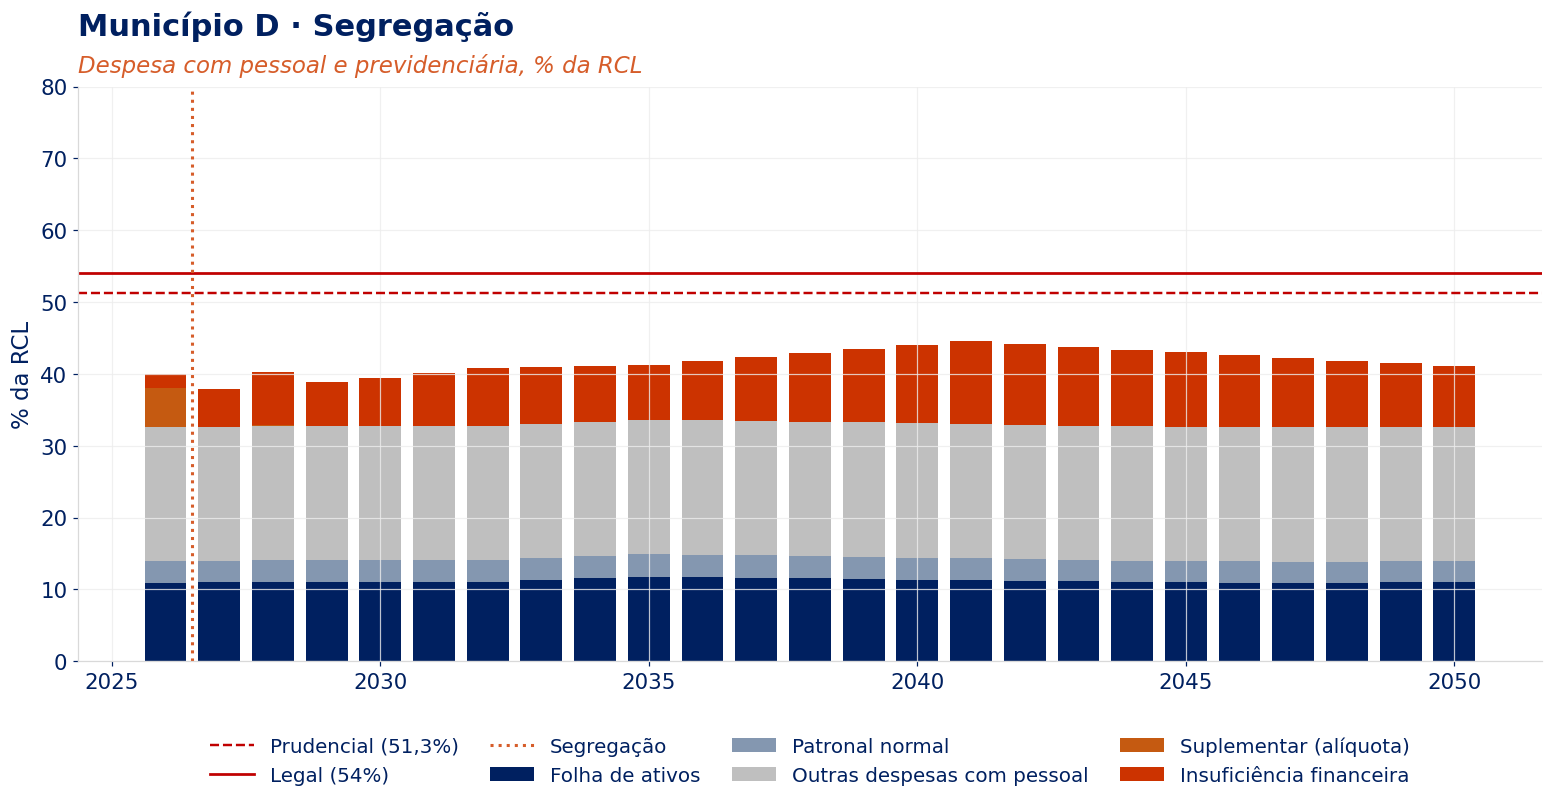

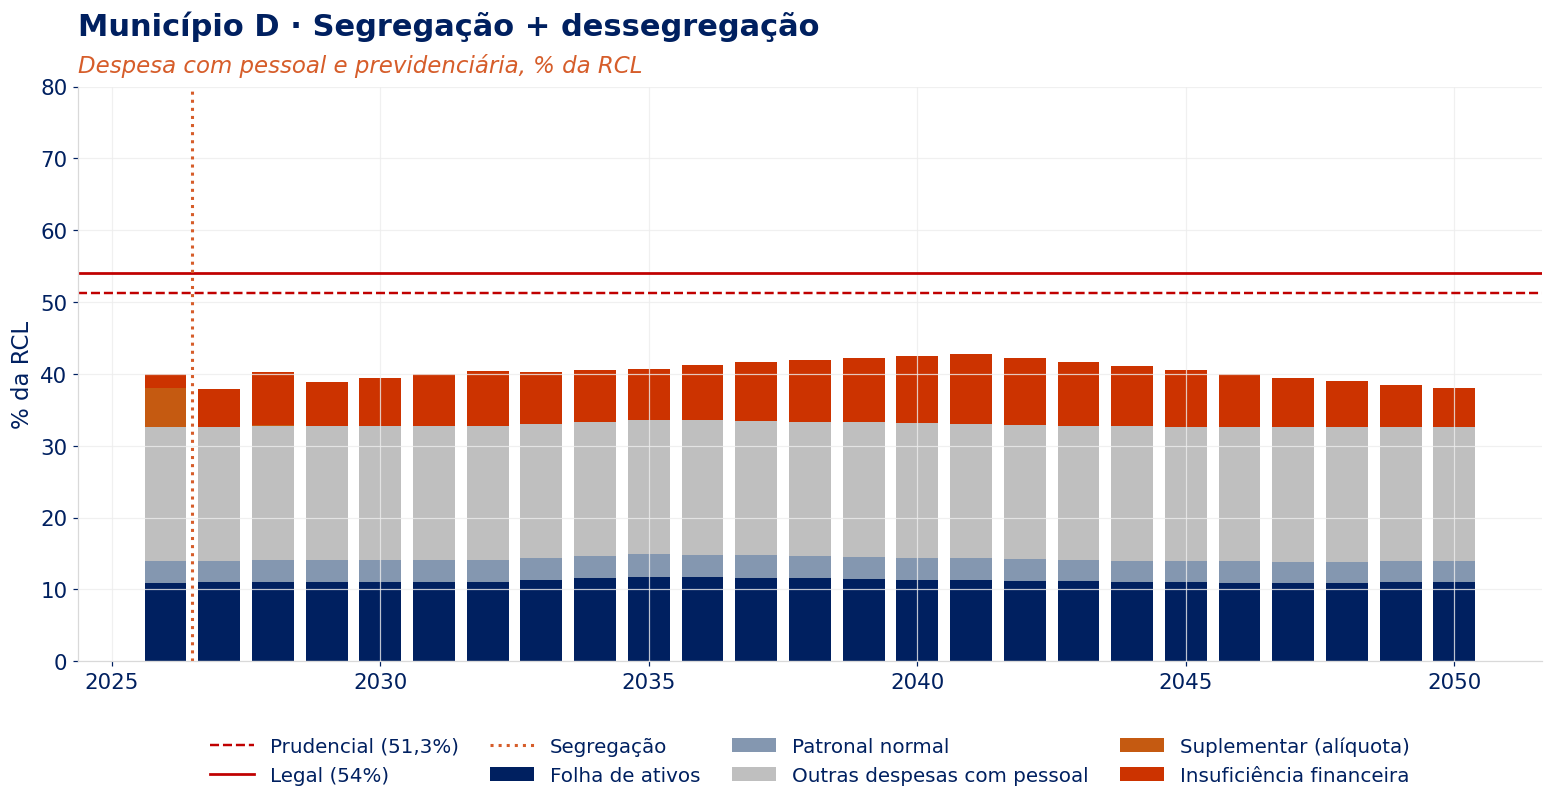

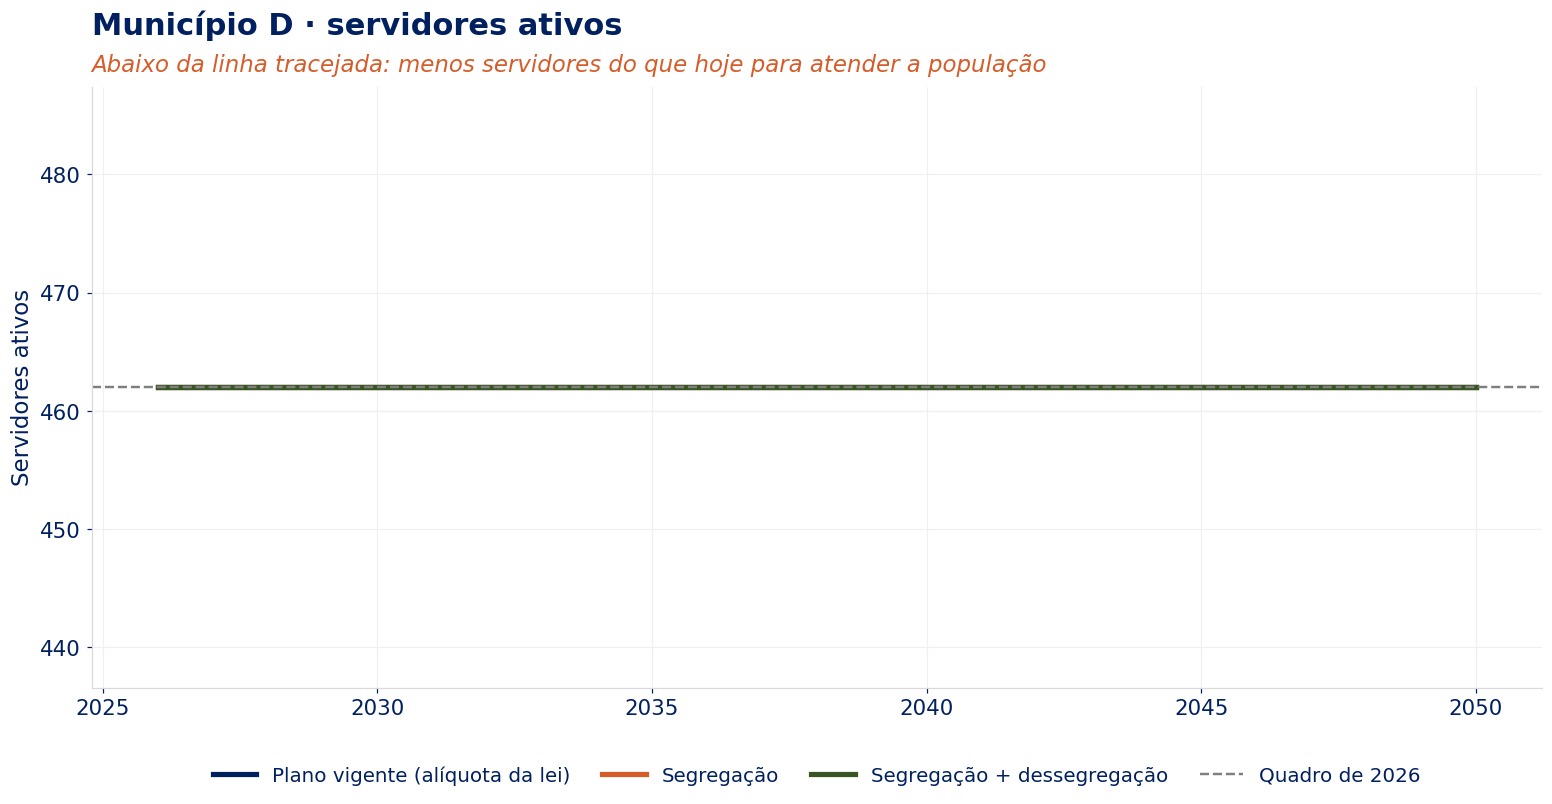

DTP (% RCL)  comprometimento (% RCL)  \
cenário                         ano                                          
Plano vigente (alíquota da lei) 2027       40.000                   40.000   
                                2030       40.400                   40.400   
                                2040       40.000                   40.000   
                                2050       38.900                   38.900   
Segregação                      2027       37.900                   37.900   
                                2030       39.500                   39.500   
                                2040       44.000                   44.000   
                                2050       41.100                   41.100   
Segregação + dessegregação      2027       37.900                   37.900   
                                2030       39.500                   39.500   
                                2040       42.600                   42.600   
                                2050       38.100                   38.100   

                                      insuficiência (% RCL)  \
cenário                         ano                           
Plano vigente (alíquota da lei) 2027                  1.900   
                                2030                  2.000   
                                2040                  1.100   
                                2050                  0.700   
Segregação                      2027                  5.200   
                                2030                  6.700   
                                2040                 10.900   
                                2050                  8.400   
Segregação + dessegregação      2027                  5.200   
                                2030                  6.700   
                                2040                  9.400   
                                2050                  5.400   

                                      aporte pago (% RCL)  \
cenário                         ano                         
Plano vigente (alíquota da lei) 2027                0.000   
                                2030                0.000   
                                2040                0.000   
                                2050                0.000   
Segregação                      2027                0.000   
                                2030                0.000   
                                2040                0.000   
                                2050                0.000   
Segregação + dessegregação      2027                0.000   
                                2030                0.000   
                                2040                0.000   
                                2050                0.000   

                                      aporte não pago (% RCL)  servidores  \
cenário                         ano                                         
Plano vigente (alíquota da lei) 2027                    0.000         462   
                                2030                    0.000         462   
                                2040                    0.000         462   
                                2050                    0.000         462   
Segregação                      2027                    0.000         462   
                                2030                    0.000         462   
                                2040                    0.000         462   
                                2050                    0.000         462   
Segregação + dessegregação      2027                    0.000         462   
                                2030                    0.000         462   
                                2040                    0.000         462   
                                2050                    0.000         462   

                                      nomeados pela troca (acum.)  \
cenário                         ano                        

,marco,ano
0,DTP acima do alerta,—
1,DTP acima do prudencial (reposição restrita em...,—
2,Custeio passa (total ou parcialmente) a aporte,—
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,—
5,DTP acima do limite legal,—
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2026
8,Primeiro superávit do FC,2062
9,Primeira dessegregação,—



=== Município E


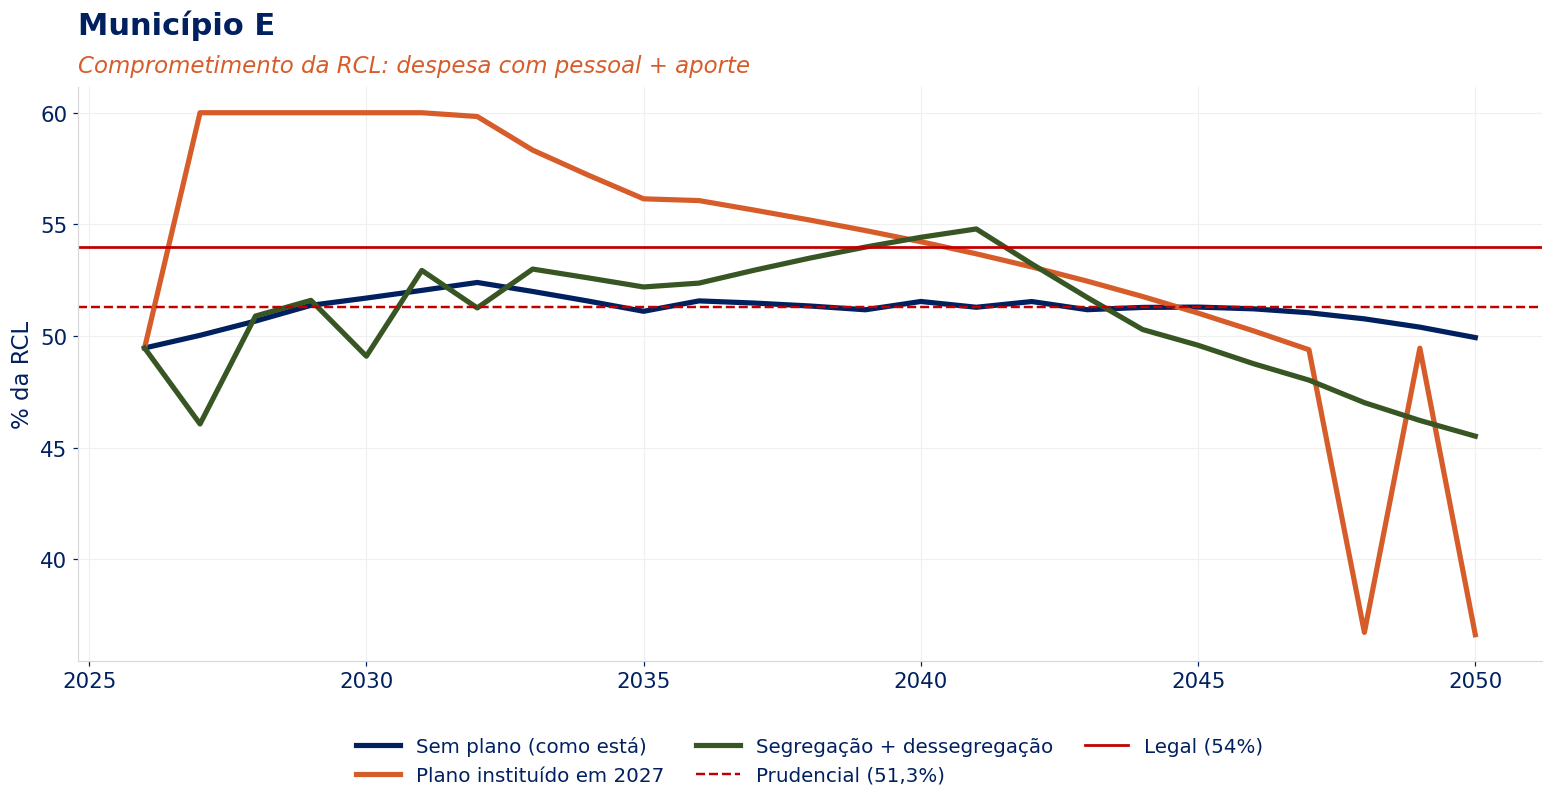

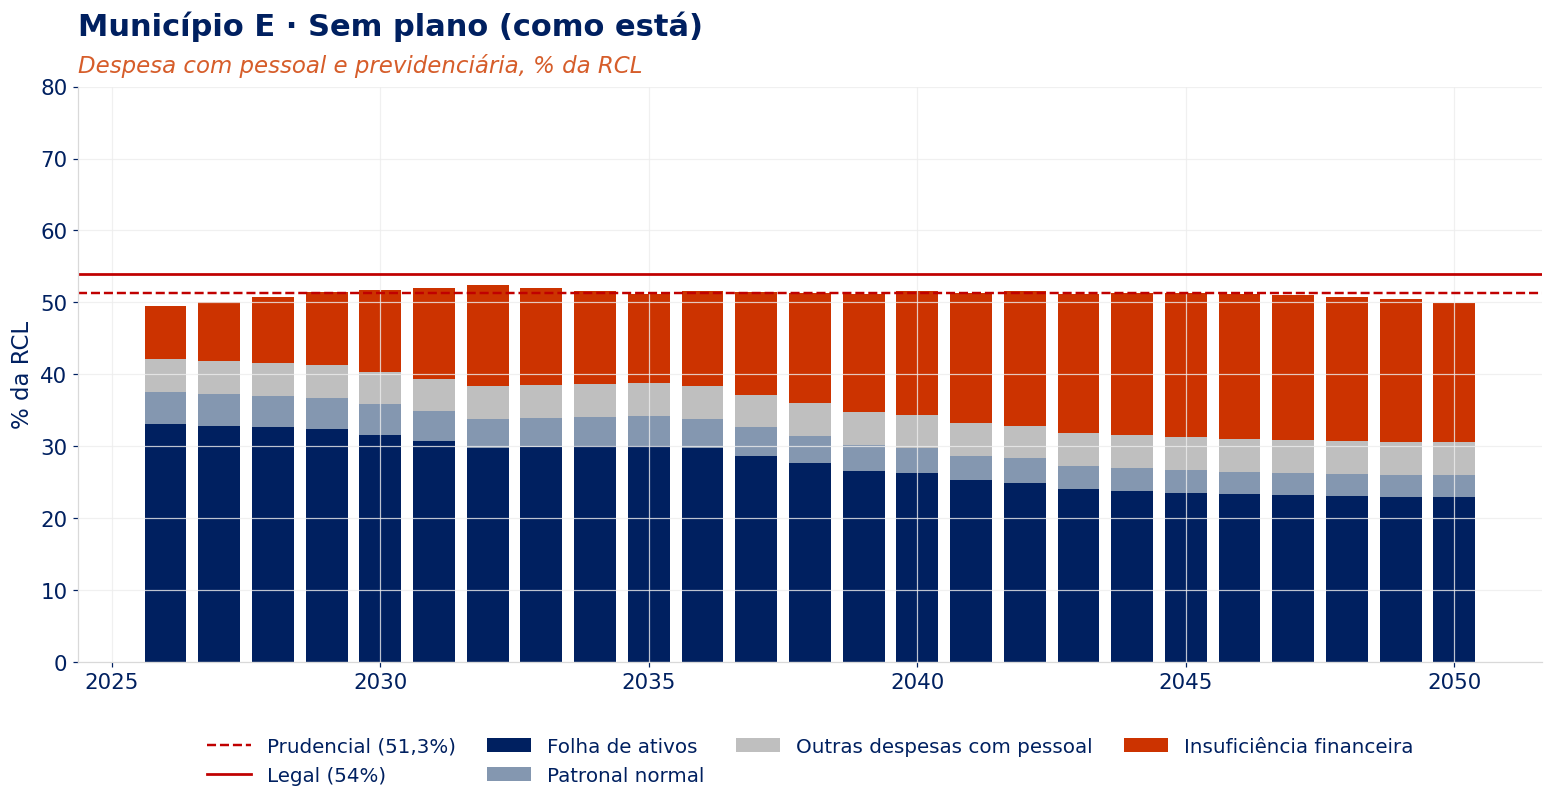

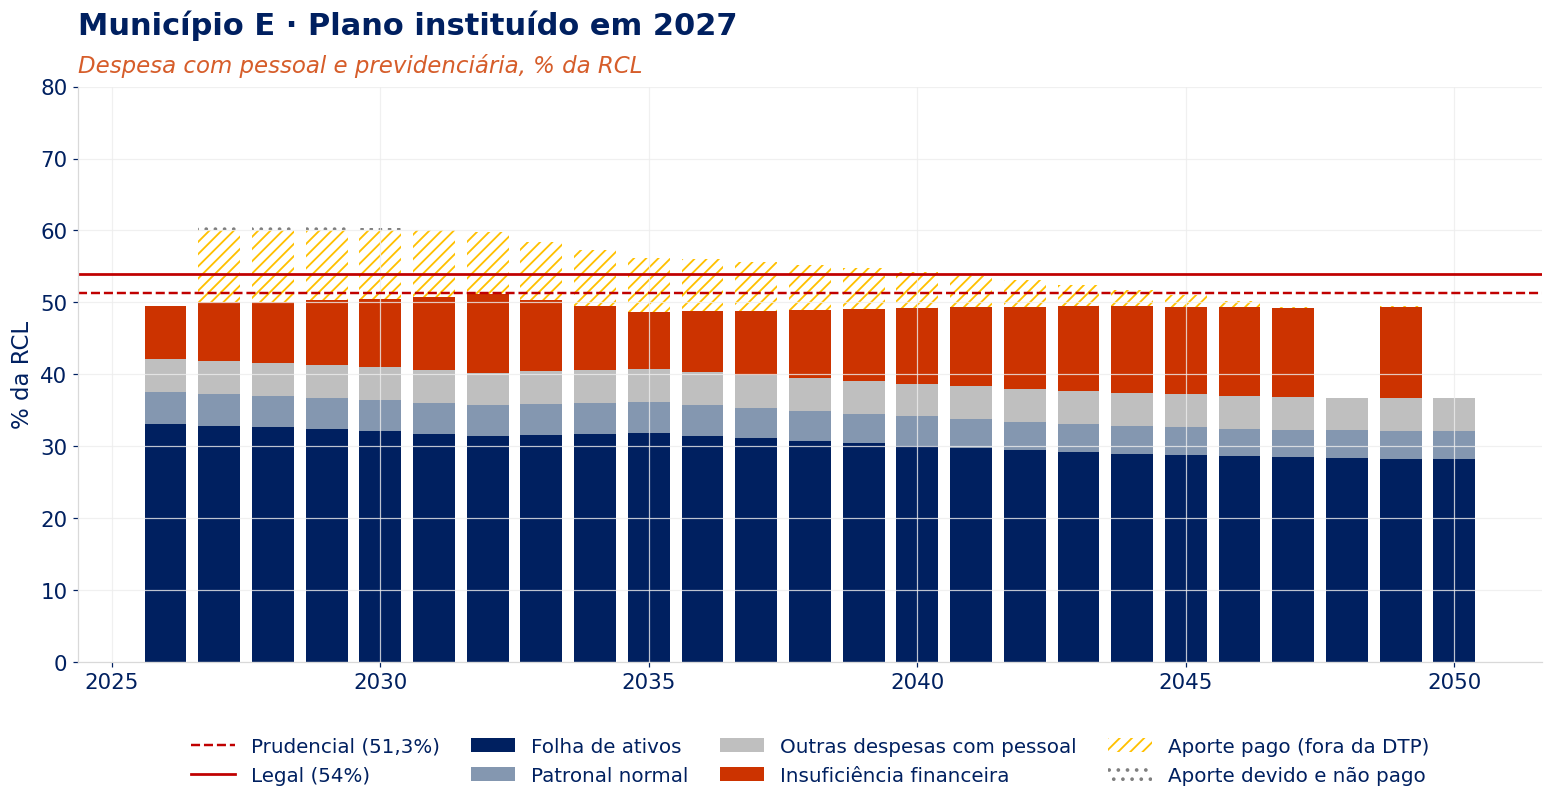

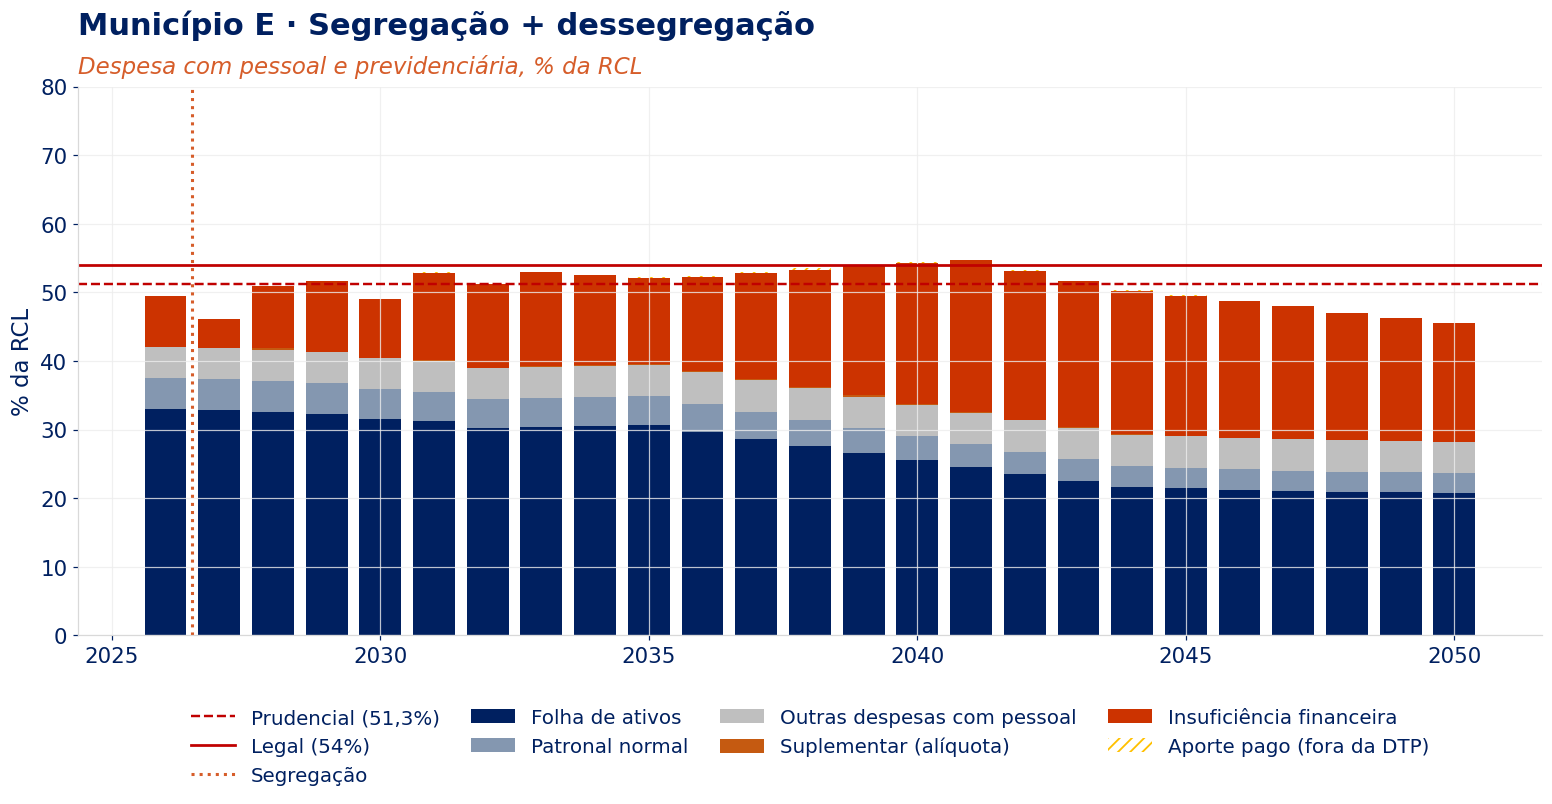

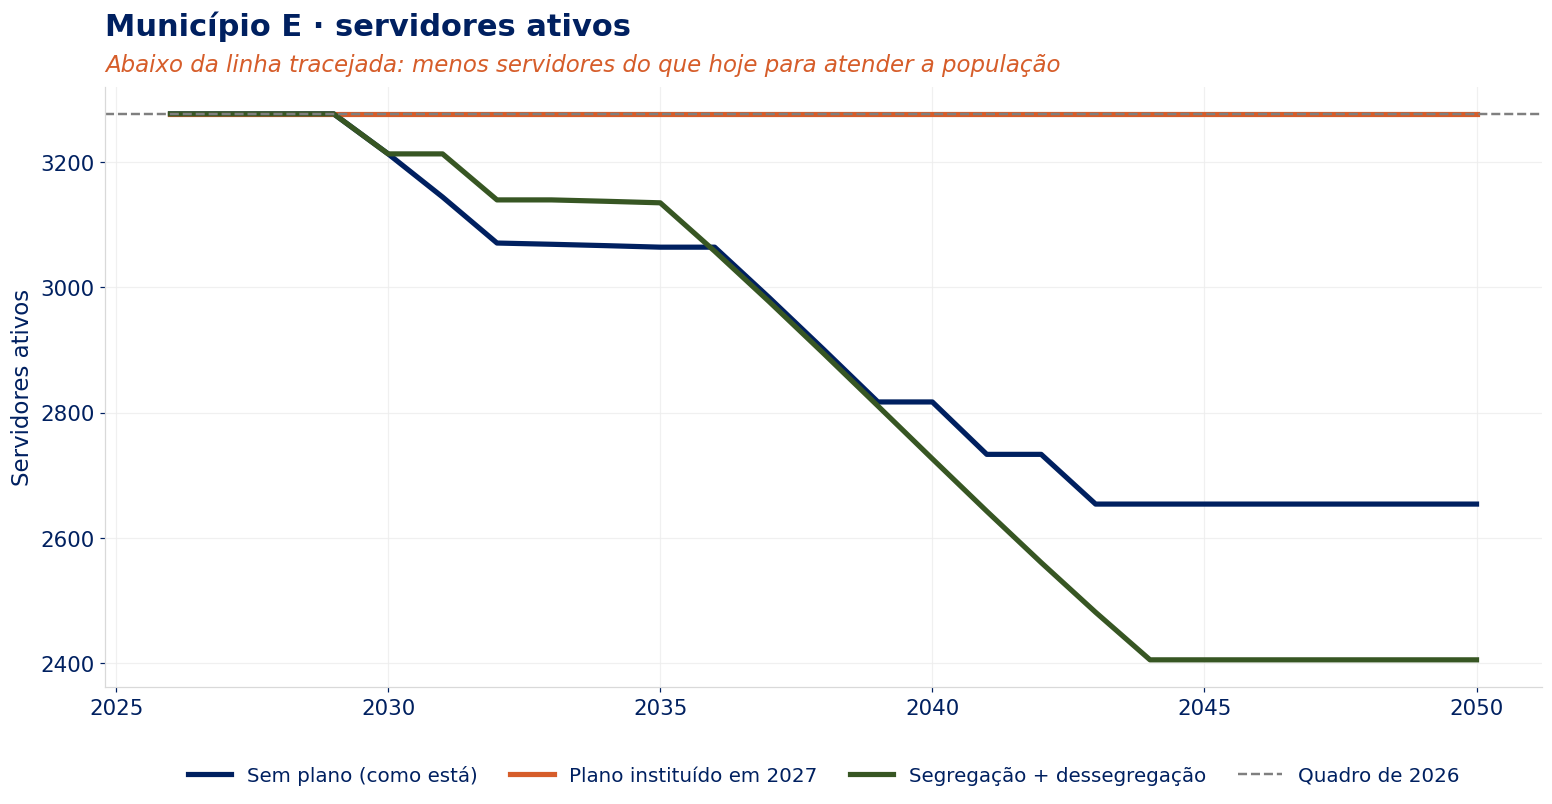

DTP (% RCL)  comprometimento (% RCL)  \
cenário                    ano                                          
Sem plano (como está)      2027       50.000                   50.000   
                           2030       51.700                   51.700   
                           2040       51.600                   51.600   
                           2050       49.900                   49.900   
Plano instituído em 2027   2027       50.000                   60.000   
                           2030       50.500                   60.000   
                           2040       49.200                   54.200   
                           2050       36.600                   36.600   
Segregação + dessegregação 2027       46.100                   46.100   
                           2030       49.100                   49.100   
                           2040       54.300                   54.400   
                           2050       45.500                   45.500   

                                 insuficiência (% RCL)  aporte pago (% RCL)  \
cenário                    ano                                                
Sem plano (como está)      2027                  8.200                0.000   
                           2030                 11.300                0.000   
                           2040                 17.200                0.000   
                           2050                 19.400                0.000   
Plano instituído em 2027   2027                  8.200               10.000   
                           2030                  9.500                9.500   
                           2040                 10.500                5.000   
                           2050                  0.000                0.000   
Segregação + dessegregação 2027                  4.200                0.000   
                           2030                  8.700                0.000   
                           2040                 20.500                0.100   
                           2050                 17.300                0.000   

                                 aporte não pago (% RCL)  servidores  \
cenário                    ano                                         
Sem plano (como está)      2027                    0.000        3277   
                           2030                    0.000        3213   
                           2040                    0.000        2817   
                           2050                    0.000        2654   
Plano instituído em 2027   2027                    1.200        3277   
                           2030                    0.300        3277   
                           2040                    0.000        3277   
                           2050                    0.000        3277   
Segregação + dessegregação 2027                    0.000        3277   
                           2030                    0.000        3213   
                           2040                    0.000        2726   
                           2050                    0.000        2405   

                                 nomeados pela troca (acum.)  \
cenário                    ano                                 
Sem plano (como está)      2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0   
Plano instituído em 2027   2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0   
Segregação + dessegregação 2027                            0   
                           2030                            0   
                           2040                            0   
                           2050                            0  

,marco,ano
0,DTP acima do alerta,2026
1,DTP acima do prudencial (reposição restrita em...,2029
2,Custeio passa (total ou parcialmente) a aporte,—
3,Aporte devido não é pago integralmente,—
4,Insuficiência no FC enquanto há aporte em carê...,—
5,DTP acima do limite legal,—
6,Comprometimento total (DTP + aporte) acima de ...,—
7,"Endividamento com déficit acima de 1,2 × RCL",2026
8,Primeiro superávit do FC,—
9,Primeira dessegregação,—


In [31]:
def cenarios_municipio(p):
    n = p["nome"]
    if n == "Município A":
        return {"Sem segregação": cenario(p, f"{n} · sem segregação"),
                "Segregação": cenario(p, f"{n} · segregação", segregar=True),
                "Segregação + dessegregação": cenario(p, f"{n} · seg. + desseg.", segregar=True, desseg=True)}
    if n == "Município B":
        return {"Segregado, como está": cenario(p, f"{n} · como está"),
                "Com dessegregação": cenario(p, f"{n} · com dessegregação", desseg=True)}
    if n == "Município C":
        return {"Plano vigente (aportes da lei)": cenario(p, f"{n} · plano vigente"),
                "Segregação": cenario(p, f"{n} · segregação", segregar=True, plano_fixo=False),
                "Segregação + dessegregação": cenario(p, f"{n} · seg. + desseg.", segregar=True, desseg=True, plano_fixo=False)}
    if n == "Município D":
        return {"Plano vigente (alíquota da lei)": cenario(p, f"{n} · plano vigente"),
                "Segregação": cenario(p, f"{n} · segregação", segregar=True, plano_fixo=False),
                "Segregação + dessegregação": cenario(p, f"{n} · seg. + desseg.", segregar=True, desseg=True, plano_fixo=False)}
    if n == "Município E":
        return {"Sem plano (como está)": cenario(p, f"{n} · sem plano"),
                "Plano instituído em 2027": cenario(p, f"{n} · plano em 2027", ano_plano=1, forma0="aporte"),
                "Segregação + dessegregação": cenario(p, f"{n} · seg. + desseg.", ano_plano=1,
                                                      segregar=True, desseg=True)}


# Município A entra primeiro, com o cenário já calibrado na seção 5 (MUN_A_PROJ)
MUNS = {"Município A": MUN_A_PROJ, **{k: v for k, v in MUNS.items() if k != "Município A"}}

RES = {}

for n, p in MUNS.items():
    cs = cenarios_municipio(p)
    RES[n] = {k: simular(c) for k, c in cs.items()}
    print(f"\n=== {n}")
    ax = grafico_comparativo(RES[n], p)
    titulo(ax, n, "Comprometimento da RCL: despesa com pessoal + aporte")
    salvar(f"{n.split()[-1]}_comparativo"); plt.show()
    for k, c in cs.items():
        grafico_composicao(RES[n][k], c, titulo=f"{n} · {k}")
        salvar(f"{n.split()[-1]}_{k}"); plt.show()
    ax = grafico_servidores(RES[n], p)
    titulo(ax, f"{n} · servidores ativos",
           "Abaixo da linha tracejada: menos servidores do que hoje para atender a população")
    salvar(f"{n.split()[-1]}_servidores"); plt.show()
    display(numeros_palestra(RES[n]))
    display(marcos(RES[n][list(cs)[0]], cs[list(cs)[0]]))

### Município E: o déficit que não aparece na despesa com pessoal
Sem plano, a despesa com pessoal fica baixa — mas o déficit atuarial cresce. O endividamento com o déficit
(Anexo VI, art. 51, III) mostra o que a DTP esconde.

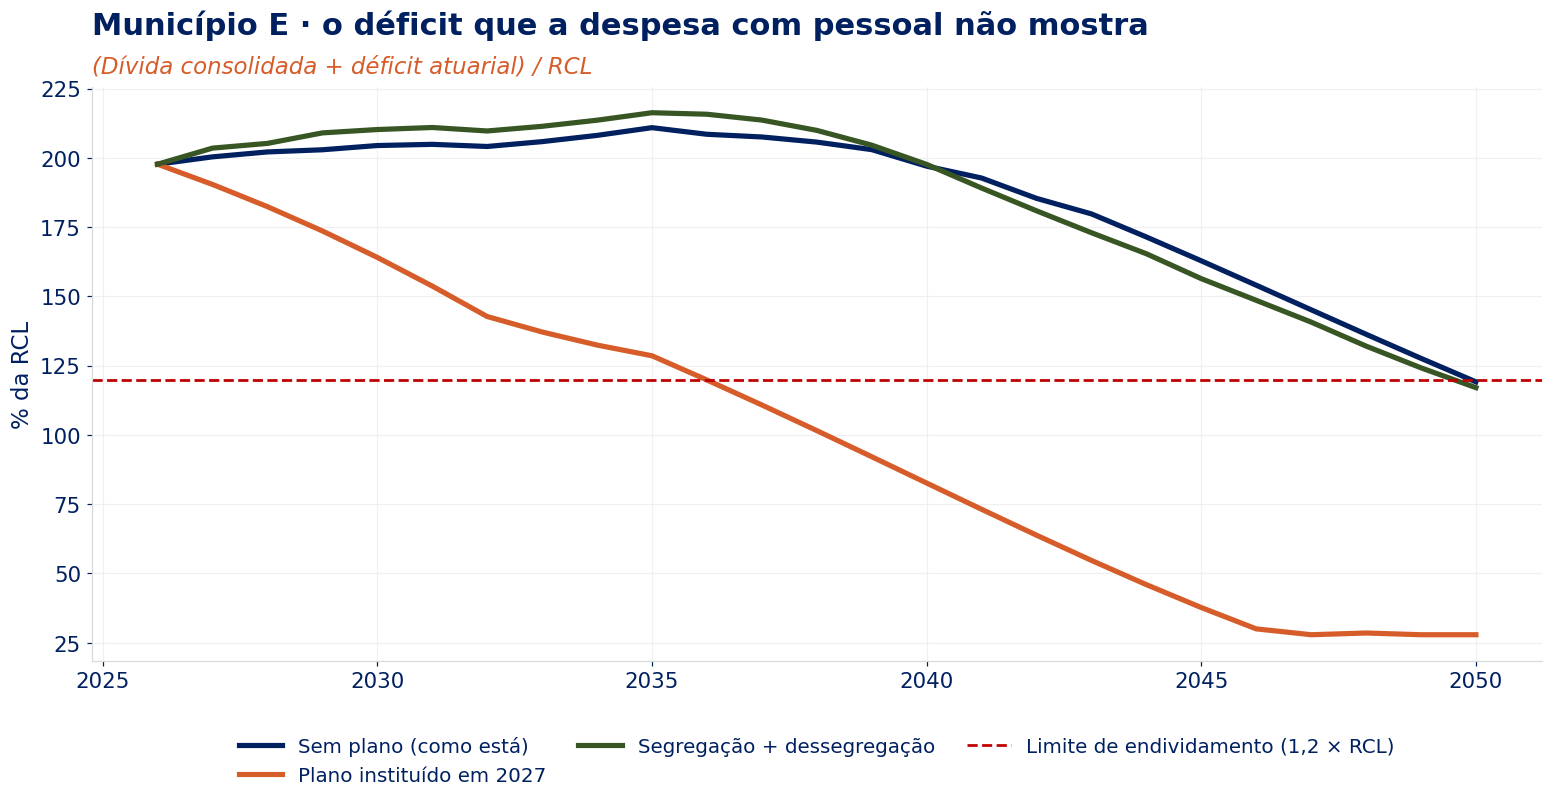

In [32]:
fig, ax = plt.subplots(figsize=FIG)
for (rot, df), c in zip(RES["Município E"].items(), SERIES):
    d = df[df.ano <= 2050]
    ax.plot(d.ano, d.endiv * 100, color=c, lw=3.4, label=rot)
ax.axhline(120, color=LIMITE, ls="--", lw=1.8, label="Limite de endividamento (1,2 × RCL)")
ax.set_ylabel("% da RCL")
titulo(ax, "Município E · o déficit que a despesa com pessoal não mostra",
       "(Dívida consolidada + déficit atuarial) / RCL")
legenda_abaixo(ax, ncol=3)
salvar("E_endividamento")
plt.show()

### Painel síntese: comprometimento médio 2027–2050 por município e cenário

In [33]:
linhas = []
for n, rr in RES.items():
    for rot, df in rr.items():
        d = df[(df.ano >= 2027) & (df.ano <= 2050)]
        linhas.append(dict(município=n, cenário=rot,
                           comprometimento_medio=d.comprometimento.mean(),
                           dtp_max=d.dtp_rcl.max(),
                           anos_acima_prudencial=int((d.dtp_rcl > BASE["lim_prud"]).sum()),
                           endiv_2050=d.endiv.iloc[-1]))
display(pd.DataFrame(linhas).set_index(["município", "cenário"]).round(3))

comprometimento_medio  dtp_max  \
município   cenário                                                           
Município A Sem segregação                                   0.525    0.493   
            Segregação                                       0.517    0.558   
            Segregação + dessegregação                       0.497    0.544   
Município B Segregado, como está                             0.513    0.546   
            Com dessegregação                                0.505    0.546   
Município C Plano vigente (aportes da lei)                   0.588    0.483   
            Segregação                                       0.516    0.557   
            Segregação + dessegregação                       0.495    0.530   
Município D Plano vigente (alíquota da lei)                  0.399    0.407   
            Segregação                                       0.418    0.445   
            Segregação + dessegregação                       0.405    0.428   
Município E Sem plano (como está)                            0.513    0.524   
            Plano instituído em 2027                         0.538    0.512   
            Segregação + dessegregação                       0.509    0.547   

                                             anos_acima_prudencial  endiv_2050  
município   cenário                                                             
Município A Sem segregação                                       0       0.348  
            Segregação                                          14       0.626  
            Segregação + dessegregação                          13       0.394  
Município B Segregado, como está                                12       1.274  
            Com dessegregação                                   12       1.186  
Município C Plano vigente (aportes da lei)                       0       0.061  
            Segregação                                          13       1.340  
            Segregação + dessegregação                          11       1.160  
Município D Plano vigente (alíquota da lei)                      0       0.593  
            Segregação                                           0       0.598  
            Segregação + dessegregação                           0       0.454  
Município E Sem plano (como está)                               11       1.192  
            Plano instituído em 2027                             0       0.279  
            Segregação + dessegregação                          13       1.171

### Regra do TCE: anos sem equilíbrio atuarial (estoque do fundo intocável) e insuficiência do FC

In [34]:
display(tabela_saques(RES).round(3))

anos_sem_equilibrio  \
município   cenário                                                
Município A Sem segregação                                    29   
            Segregação                                         3   
            Segregação + dessegregação                         7   
Município B Segregado, como está                               6   
            Com dessegregação                                  6   
Município C Plano vigente (aportes da lei)                    18   
            Segregação                                         3   
            Segregação + dessegregação                         3   
Município D Plano vigente (alíquota da lei)                   25   
            Segregação                                         2   
            Segregação + dessegregação                         4   
Município E Sem plano (como está)                             25   
            Plano instituído em 2027                          23   
            Segregação + dessegregação                        17   

                                             insuf_FC_media_rcl  
município   cenário                                              
Município A Sem segregação                                0.010  
            Segregação                                    0.000  
            Segregação + dessegregação                    0.000  
Município B Segregado, como está                          0.000  
            Com dessegregação                             0.000  
Município C Plano vigente (aportes da lei)                0.083  
            Segregação                                    0.007  
            Segregação + dessegregação                    0.007  
Município D Plano vigente (alíquota da lei)               0.014  
            Segregação                                    0.001  
            Segregação + dessegregação                    0.001  
Município E Sem plano (como está)                         0.154  
            Plano instituído em 2027                      0.094  
            Segregação + dessegregação                    0.008

### Município D · o motor: mais servidores com o mesmo dinheiro

**Por que o D não consegue nomear.** No plano vigente, a alíquota suplementar de 49,5% incide sobre **toda a folha**,
inclusive sobre quem for nomeado amanhã. Cada R$ 1 de salário novo custa ao ente cerca de **R$ 1,77**
(salário + 27,25% de patronal normal + 49,5% de suplementar). Nomear fica caro justamente porque o passivo antigo é
cobrado sobre a folha nova.

**O que a segregação muda.** O passivo antigo vai para o fundo em repartição e passa a ser pago como insuficiência,
sobre a massa antiga. O novo servidor entra no fundo em capitalização e custa só **salário + patronal normal**.
Com o mesmo real, nomeia-se mais gente — e gente de geração G3, com perfil atuarial favorável, que ainda alimenta a
dessegregação.

**Três alavancas, simuladas em sequência:**
1. **Troca:** metade das outras despesas com pessoal (contratos, celetistas e afins) vira nomeação de efetivos em
   5 anos, com orçamento neutro.
2. **Segregação + dessegregação:** reduz o custo de cada nova nomeação.
3. **Reinvestimento da economia:** o ente mantém o mesmo comprometimento da RCL do plano vigente e usa o que
   sobrar para nomear, sem passar de 1 p.p. abaixo do limite prudencial.

A troca e o reinvestimento só avançam em anos sem reposição restrita (LRF, art. 22, parágrafo único, IV).
Ressalva para a palestra: nem tudo em "outras despesas com pessoal" pode ser trocado (terceirizações necessárias,
contratos emergenciais). Por isso a metade.

,custo de R$ 1 de salário novo (R$),novos servidores por R$ 1 mi/ano
cenário,,
Plano vigente,1.770,11.300
Plano vigente + troca,1.770,11.300
Seg. + desseg. + troca,1.220,16.300
Seg. + desseg. + troca + economia reinvestida,1.220,16.300


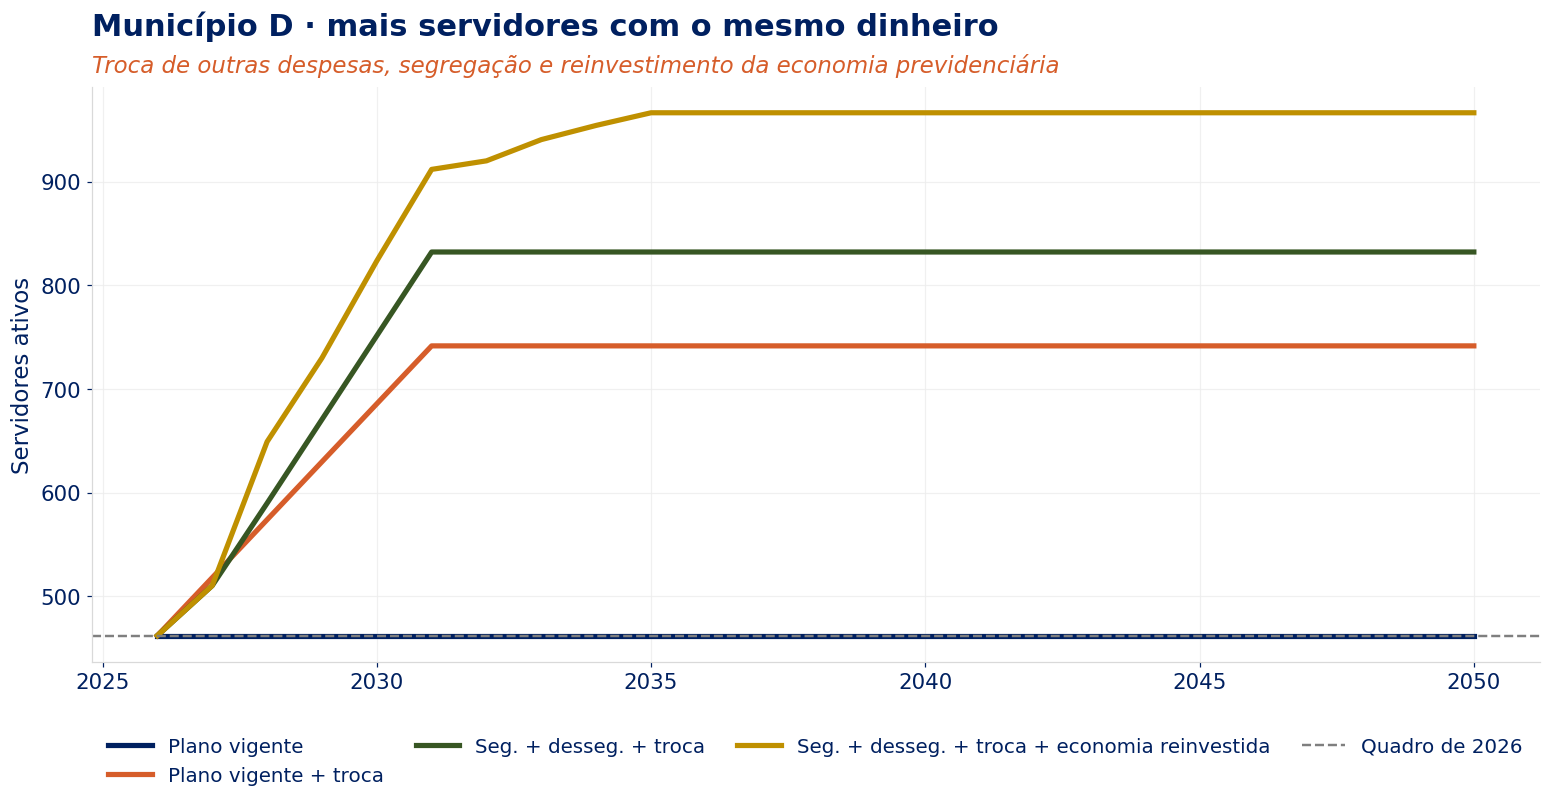

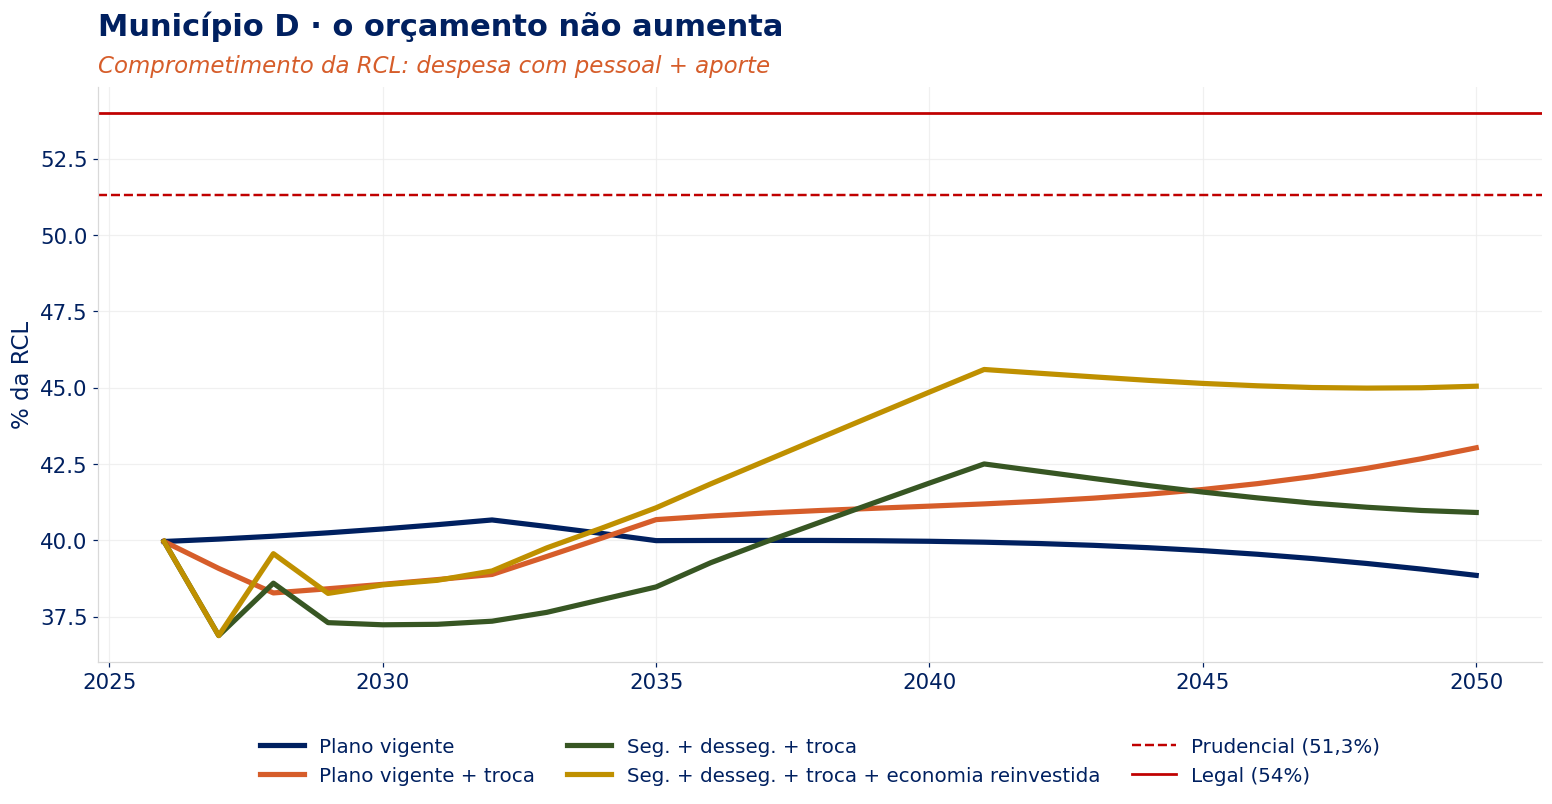

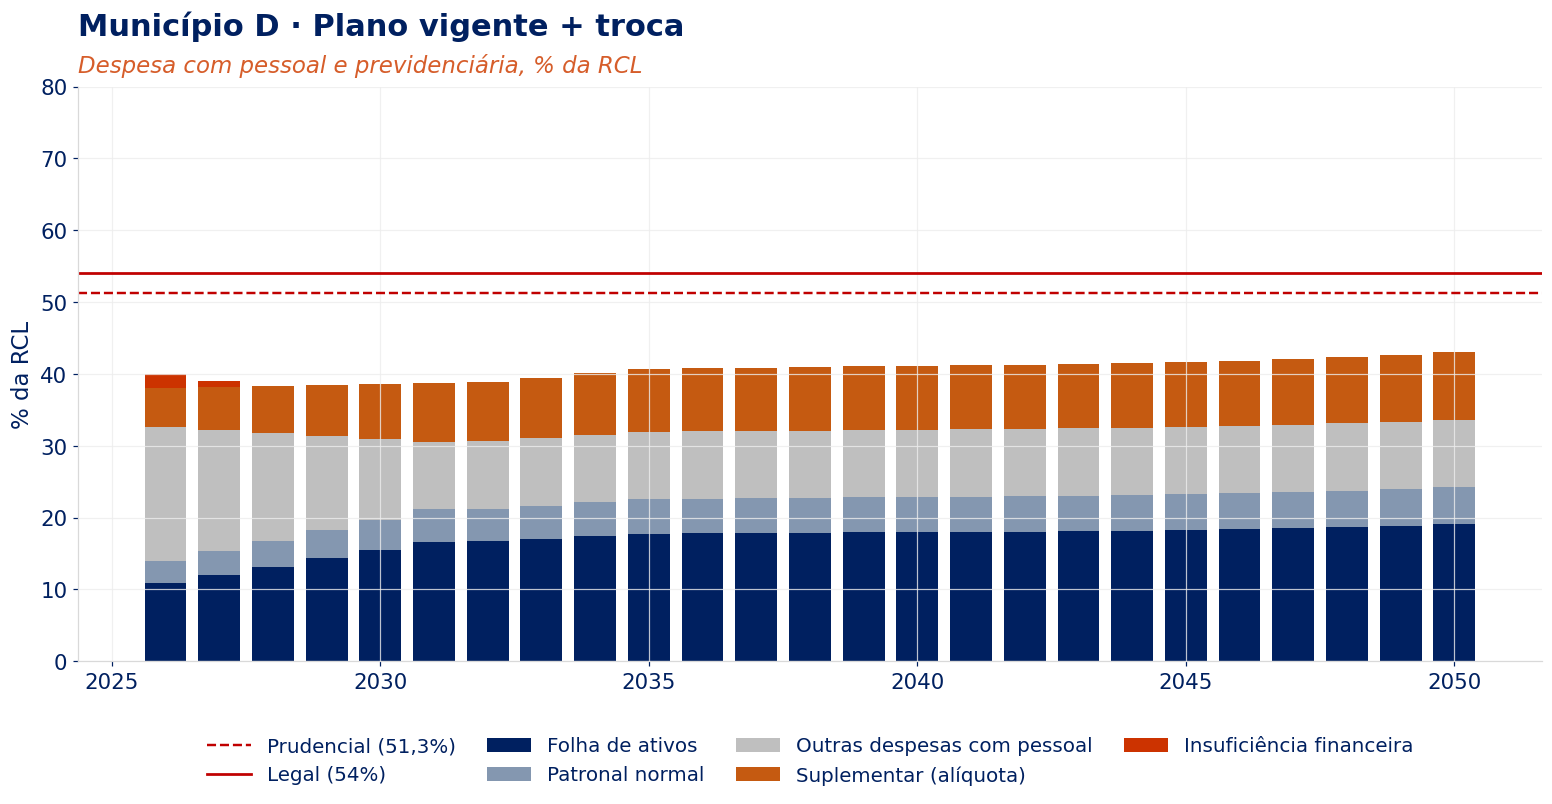

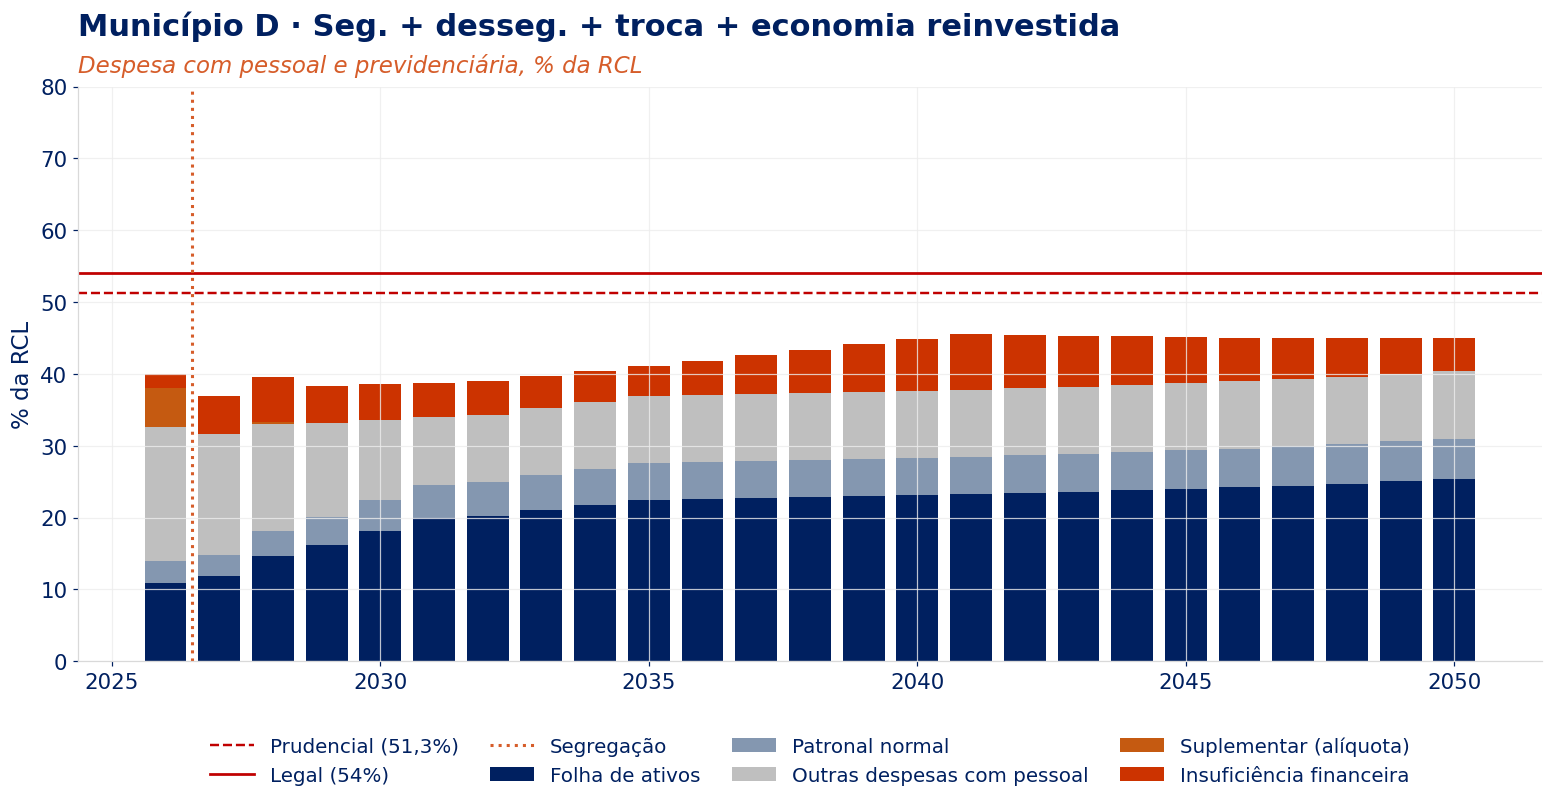

DTP (% RCL)  \
cenário                                       ano                 
Plano vigente                                 2027       40.000   
                                              2030       40.400   
                                              2040       40.000   
                                              2050       38.900   
Plano vigente + troca                         2027       39.100   
                                              2030       38.600   
                                              2040       41.100   
                                              2050       43.000   
Seg. + desseg. + troca                        2027       36.900   
                                              2030       37.200   
                                              2040       41.900   
                                              2050       40.900   
Seg. + desseg. + troca + economia reinvestida 2027       36.900   
                                              2030       38.500   
                                              2040       44.900   
                                              2050       45.000   

                                                    comprometimento (% RCL)  \
cenário                                       ano                             
Plano vigente                                 2027                   40.000   
                                              2030                   40.400   
                                              2040                   40.000   
                                              2050                   38.900   
Plano vigente + troca                         2027                   39.100   
                                              2030                   38.600   
                                              2040                   41.100   
                                              2050                   43.000   
Seg. + desseg. + troca                        2027                   36.900   
                                              2030                   37.200   
                                              2040                   41.900   
                                              2050                   40.900   
Seg. + desseg. + troca + economia reinvestida 2027                   36.900   
                                              2030                   38.500   
                                              2040                   44.900   
                                              2050                   45.000   

                                                    insuficiência (% RCL)  \
cenário                                       ano                           
Plano vigente                                 2027                  1.900   
                                              2030                  2.000   
                                              2040                  1.100   
                                              2050                  0.700   
Plano vigente + troca                         2027                  0.900   
                                              2030                  0.000   
                                              2040                  0.000   
                                              2050                  0.000   
Seg. + desseg. + troca                        2027                  5.200   
                                              2030                  5.300   
                                              2040                  7.900   
                                              2050                  5.100   
Seg. + desseg. + troca + economia reinvestida 2027                  5.200   
                                              2030                  4.900   
                                              2040                  7.200   
                                              2050                  4.700   

                                   

In [35]:
FRAC_TROCA = 0.5

def cenarios_D(p):
    cs = cenarios_municipio(p)
    vig, seg = cs["Plano vigente (alíquota da lei)"], cs["Segregação + dessegregação"]
    ref = simular(cenario(vig, troca_outras=FRAC_TROCA))
    alvo = dict(zip(ref.ano, ref.comprometimento))
    return {
        "Plano vigente": vig,
        "Plano vigente + troca": cenario(vig, "Município D · vigente + troca", troca_outras=FRAC_TROCA),
        "Seg. + desseg. + troca": cenario(seg, "Município D · seg. + troca", troca_outras=FRAC_TROCA),
        "Seg. + desseg. + troca + economia reinvestida": cenario(seg, "Município D · seg. + troca + reinvest.",
                                                                 troca_outras=FRAC_TROCA, reinvestir=True,
                                                                 alvo_comprometimento=alvo),
    }

pD = MUNS["Município D"]
CS_D = cenarios_D(pD)
RES_TROCA = {"Município D": {k: simular(c) for k, c in CS_D.items()}}
RD = RES_TROCA["Município D"]

# custo de um novo servidor, por regime
custo = pd.DataFrame([
    {"cenário": k, "custo de R$ 1 de salário novo (R$)": round(df[df.ano == 2028].fator_custo_novo.iloc[0], 2),
     "novos servidores por R$ 1 mi/ano": round(df[df.ano == 2028].servidores_por_milhao.iloc[0], 1)}
    for k, df in RD.items()]).set_index("cenário")
display(custo)

ax = grafico_servidores(RD, pD)
titulo(ax, "Município D · mais servidores com o mesmo dinheiro",
       "Troca de outras despesas, segregação e reinvestimento da economia previdenciária")
salvar("D_troca_servidores"); plt.show()

ax = grafico_comparativo(RD, pD)
titulo(ax, "Município D · o orçamento não aumenta", "Comprometimento da RCL: despesa com pessoal + aporte")
salvar("D_troca_comparativo"); plt.show()

for k in ("Plano vigente + troca", "Seg. + desseg. + troca + economia reinvestida"):
    grafico_composicao(RD[k], CS_D[k], titulo=f"Município D · {k}")
    salvar(f"D_{k}"); plt.show()

display(numeros_palestra(RD))